# 01 — Análise Exploratória de Dados

**Dimensão 3 da rúbrica — 20 pontos.**

Toda visualização precisa de um parágrafo de interpretação logo abaixo.
Gráfico sem leitura perde metade dos pontos do critério.

In [ ]:
# @title
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# @title
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
import glob

# 1. Semente fixa: use em TODO ponto com aleatoriedade (split, modelos, CV).
RANDOM_STATE = 42

# 2. Caminho da sua pasta RAW no Google Drive
RAW = Path("./content/drive/MyDrive/postech-tech-challenge-fase2-template/data/raw/")         # PREENCHER: nome do arquivo

# 3. Caminho da sua pasta PROCESSED no Google Drive
PROCESSED = Path("./content/drive/MyDrive/postech-tech-challenge-fase2-template/data/processed/") # PREENCHER: nome do diretório

#TARGET = "target"                                            # PREENCHER: variável alvo

#pd.set_option("display.max_columns", None)

In [ ]:
# @title
import os
import glob
import pandas as pd

# 1. Garanta o caminho correto (ajuste o nome se o passo 1 mostrou algo diferente)
RAW = '/content/drive/MyDrive/postech-tech-challenge-fase2-template/data/raw'

# 2. Verifica se a pasta realmente existe antes de buscar
if not os.path.exists(RAW):
    print(f"❌ ERRO: A pasta '{RAW}' não foi encontrada! Verifique o nome dela no seu Drive.")
else:
    # 3. Busca os arquivos ignorando barras extras no final
    arquivos_csv = glob.glob(os.path.join(RAW, "*.csv"))

    if len(arquivos_csv) == 0:
        print(f"⚠️ A pasta foi encontrada, mas está VAZIA ou não contém arquivos .csv.")
        print(f"Conteúdo atual da pasta raw: {os.listdir(RAW)}")
    else:
        # 4. Cria os DataFrames se encontrar os arquivos
        dataframes = {}
        for arquivo in arquivos_csv:
            nome_df = os.path.splitext(os.path.basename(arquivo))[0]
            dataframes[nome_df] = pd.read_csv(arquivo)
            print(f"✅ DataFrame '{nome_df}' criado! Formato: {dataframes[nome_df].shape}")


✅ DataFrame 'application_record' criado! Formato: (438557, 18)
✅ DataFrame 'credit_record' criado! Formato: (1048575, 3)


## 1.1 Visão geral

_Dimensões, tipos e primeira impressão do dataset._

**Interpretação:** O `df_application` possui **438.557 observações e 18 variáveis**. Os tipos de dados incluem inteiros `int64`, números de ponto flutuante `float64` e strings `object`. Verificamos que o dataset **possui valores nulos** e **sem linhas duplicadas**, porém com **ID duplicados**.

O `df_credit` possui **1.048.575 observações e 3 variáveis**. Os tipos de dados incluem inteiros `int64`, e string `object`. Após o merge e tratamento inicial, verificou-se que o dataset **não possui valores nulos nem linhas duplicadas**,

A expressiva volumetria do dataset garante uma base robusta para a continuidade da análise.

In [ ]:
# Carregando application_record.csv
application_df = dataframes['application_record']
display(application_df.head())

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [ ]:
print(f"Dataset carregado! Formato: {application_df.shape}")

Dataset carregado! Formato: (438557, 18)


In [ ]:
application_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL       

In [ ]:
# estatíticas descritivas
application_df.drop(columns=['ID']).describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
CNT_CHILDREN,438557.0,0.43,0.72,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,438557.0,187524.29,110086.85,26100.0,121500.0,160780.5,225000.0,6750000.0
DAYS_BIRTH,438557.0,-15997.90,4185.03,-25201.0,-19483.0,-15630.0,-12514.0,-7489.0
DAYS_EMPLOYED,438557.0,60563.68,138767.80,-17531.0,-3103.0,-1467.0,-371.0,365243.0
FLAG_MOBIL,438557.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0
FLAG_WORK_PHONE,438557.0,0.21,0.40,0.0,0.0,0.0,0.0,1.0
FLAG_PHONE,438557.0,0.29,0.45,0.0,0.0,0.0,1.0,1.0
FLAG_EMAIL,438557.0,0.11,0.31,0.0,0.0,0.0,0.0,1.0
CNT_FAM_MEMBERS,438557.0,2.19,0.90,1.0,2.0,2.0,3.0,20.0


In [ ]:
# Verificar números de linhas duplicadas
num_duplicados = application_df.duplicated().sum()
print(f"Número de linhas duplicadas em df_application: {num_duplicados}")

Número de linhas duplicadas em df_application: 0


In [ ]:
# Carrregando credit_record.csv
credit_df = dataframes['credit_record']

display(credit_df.head())

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [ ]:
print(f"Dataset carregado! Formato: {credit_df.shape}")

Dataset carregado! Formato: (1048575, 3)


In [ ]:
display(credit_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 3 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   ID              1048575 non-null  int64 
 1   MONTHS_BALANCE  1048575 non-null  int64 
 2   STATUS          1048575 non-null  object
dtypes: int64(2), object(1)
memory usage: 24.0+ MB


None

In [ ]:
# estatíticas descritivas
credit_df.drop(columns=['ID']).describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
MONTHS_BALANCE,1048575.0,-19.14,14.02,-60.0,-29.0,-17.0,-7.0,0.0


## 1.2 Construção do TARGET com janela de até 12 meses
## Exclusão de clientes com somente STATUS = "X"

Para definição do TARGET em relação a inadimplência utilizamos até os 12 meses mais recentes disponíveis de cada cliente. Clientes com menos de 12 meses são avaliados com todos os registros disponíveis.

Clientes cuja janela contém exclusivamente STATUS = "X" são excluídos, pois esse código representa ausência de crédito ativo e não fornece evidência suficiente sobre o comportamento de pagamento. Clientes com alguns meses X, mas também com C, 0 ou status de 1 a 5, permanecem na base.

### Definição adotada
- TARGET = 0: não houve atraso igual ou superior a 30 dias;
- TARGET = 1: houve pelo menos um atraso igual ou superior a 30 dias;
- somente STATUS = "X": cliente excluído por ausência de comportamento observável.

Os códigos de 1 a 5 representam atraso de 30 dias ou mais. O código 0, correspondente a atraso de 1 a 29 dias, não classifica o cliente como mau pagador.

In [ ]:
# Valida a estrutura e a consistência inicial
colunas_credito_obrigatorias = {"ID", "MONTHS_BALANCE", "STATUS"}
colunas_aplicacao_obrigatorias = {"ID"}

faltantes_credito = colunas_credito_obrigatorias - set(credit_df.columns)
assert not faltantes_credito, f"Colunas ausentes em credit_record: {faltantes_credito}"

# Validações de valores nulos no DataFrame original
assert credit_df["ID"].notna().all(), "Há valores nulos em ID."
assert credit_df["MONTHS_BALANCE"].notna().all(), "Há nulos em MONTHS_BALANCE."
assert credit_df["STATUS"].notna().all(), "Há valores nulos em STATUS."

# Limpeza de espaços em branco na coluna STATUS
credit_df["STATUS"] = credit_df["STATUS"].astype(str).str.strip()

# Verificação de status válidos
status_validos = {"0", "1", "2", "3", "4", "5", "C", "X"}
status_encontrados = set(credit_df["STATUS"].unique())
status_inesperados = status_encontrados - status_validos

print("Status encontrados:", sorted(status_encontrados))
print("Status inesperados:", sorted(status_inesperados))
assert not status_inesperados, f"Foram encontrados status inesperados: {status_inesperados}"

duplicatas_mensais = credit_df.duplicated(subset=["ID", "MONTHS_BALANCE"], keep=False).sum()
print("Linhas duplicadas por ID e MONTHS_BALANCE:", duplicatas_mensais)

# Existência de duplicidades mensais
assert duplicatas_mensais == 0, (
    "Existem registros duplicados para a mesma combinação "
    "de ID e MONTHS_BALANCE."
)

# Ordena os registros do mês mais recente para o mais antigo
credit_diagnostico = credit_df.sort_values(
    by=["ID", "MONTHS_BALANCE"],
    ascending=[True, False]
).copy()

# Calcula a diferença entre os meses registrados de cada cliente
credit_diagnostico["DIFERENCA_MES"] = (
    credit_diagnostico
    .groupby("ID")["MONTHS_BALANCE"]
    .diff()
    .abs()
)

# Identifica diferenças diferentes de 1 entre meses sucessivos
mascara_lacuna = (
    credit_diagnostico["DIFERENCA_MES"].notna()
    & credit_diagnostico["DIFERENCA_MES"].ne(1)
)

# Conta quantos clientes possuem pelo menos uma lacuna
clientes_com_lacunas = (
    credit_diagnostico.loc[
        mascara_lacuna,
        "ID"
    ]
    .nunique()
)

print(
    "Clientes com lacunas mensais:",
    clientes_com_lacunas
)

# Interrompe a execução se existirem lacunas
assert clientes_com_lacunas == 0, (
    "Existem clientes com lacunas mensais no histórico."
)

print(
    "Não foram encontradas duplicidades nem lacunas mensais."
)

print("Validação inicial concluída com sucesso.")


Status encontrados: ['0', '1', '2', '3', '4', '5', 'C', 'X']
Status inesperados: []
Linhas duplicadas por ID e MONTHS_BALANCE: 0
Clientes com lacunas mensais: 0
Não foram encontradas duplicidades nem lacunas mensais.
Validação inicial concluída com sucesso.


In [ ]:
# Calcula a distribuição dos códigos de status
resumo_status = credit_df["STATUS"].value_counts(dropna=False).rename("quantidade").to_frame()
resumo_status["proporcao"] = credit_df["STATUS"].value_counts(normalize=True, dropna=False)
display(resumo_status)

,quantidade,proporcao
STATUS,,
C,442031,0.421554
0,383120,0.365372
X,209230,0.199537
1,11090,0.010576
5,1693,0.001615
2,868,0.000828
3,320,0.000305
4,223,0.000213


### a) Parâmetros da construção do TARGET

Definição da janela máxima e dos status considerados como atraso de 30 dias ou mais.

In [ ]:
# Define a janela e os status de mau pagador
JANELA_MESES = 12
STATUS_MAU_PAGADOR = ["1", "2", "3", "4", "5"]
print("Janela máxima:", JANELA_MESES, "meses")
print("Status de mau pagador:", STATUS_MAU_PAGADOR)

Janela máxima: 12 meses
Status de mau pagador: ['1', '2', '3', '4', '5']


### b) TARGET_EVER considerando todo o histórico

Criação do TARGET_EVER e identificação dos clientes com histórico completo somente X.

In [ ]:
# Constrói o TARGET_EVER
credit_completo = credit_df.copy()
credit_completo["BAD_MENSAL"] = credit_completo["STATUS"].isin(STATUS_MAU_PAGADOR).astype(int)
credit_completo["CREDITO_OBSERVAVEL"] = credit_completo["STATUS"].ne("X").astype(int)
target_ever = credit_completo.groupby("ID", as_index=False).agg(TARGET_EVER=("BAD_MENSAL", "max"), MESES_HISTORICO_TOTAL=("MONTHS_BALANCE", "nunique"), MESES_COM_CREDITO_EVER=("CREDITO_OBSERVAVEL", "sum"))
target_ever["SOMENTE_X_EVER"] = target_ever["MESES_COM_CREDITO_EVER"].eq(0)
print("Clientes no TARGET_EVER:", len(target_ever))
print("Clientes somente com X em todo o histórico:", target_ever["SOMENTE_X_EVER"].sum())

Clientes no TARGET_EVER: 45985
Clientes somente com X em todo o histórico: 4536


### c) TARGET considerando histórico de 12 mese

Criação do TARGET e identificação dos clientes...

In [ ]:
# Ordena os registros e seleciona até 12 meses
credit_ordenado = credit_df.sort_values(by=["ID", "MONTHS_BALANCE"], ascending=[True, False]).copy()
credit_ordenado["ORDEM_MES"] = credit_ordenado.groupby("ID").cumcount().add(1)
credit_janela = credit_ordenado.loc[credit_ordenado["ORDEM_MES"] <= JANELA_MESES].copy()
print("Linhas no histórico completo:", len(credit_df))
print("Linhas na janela:", len(credit_janela))
print("Clientes na janela:", credit_janela["ID"].nunique())

Linhas no histórico completo: 1048575
Linhas na janela: 476530
Clientes na janela: 45985


In [ ]:
# Confirma a quantidade de meses selecionados
meses_por_cliente = (
    credit_janela
    .groupby("ID")["MONTHS_BALANCE"]
    .nunique()
)

assert meses_por_cliente.between(
    1,
    JANELA_MESES
).all(), (
    "Existem clientes com quantidade inválida de meses na janela."
)

assert credit_janela["ID"].nunique() == credit_df["ID"].nunique(), (
    "A seleção da janela eliminou clientes indevidamente."
)

print(
    "Menor quantidade de meses selecionados:",
    meses_por_cliente.min()
)

print(
    "Maior quantidade de meses selecionados:",
    meses_por_cliente.max()
)

print(
    "Nenhum cliente foi eliminado pela seleção da janela."
)

Menor quantidade de meses selecionados: 1
Maior quantidade de meses selecionados: 12
Nenhum cliente foi eliminado pela seleção da janela.


Construção do TARGET e identificação das janelas sem qualquer mês de crédito observável.

In [ ]:
# Constrói o TARGET e identifica clientes somente com X
credit_janela["BAD_MENSAL"] = credit_janela["STATUS"].isin(STATUS_MAU_PAGADOR).astype(int)
credit_janela["CREDITO_OBSERVAVEL"] = credit_janela["STATUS"].ne("X").astype(int)
target_12m_completo = credit_janela.groupby("ID", as_index=False).agg(TARGET=("BAD_MENSAL", "max"), MESES_OBSERVADOS=("MONTHS_BALANCE", "nunique"), MESES_COM_CREDITO=("CREDITO_OBSERVAVEL", "sum"), MES_MAIS_ANTIGO_JANELA=("MONTHS_BALANCE", "min"), MES_MAIS_RECENTE_JANELA=("MONTHS_BALANCE", "max"))
target_12m_completo["SOMENTE_STATUS_X"] = target_12m_completo["MESES_COM_CREDITO"].eq(0)
quantidade_somente_x = int(target_12m_completo["SOMENTE_STATUS_X"].sum())
percentual_somente_x = target_12m_completo["SOMENTE_STATUS_X"].mean()
print("Clientes antes da exclusão:", len(target_12m_completo))
print("Clientes somente com STATUS X:", quantidade_somente_x)
print("Percentual somente com STATUS X:", f"{percentual_somente_x:.2%}")

Clientes antes da exclusão: 45985
Clientes somente com STATUS X: 5233
Percentual somente com STATUS X: 11.38%


Exclusão restrita aos clientes com todos os registros iguais a X. Os IDs são preservados separadamente para rastreabilidade.

In [ ]:
# Exclui clientes somente com X
ids_excluidos_somente_x = target_12m_completo.loc[target_12m_completo["SOMENTE_STATUS_X"], "ID"].copy()
target_12m = target_12m_completo.loc[~target_12m_completo["SOMENTE_STATUS_X"]].drop(columns=["SOMENTE_STATUS_X"]).reset_index(drop=True)
print("Clientes excluídos:", len(ids_excluidos_somente_x))
print("Clientes válidos após a exclusão:", len(target_12m))
display(target_12m.head())

Clientes excluídos: 5233
Clientes válidos após a exclusão: 40752


,ID,TARGET,MESES_OBSERVADOS,MESES_COM_CREDITO,MES_MAIS_ANTIGO_JANELA,MES_MAIS_RECENTE_JANELA
0,5001711,0,4,3,-3,0
1,5001712,0,12,12,-11,0
2,5001717,0,12,12,-11,0
3,5001718,1,12,10,-11,0
4,5001719,0,12,12,-11,0


Validações após a exclusão e verificação da quantidade de clientes, unicidade de clientes, limite da janela e presença de crédito observável.

In [ ]:
# Valida o TARGET após a exclusão
clientes_originais = credit_df["ID"].nunique()
clientes_target = target_12m["ID"].nunique()
clientes_esperados = clientes_originais - quantidade_somente_x
assert clientes_target == clientes_esperados, f"Esperados {clientes_esperados} clientes, encontrados {clientes_target}."
assert len(target_12m) == clientes_target, "O TARGET deve ter uma linha por cliente."
assert target_12m["MESES_OBSERVADOS"].between(1, JANELA_MESES).all()
assert target_12m["MESES_COM_CREDITO"].gt(0).all(), "Ainda existem clientes sem crédito observável."
assert not target_12m["ID"].isin(ids_excluidos_somente_x).any()
print("Clientes no histórico original:", clientes_originais)
print("Excluídos por possuírem somente X:", quantidade_somente_x)
print("Clientes válidos na definição do TARGET:", clientes_target)
print("Validações concluídas com sucesso.")

Clientes no histórico original: 45985
Excluídos por possuírem somente X: 5233
Clientes válidos na definição do TARGET: 40752
Validações concluídas com sucesso.


Verificação de que todos os IDs excluídos possuem somente X na janela.

In [ ]:
# Confere diretamente os clientes excluídos
if quantidade_somente_x > 0:
    status_excluidos = credit_janela.loc[credit_janela["ID"].isin(ids_excluidos_somente_x)].groupby("ID")["STATUS"].agg(lambda valores: set(valores))
    assert status_excluidos.apply(lambda conjunto: conjunto == {"X"}).all()
    display(status_excluidos.head().rename("STATUS_NA_JANELA").to_frame())
    print("Somente clientes com X satus na janela foram excluídos.")
else:
    print("Não foram encontrados clientes somente com X na janela.")

,STATUS_NA_JANELA
ID,
5001713,{X}
5001714,{X}
5001715,{X}
5001723,{X}
5001731,{X}


Somente clientes com X satus na janela foram excluídos.


Distribuição do TARGET válido: Quantidade e proporção de bons e maus pagadores após a exclusão.

In [ ]:
# Calcula a distribuição do TARGET válido
distribuicao_target = target_12m["TARGET"].value_counts().sort_index().rename("quantidade").to_frame()
distribuicao_target["proporcao"] = target_12m["TARGET"].value_counts(normalize=True).sort_index()
distribuicao_target = distribuicao_target.rename(index={0: "Bom pagador (0)", 1: "Mau pagador (1)"})
display(distribuicao_target)

,quantidade,proporcao
TARGET,,
Bom pagador (0),37868,0.92923
Mau pagador (1),2884,0.07077


Resumo da exposição dos clientes e distribuição por faixas de meses.

In [ ]:
# Resume a quantidade de meses observados
#display(target_12m["MESES_OBSERVADOS"].describe().to_frame("valor"))
clientes_menos_12 = target_12m["MESES_OBSERVADOS"].lt(JANELA_MESES)
print("Clientes com menos de 12 meses:", clientes_menos_12.sum())
print("Percentual com menos de 12 meses:", f"{clientes_menos_12.mean():.2%}")
print("Clientes com 12 meses:", (~clientes_menos_12).sum())
faixas = pd.cut(target_12m["MESES_OBSERVADOS"], bins=[0, 3, 6, 9, 11, 12], labels=["1 a 3 meses", "4 a 6 meses", "7 a 9 meses", "10 a 11 meses", "12 meses"], include_lowest=True)
resumo_faixas = faixas.value_counts(sort=False).rename("quantidade_clientes").to_frame()
resumo_faixas["proporcao"] = resumo_faixas["quantidade_clientes"] / len(target_12m)
display(resumo_faixas)

Clientes com menos de 12 meses: 12274
Percentual com menos de 12 meses: 30.12%
Clientes com 12 meses: 28478


,quantidade_clientes,proporcao
MESES_OBSERVADOS,,
1 a 3 meses,2259,0.055433
4 a 6 meses,3607,0.088511
7 a 9 meses,4006,0.098302
10 a 11 meses,2402,0.058942
12 meses,28478,0.698812


Análise da taxa de inadimplência conforme a quantidade de meses disponíveis.

In [ ]:
# Calcula a taxa de mau pagador por exposição
taxa_por_exposicao = target_12m.groupby("MESES_OBSERVADOS", observed=True).agg(CLIENTES=("ID", "count"), MAUS_PAGADORES=("TARGET", "sum"), TAXA_MAU_PAGADOR=("TARGET", "mean")).reset_index()
display(taxa_por_exposicao)

,MESES_OBSERVADOS,CLIENTES,MAUS_PAGADORES,TAXA_MAU_PAGADOR
0,1,286,1,0.003497
1,2,931,15,0.016112
2,3,1042,36,0.034549
3,4,1204,57,0.047342
4,5,1110,66,0.059459
5,6,1293,88,0.068059
6,7,1321,126,0.095382
7,8,1405,135,0.096085
8,9,1280,128,0.100000
9,10,1181,128,0.108383


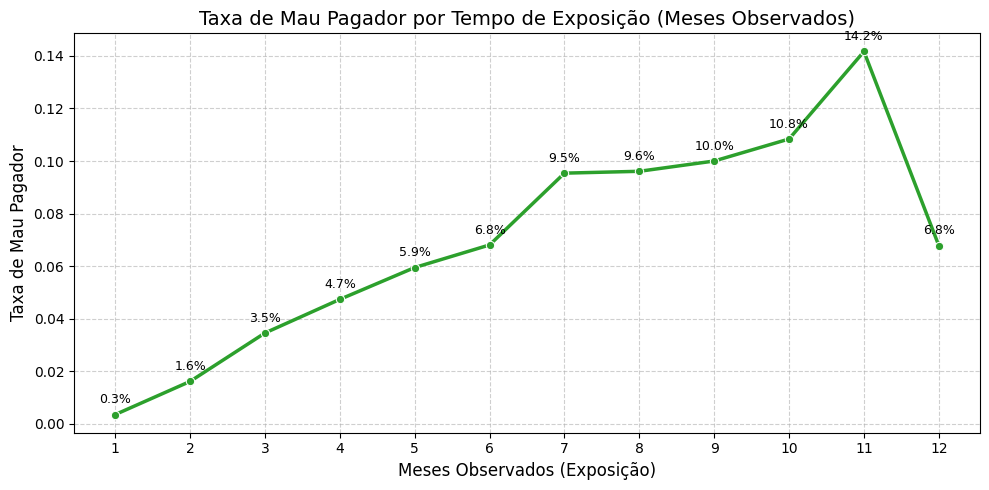

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=taxa_por_exposicao,
    x='MESES_OBSERVADOS',
    y='TAXA_MAU_PAGADOR',
    marker='o',
    linewidth=2.5,
    color='#2ca02c'
)

# Ajustes estéticos
plt.title('Taxa de Mau Pagador por Tempo de Exposição (Meses Observados)', fontsize=14)
plt.xlabel('Meses Observados (Exposição)', fontsize=12)
plt.ylabel('Taxa de Mau Pagador', fontsize=12)
plt.xticks(taxa_por_exposicao['MESES_OBSERVADOS'])
plt.grid(True, linestyle='--', alpha=0.6)

# Exibir valores acima dos pontos
for _, row in taxa_por_exposicao.iterrows():
    plt.annotate(
        f"{row['TAXA_MAU_PAGADOR']:.1%}",
        (row['MESES_OBSERVADOS'], row['TAXA_MAU_PAGADOR']),
        textcoords="offset points",
        xytext=(0, 8),
        ha='center',
        fontsize=9
    )

plt.tight_layout()
plt.show()

**Interpretação do Gráfico (Taxa de Mau Pagador por Tempo de Exposição):**
O gráfico de linhas revela uma correlação diretamente proporcional entre o tempo de exposição do cliente (meses observados) e a taxa de mau pagador identificada, estendendo-se de **1 a 11 meses** (onde a taxa escala de **0,3%** até o pico de **14,2%**). Do ponto de vista analítico, isso ocorre porque quanto maior a janela de observação sobre o histórico do cliente, maior é a probabilidade do modelo capturar pelo menos um comportamento de atraso qualificado de 30 dias ou mais (Status de 1 a 5). Inversamente, clientes novos ou com curtíssima exposição parecem artificialmente saudáveis devido à falta de tempo de amostragem. No entanto, no **12º mês**, ocorre uma queda acentuada para **6,8%**. Esse fenômeno é explicado pela alta concentração de clientes estáveis que atingem a maturidade máxima da janela de 12 meses (representando cerca de 70% da base ativa), provocando um efeito de diluição do percentual de inadimplência severa acumulada especificamente nesta faixa.

### d) Comparação entre TARGET_EVER e TARGET de até 12 meses

> O TARGET_EVER considera atrasos em qualquer momento do histórico, enquanto o TARGET_12M prioriza o comportamento recente. A janela reduz a influência de atrasos antigos e torna os clientes mais comparáveis.

> A interpretação deve considerar que clientes com menos de 12 meses possuem menor exposição e menos oportunidades de apresentar inadimplência. Clientes somente com X foram excluídos por não apresentarem comportamento de pagamento observável.

In [ ]:
# Compara as duas definições de TARGET
comparacao = target_ever.merge(target_12m[["ID", "TARGET", "MESES_OBSERVADOS"]], on="ID", how="inner", validate="one_to_one").rename(columns={"TARGET": "TARGET_12M"})
comparacao["MUDOU_CLASSIFICACAO"] = comparacao["TARGET_EVER"] != comparacao["TARGET_12M"]
assert len(comparacao) == clientes_target
print("Clientes comparados:", len(comparacao))
print("Clientes que mudaram:", comparacao["MUDOU_CLASSIFICACAO"].sum())
print("Percentual que mudou:", f"{comparacao['MUDOU_CLASSIFICACAO'].mean():.2%}")
proporcoes_comparacao = pd.DataFrame({"TARGET_EVER": comparacao["TARGET_EVER"].value_counts(normalize=True).sort_index(), "TARGET_12M": comparacao["TARGET_12M"].value_counts(normalize=True).sort_index()}).rename(index={0: "Bom pagador (0)", 1: "Mau pagador (1)"})
display(proporcoes_comparacao)
matriz_alteracao = pd.crosstab(comparacao["TARGET_EVER"], comparacao["TARGET_12M"], rownames=["TARGET_EVER"], colnames=["TARGET_12M"], margins=True)
display(matriz_alteracao)

Clientes comparados: 40752
Clientes que mudaram: 2398
Percentual que mudou: 5.88%


,TARGET_EVER,TARGET_12M
Bom pagador (0),0.870387,0.92923
Mau pagador (1),0.129613,0.07077


TARGET_12M,0,1,All
TARGET_EVER,,,
0,35470,0,35470
1,2398,2884,5282
All,37868,2884,40752


Apresentação gráfica das proporções de bons e maus pagadores.

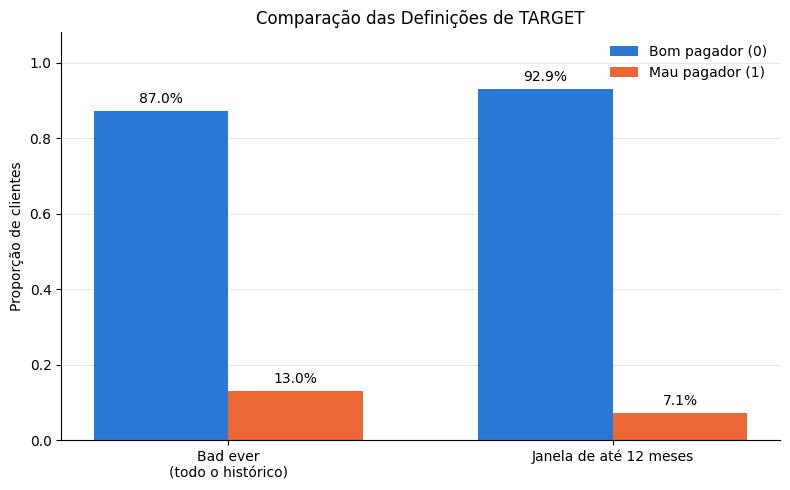

In [ ]:
# Cria o gráfico de comparação
fig, ax = plt.subplots(figsize=(8, 5))
nomes = ["Bad ever\n(todo o histórico)", "Janela de até 12 meses"]
bons = [(comparacao["TARGET_EVER"] == 0).mean(), (comparacao["TARGET_12M"] == 0).mean()]
maus = [(comparacao["TARGET_EVER"] == 1).mean(), (comparacao["TARGET_12M"] == 1).mean()]
x = np.arange(len(nomes)); largura = 0.35
barras_bons = ax.bar(x - largura / 2, bons, largura, label="Bom pagador (0)", color="#2a78d6")
barras_maus = ax.bar(x + largura / 2, maus, largura, label="Mau pagador (1)", color="#eb6834")
for barras in (barras_bons, barras_maus):
    for barra in barras:
        altura = barra.get_height()
        ax.annotate(f"{altura:.1%}", xy=(barra.get_x() + barra.get_width() / 2, altura), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom")
ax.set_xticks(x); ax.set_xticklabels(nomes); ax.set_ylabel("Proporção de clientes"); ax.set_ylim(0, 1.08)
ax.set_title("Comparação das Definições de TARGET"); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.yaxis.grid(True, alpha=0.3); ax.set_axisbelow(True); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretação do Gráfico Comparação as definições de TARGET(Todo o histórico x janela de 12 meses):**
>O gráfico compara a proporção de bons e maus pagadores segundo duas definições de TARGET. No TARGET_EVER, o cliente é classificado como mau pagador caso tenha apresentado atraso igual ou superior a 30 dias em qualquer momento do histórico. Já o TARGET de até 12 meses considera apenas os registros mais recentes disponíveis e exclui os clientes cuja janela contém exclusivamente STATUS = "X".

>A maior proporção esperada de maus pagadores no TARGET_EVER ocorre porque clientes com históricos mais longos tiveram mais oportunidades de apresentar algum atraso, inclusive isolado e antigo. A janela de até 12 meses reduz essa influência e prioriza o comportamento recente, tornando a classificação mais alinhada à avaliação atual do risco de crédito.

>Além da limitação temporal, a distribuição do TARGET de até 12 meses é influenciada pela exclusão dos clientes com somente STATUS = "X". Antes da exclusão, esses clientes recebiam inicialmente TARGET = 0, pois não apresentavam nenhum dos códigos de 1 a 5 considerados como atraso igual ou superior a 30 dias. Entretanto, o código X representa ausência de crédito ativo e não fornece evidência suficiente de bom comportamento de pagamento.

>A exclusão desses clientes reduz a quantidade de observações anteriormente incluídas na classe 0, sem criar novos casos de inadimplência. Consequentemente, os maus pagadores passam a representar uma parcela proporcionalmente maior da base válida. Essa alteração não significa que novos clientes foram classificados como maus pagadores, mas apenas que a população utilizada no cálculo foi modificada.

>A diferença entre as distribuições decorre, portanto, de dois tratamentos. A limitação da janela reduz a influência de atrasos antigos, enquanto a exclusão dos clientes somente com STATUS = "X" evita que a ausência de crédito ativo seja interpretada como evidência de bom comportamento de pagamento. Clientes com X em apenas parte da janela permanecem na base e são classificados de acordo com os demais registros disponíveis.

>Entretanto, o resultado deve ser interpretado com cautela, pois clientes com menos de 12 meses de histórico possuem menor tempo de exposição e menos oportunidades de apresentar inadimplência. Essa diferença de exposição deve ser considerada nas etapas posteriores de treinamento, avaliação e interpretação dos modelos.

### f) Conclusão


>A definição do TARGET considera como mau pagador o cliente que apresentou pelo menos um atraso igual ou superior a 30 dias nos 12 meses mais recentes disponíveis. Esse critério representa um evento relevante para a análise de risco de crédito, pois atrasos inferiores a 30 dias podem decorrer de situações pontuais, como esquecimento, diferença entre as datas de vencimento e de recebimento da renda ou pequenos problemas operacionais. Por essa razão, o código STATUS = 0, correspondente a atraso entre 1 e 29 dias, não foi utilizado para classificar o cliente como mau pagador.

>O TARGET identifica o cliente a partir do primeiro sinal relevante de inadimplência definido pelo negócio, correspondente a um atraso igual ou superior a 30 dias. Dessa forma, a regra possui caráter preventivo e relativamente rigoroso, pois não exige a repetição dos atrasos ou o agravamento da dívida para reconhecer o aumento do risco. Para o negócio, essa abordagem favorece a identificação antecipada de clientes potencialmente mais arriscados e pode apoiar ações como monitoramento, revisão de limites, adequação das condições de crédito e cobrança preventiva.

>A utilização de uma janela de até 12 meses prioriza o comportamento recente do cliente e reduz a influência de ocorrências antigas que podem não representar sua condição atual. A limitação temporal também torna os clientes mais comparáveis, pois aqueles acompanhados por períodos maiores possuem mais oportunidades de apresentar algum atraso. Os clientes com menos de 12 meses de histórico foram mantidos para preservar a quantidade e a representatividade das observações, embora possuam menor tempo de exposição e, consequentemente, menos oportunidades de apresentar inadimplência.

>O código STATUS = X representa ausência de crédito ativo no mês e, por isso, não foi considerado atraso igual ou superior a 30 dias. Entretanto, a ausência de atraso não significa necessariamente a existência de bom comportamento de pagamento. Quando toda a janela do cliente continha exclusivamente STATUS = X, não havia comportamento de crédito observável suficiente para classificá-lo adequadamente como bom ou mau pagador.

>Por essa razão, os clientes cuja janela de até 12 meses continha somente STATUS = X foram excluídos da base final. Antes da exclusão, esses clientes recebiam inicialmente TARGET = 0, pois o código X não integra a lista de status de mau pagador. A retirada desses casos evita que clientes sem evidência efetiva de pagamento sejam incluídos artificialmente na classe dos bons pagadores.

>Os clientes que apresentaram STATUS = X em apenas parte da janela foram mantidos quando também possuíam registros com C, 0 ou algum código de 1 a 5. Nesses casos, a classificação foi determinada com base no conjunto dos registros disponíveis. Assim, o cliente foi classificado como mau pagador quando apresentou pelo menos um status de 1 a 5 e como bom pagador quando possuía comportamento observável, mas não apresentou atraso igual ou superior a 30 dias.

>A exclusão dos clientes somente com STATUS = X também altera proporcionalmente a distribuição do TARGET. Como esses clientes estavam inicialmente incluídos na classe 0, a exclusão reduz a quantidade de observações classificadas como boas, sem criar novos casos de inadimplência. Consequentemente, os maus pagadores passam a representar uma parcela proporcionalmente maior da base válida, embora a quantidade desses clientes permaneça inalterada.

>Assim, a definição adotada estabelece um equilíbrio entre a identificação antecipada do risco, a atualidade das informações, a comparabilidade entre os clientes e a qualidade da variável-alvo. Entretanto, um único atraso de 30 dias pode decorrer de uma dificuldade pontual e não representar necessariamente um comportamento recorrente de inadimplência. Por isso, o TARGET deve ser utilizado como critério objetivo para o treinamento do modelo e como instrumento de apoio à decisão de crédito, não como justificativa isolada para a aprovação ou recusa de clientes.

## 1.3 Pre-Processamento e unificação da base

### a) Tratamento de IDs duplicados para manter uma linha cadastral por cliente.


In [ ]:
# Identifica IDs duplicados e mantém uma linha por cliente
ids_duplicados = application_df.loc[application_df.duplicated("ID", keep=False), "ID"]
print("Linhas no application_record:", len(application_df))
print("IDs únicos:", application_df["ID"].nunique())
print("IDs com mais de uma ocorrência:", ids_duplicados.nunique())
application_df = application_df.drop_duplicates(subset="ID", keep="first").copy()
assert application_df["ID"].is_unique

Linhas no application_record: 438557
IDs únicos: 438510
IDs com mais de uma ocorrência: 47


### b) Junção dos clientes válidos com os dados cadastrais para formar a base de modelagem.

In [ ]:
# Consolida os dados cadastrais com o TARGET
base_modelagem = application_df.merge(target_12m, on="ID", how="inner", validate="one_to_one")
assert not base_modelagem["ID"].isin(ids_excluidos_somente_x).any()
assert base_modelagem["MESES_COM_CREDITO"].gt(0).all()
print("Aplicantes únicos:", len(application_df))
print("Clientes válidos com TARGET:", len(target_12m))
print("Clientes na base final:", len(base_modelagem))
print("Clientes válidos sem cadastro:", len(target_12m) - len(base_modelagem))
print("Aplicantes sem TARGET válido:", len(application_df) - len(base_modelagem))

Aplicantes únicos: 438510
Clientes válidos com TARGET: 40752
Clientes na base final: 32617
Clientes válidos sem cadastro: 8135
Aplicantes sem TARGET válido: 405893


In [ ]:
# Calcula a distribuição final
distribuicao_final = base_modelagem["TARGET"].value_counts().sort_index().rename("quantidade").to_frame()
distribuicao_final["proporção"] = base_modelagem["TARGET"].value_counts(normalize=True).sort_index()
distribuicao_final = distribuicao_final.rename(index={0: "Bom pagador (0)", 1: "Mau pagador (1)"})
display(distribuicao_final)

,quantidade,proporção
TARGET,,
Bom pagador (0),30219,0.92648
Mau pagador (1),2398,0.07352


## 1.4 Análise das variáveis para construção do Pipeline de Modelagem


Objetivos:

    verificar a estrutura e a qualidade da base;
    examinar as principais variáveis categóricas e numéricas;
    avaliar associações descritivas com a inadimplência;
    identificar valores atípicos, outliers e riscos de vazamento;

### a) Funções para padronizar os gráficos

As funções reduzem repetições e mantêm a mesma diagramação em todo o notebook.

In [ ]:
# Função para frequência de variável categórica
def plot_frequencia(data, coluna, titulo, horizontal=False):
    ordem = data[coluna].value_counts(dropna=False).index
    plt.figure(figsize=(10, 5))
    if horizontal:
        sns.countplot(data=data, y=coluna, order=ordem, hue=coluna, palette="viridis", legend=False)
        plt.xlabel("Frequência")
        plt.ylabel("")
    else:
        sns.countplot(data=data, x=coluna, order=ordem, hue=coluna, palette="viridis", legend=False)
        plt.xlabel("")
        plt.ylabel("Frequência")
        plt.xticks(rotation=40, ha="right")
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

# Função para relação entre variável categórica e TARGET
def plot_target_categoria(data, coluna, titulo):
    tabela = pd.crosstab(data[coluna].fillna("Não informado"), data["TARGET"], normalize="index").mul(100)
    tabela = tabela.reindex(columns=[0, 1], fill_value=0).sort_values(by=1)
    ax = tabela.plot(kind="barh", stacked=True, figsize=(10, max(5, len(tabela) * 0.42)), color=["#4C956C", "#D1495B"])
    plt.title(titulo)
    plt.xlabel("Percentual (%)")
    plt.ylabel("")
    plt.xlim(0, 100)
    plt.legend(["Bom pagador", "Mau pagador"], title="TARGET", loc="upper left", bbox_to_anchor=(1.02, 1))
    for container in ax.containers:
        labels = [f"{v:.1f}%" if v >= 3 else "" for v in container.datavalues]
        ax.bar_label(container, labels=labels, label_type="center", color="white", fontsize=8)
    plt.tight_layout()
    plt.show()

# Função para histograma e boxplot
def plot_numerica(data, coluna, titulo, xlabel):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    sns.histplot(data=data, x=coluna, bins=40, kde=True, ax=axes[0], color="#6C5CE7")
    axes[0].set_title(f"Distribuição de {titulo}")
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel("Frequência")
    sns.boxplot(data=data, x=coluna, ax=axes[1], color="#A29BFE")
    axes[1].set_title(f"Boxplot de {titulo}")
    axes[1].set_xlabel(xlabel)
    plt.tight_layout()
    plt.show()

# Função para taxa de inadimplência por faixa
def plot_target_faixa(data, coluna, titulo):
    resumo = data.groupby(coluna, observed=True)["TARGET"].agg(Quantidade="size", Taxa="mean").reset_index()
    resumo["Taxa de inadimplência (%)"] = resumo["Taxa"].mul(100)
    plt.figure(figsize=(10, 5))
    ax = sns.barplot(data=resumo, x=coluna, y="Taxa de inadimplência (%)", color="#D1495B")
    plt.title(titulo)
    plt.xlabel("")
    plt.ylabel("Maus pagadores (%)")
    plt.xticks(rotation=40, ha="right")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8)
    plt.tight_layout()
    plt.show()
    display(resumo[[coluna, "Quantidade", "Taxa de inadimplência (%)"]])

### b) Estatísticas descritivas

In [ ]:
# Carrega a base integrada com o TARGET já construído

print("Dimensão da base:", base_modelagem.shape)
print("Quantidade de linhas:", base_modelagem.shape[0])
print("Quantidade de colunas:", base_modelagem.shape[1])
display(base_modelagem.head())

Dimensão da base: (32617, 23)
Quantidade de linhas: 32617
Quantidade de colunas: 23


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,...,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET,MESES_OBSERVADOS,MESES_COM_CREDITO,MES_MAIS_ANTIGO_JANELA,MES_MAIS_RECENTE_JANELA
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,...,1,0,0,NaN,2.0,0,12,12,-11,0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,...,1,0,0,NaN,2.0,0,12,12,-11,0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,...,0,0,0,Security staff,2.0,0,12,10,-11,0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,...,0,1,1,Sales staff,1.0,0,5,2,-4,0
4,5008810,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,...,0,1,1,Sales staff,1.0,0,12,12,-11,0


In [ ]:
# Verifica tipos, IDs, duplicidades, valores ausentes e TARGET
from IPython.display import display, Markdown
base_modelagem.info()

print("\nTotal de linhas:", base_modelagem.shape[0])
print("IDs únicos:", base_modelagem["ID"].nunique())
print("IDs duplicados:", base_modelagem["ID"].duplicated().sum())

resumo_nulos = pd.DataFrame({
    "Quantidade de nulos": base_modelagem.isna().sum(),
    "Percentual de nulos (%)": base_modelagem.isna().mean().mul(100).round(2)
})
resumo_nulos = resumo_nulos[resumo_nulos["Quantidade de nulos"] > 0]
display(resumo_nulos.sort_values("Percentual de nulos (%)", ascending=False))

print("Valores do TARGET:")
print(base_modelagem["TARGET"].value_counts(dropna=False).sort_index())
# Produz interpretação com os resultados encontrados

ids_unicos = int(base_modelagem["ID"].nunique())
ids_duplicados = int(base_modelagem["ID"].duplicated().sum())
nulos_total = int(base_modelagem.isna().sum().sum())

classes_target = set(base_modelagem["TARGET"].dropna().unique())

target_valido = (base_modelagem["TARGET"].notna().all()and classes_target == {0, 1})

texto_qualidade = f"A base possui {base_modelagem.shape[0]:,} registros e {ids_unicos:,} IDs únicos. Foram identificados {ids_duplicados} IDs duplicados e {nulos_total:,} valores ausentes no conjunto de dados. " + ("O TARGET contém somente as classes 0 e 1." if target_valido else "O TARGET contém valores diferentes de 0 e 1 e precisa ser revisado.")

display(Markdown("### Interpretação da qualidade da base\n\n" + texto_qualidade))



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32617 entries, 0 to 32616
Data columns (total 23 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       32617 non-null  int64  
 1   CODE_GENDER              32617 non-null  object 
 2   FLAG_OWN_CAR             32617 non-null  object 
 3   FLAG_OWN_REALTY          32617 non-null  object 
 4   CNT_CHILDREN             32617 non-null  int64  
 5   AMT_INCOME_TOTAL         32617 non-null  float64
 6   NAME_INCOME_TYPE         32617 non-null  object 
 7   NAME_EDUCATION_TYPE      32617 non-null  object 
 8   NAME_FAMILY_STATUS       32617 non-null  object 
 9   NAME_HOUSING_TYPE        32617 non-null  object 
 10  DAYS_BIRTH               32617 non-null  int64  
 11  DAYS_EMPLOYED            32617 non-null  int64  
 12  FLAG_MOBIL               32617 non-null  int64  
 13  FLAG_WORK_PHONE          32617 non-null  int64  
 14  FLAG_PHONE            

,Quantidade de nulos,Percentual de nulos (%)
OCCUPATION_TYPE,10226,31.35


Valores do TARGET:
TARGET
0    30219
1     2398
Name: count, dtype: int64


### Interpretação da qualidade da base

A base possui 32,617 registros e 32,617 IDs únicos. Foram identificados 0 IDs duplicados e 10,226 valores ausentes no conjunto de dados. O TARGET contém somente as classes 0 e 1.

,Frequência,Percentual (%)
Bom pagador,30219,92.65
Mau pagador,2398,7.35


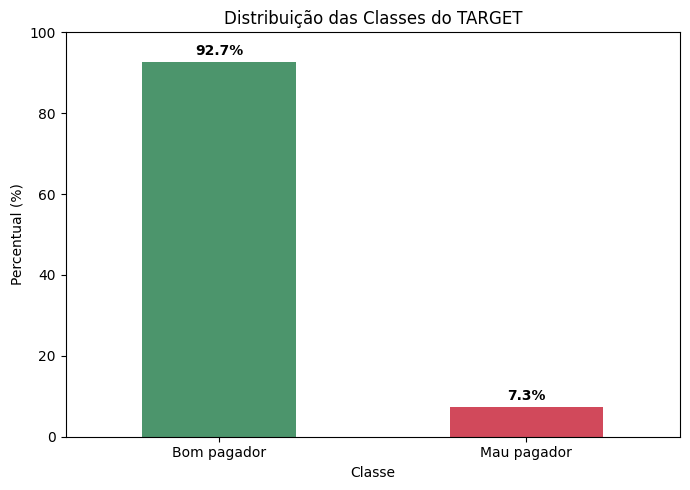

In [ ]:
# Calcula e apresenta a distribuição do TARGET
distribuicao_target = pd.DataFrame({
    "Frequência": base_modelagem["TARGET"].value_counts().sort_index(),
    "Percentual (%)": base_modelagem["TARGET"].value_counts(normalize=True).sort_index().mul(100).round(2)
})
distribuicao_target = distribuicao_target.reindex([0, 1], fill_value=0)
distribuicao_target.index = ["Bom pagador", "Mau pagador"]
display(distribuicao_target)

ax = distribuicao_target["Percentual (%)"].plot(
    kind="bar", figsize=(7, 5), color=["#4C956C", "#D1495B"]
)
plt.title("Distribuição das Classes do TARGET")
plt.xlabel("Classe")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold")
plt.tight_layout()
plt.show()

Maior parte dos clientes é bom pagador. Enquanto apenas 7,3% são maus pagadores.

### c) Feature Engineering

Não esquecer de: Calcular a taxa de inadimplência (média de TARGET_RISK) por variáveis numericas siginificativas

In [ ]:
# Valida se a base contém somente TARGET válido
print("Registros com TARGET ausente:", int(base_modelagem["TARGET"].isna().sum()))
print("Registros com TARGET diferente de 0 e 1:", int((~base_modelagem["TARGET"].dropna().isin([0,1])).sum()))

Registros com TARGET ausente: 0
Registros com TARGET diferente de 0 e 1: 0


In [ ]:
# Cria variáveis auxiliares para a análise exploratória
base_modelagem["GENDER_NOR"] = base_modelagem["CODE_GENDER"].map({"M": 0, "F": 1})
base_modelagem["OWN_CAR_NOR"] = base_modelagem["FLAG_OWN_CAR"].map({"N": 0, "Y": 1})
base_modelagem["OWN_REALTY_NOR"] = base_modelagem["FLAG_OWN_REALTY"].map({"N": 0, "Y": 1})
base_modelagem["YEARS_BIRTH"] = -base_modelagem["DAYS_BIRTH"] / 365.25
base_modelagem["OCCUPATION_TYPE_NEW"] = base_modelagem["OCCUPATION_TYPE"].fillna("Não informado")
base_modelagem["INCOME_PER_CAPITA"] = np.where(
    base_modelagem["CNT_FAM_MEMBERS"] > 0,
    base_modelagem["AMT_INCOME_TOTAL"] / base_modelagem["CNT_FAM_MEMBERS"],
    np.nan
)

In [ ]:
# Define o código especial da variável DAYS_EMPLOYED

VALOR_ESPECIAL_EMPLOYED = 365243

# Identifica os registros com o código especial

mascara_especial = (base_modelagem["DAYS_EMPLOYED"].eq(VALOR_ESPECIAL_EMPLOYED))

# Identifica os clientes classificados como pensionistas

base_modelagem["IS_RETIRED"] = (base_modelagem["NAME_INCOME_TYPE"].eq("Pensioner").astype(int))

# Sinaliza os registros que possuíam o código especial 365243

base_modelagem["EMPLOYMENT_SPECIAL_VALUE"] = (mascara_especial.astype(int))

# Sinaliza tempo de emprego não informado entre não pensionistas

base_modelagem["EMPLOYMENT_NOT_INFORMED"] = (mascara_especial & base_modelagem["IS_RETIRED"].eq(0)).astype(int)


# Converte os dias válidos para anos
# O código especial recebe zero

base_modelagem["YEARS_EMPLOYED"] = np.where(mascara_especial, 0,
    -base_modelagem["DAYS_EMPLOYED"] / 365.25)

# Valida o tratamento

print("Registros com código especial:",base_modelagem["EMPLOYMENT_SPECIAL_VALUE"].sum())

print("Quantidade de pensionistas:", base_modelagem["IS_RETIRED"].sum())

print("Tempo não informado entre não pensionistas:",base_modelagem["EMPLOYMENT_NOT_INFORMED"].sum())

print("Anos negativos após o tratamento:",(base_modelagem["YEARS_EMPLOYED"] < 0).sum())

display(base_modelagem[["DAYS_EMPLOYED","YEARS_EMPLOYED","IS_RETIRED","EMPLOYMENT_SPECIAL_VALUE","EMPLOYMENT_NOT_INFORMED"]].head(10))

Registros com código especial: 5571
Quantidade de pensionistas: 5588
Tempo não informado entre não pensionistas: 0
Anos negativos após o tratamento: 0


,DAYS_EMPLOYED,YEARS_EMPLOYED,IS_RETIRED,EMPLOYMENT_SPECIAL_VALUE,EMPLOYMENT_NOT_INFORMED
0,-4542,12.435318,0,0,0
1,-4542,12.435318,0,0,0
2,-1134,3.104723,0,0,0
3,-3051,8.353183,0,0,0
4,-3051,8.353183,0,0,0
5,-3051,8.353183,0,0,0
6,365243,0.000000,1,1,0
7,365243,0.000000,1,1,0
8,365243,0.000000,1,1,0
9,-769,2.105407,0,0,0


In [ ]:
# Define a ordem dos níveis de escolaridade
ordem_escolaridade = {
    "Lower secondary": 1,
    "Secondary / secondary special": 2,
    "Incomplete higher": 3,
    "Higher education": 4,
    "Academic degree": 5
}

base_modelagem["EDUCATION_ORD"] = base_modelagem["NAME_EDUCATION_TYPE"].map(ordem_escolaridade)
display(base_modelagem[["NAME_EDUCATION_TYPE", "EDUCATION_ORD"]].drop_duplicates().sort_values("EDUCATION_ORD"))
print("Valores sem código ordinal:", int(base_modelagem["EDUCATION_ORD"].isna().sum()))

,NAME_EDUCATION_TYPE,EDUCATION_ORD
408,Lower secondary,1
2,Secondary / secondary special,2
16,Incomplete higher,3
0,Higher education,4
1617,Academic degree,5


Valores sem código ordinal: 0


### d) Variáveis categóricas

#### 1 - Gênero

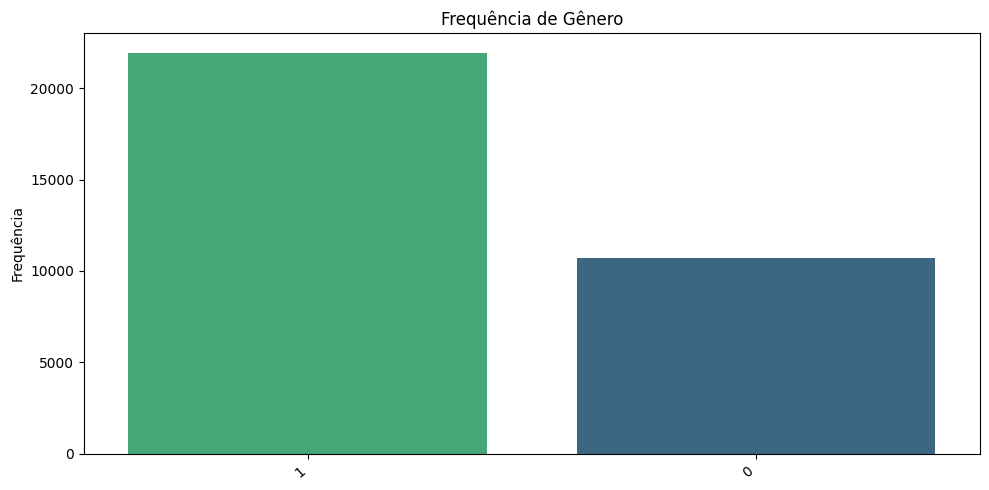

#### Interpretação da distribuição

A distribuição indica predominância de 1 na amostra, com 67.2% dos registros. Essa diferença descreve a composição da base, mas não demonstra, isoladamente, relação com o risco de inadimplência.

In [ ]:
# Apresenta a frequência de gênero
plot_frequencia(base_modelagem, "GENDER_NOR", "Frequência de Gênero", horizontal=False)

frequencia = base_modelagem["GENDER_NOR"].fillna("Não informado").value_counts(normalize=True)
categoria_principal = frequencia.index[0]
percentual_principal = frequencia.iloc[0] * 100

interpretacao = "A distribuição indica predominância de {topo} na amostra, com {pct:.1f}% dos registros. Essa diferença descreve a composição da base, mas não demonstra, isoladamente, relação com o risco de inadimplência.".format(
    topo=categoria_principal,
    pct=percentual_principal
)
display(Markdown("#### Interpretação da distribuição\n\n" + interpretacao))

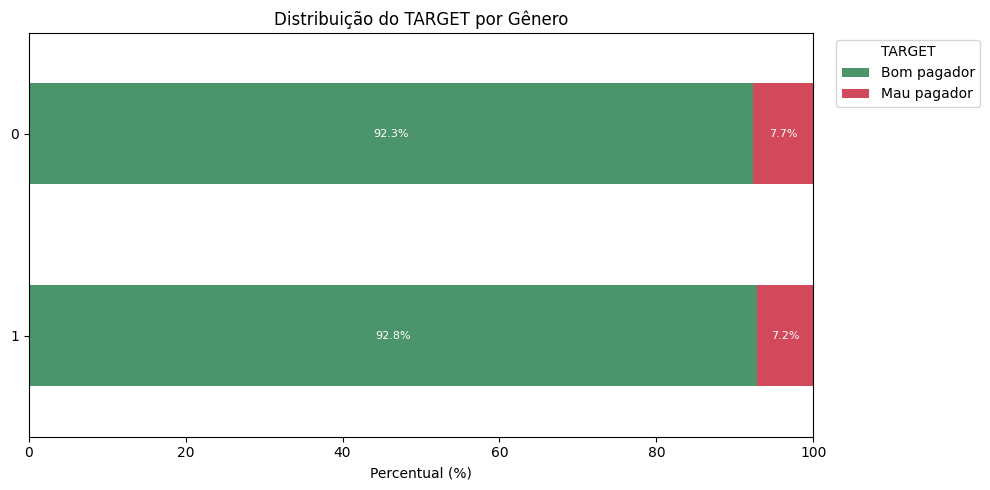

#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em 0 (7.7%), enquanto a menor aparece em 1 (7.2%). A diferença é de 0.6 pontos percentuais. O resultado é descritivo e deve ser interpretado juntamente com a quantidade de clientes de cada categoria, especialmente nos grupos menos frequentes.

In [ ]:
# Compara gênero com o TARGET
plot_target_categoria(base_modelagem, "GENDER_NOR", "Distribuição do TARGET por Gênero")

tabela_interpretacao = (
    base_modelagem.assign(CATEGORIA=base_modelagem["GENDER_NOR"].fillna("Não informado"))
    .groupby("CATEGORIA")["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .sort_values("Taxa", ascending=False)
)

maior_categoria = tabela_interpretacao.index[0]
menor_categoria = tabela_interpretacao.index[-1]
maior_taxa = tabela_interpretacao.iloc[0]["Taxa"] * 100
menor_taxa = tabela_interpretacao.iloc[-1]["Taxa"] * 100
diferenca = maior_taxa - menor_taxa

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_categoria} "
    f"({maior_taxa:.1f}%), enquanto a menor aparece em {menor_categoria} "
    f"({menor_taxa:.1f}%). A diferença é de {diferenca:.1f} pontos percentuais. "
    "O resultado é descritivo e deve ser interpretado juntamente com a quantidade "
    "de clientes de cada categoria, especialmente nos grupos menos frequentes."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 2 - Posse de imóvel

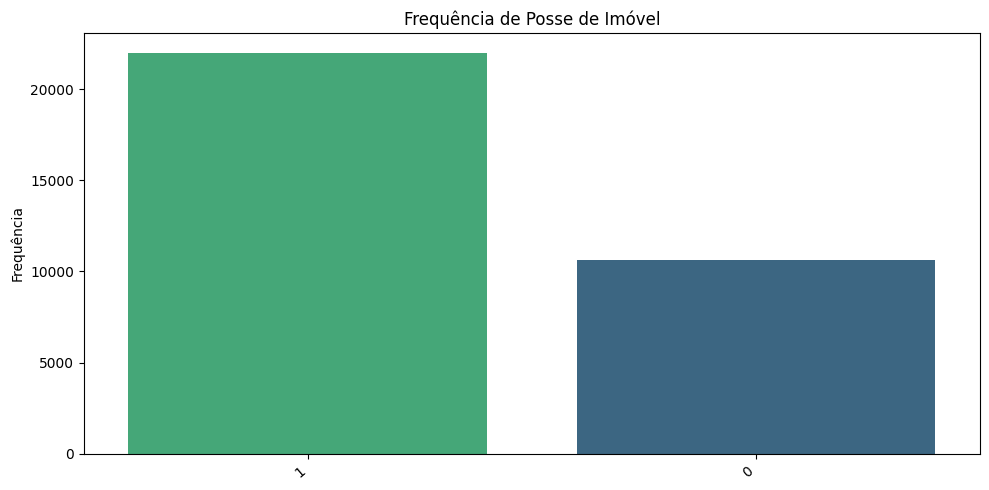

#### Interpretação da distribuição

A categoria mais frequente é 1, representando 67.4% dos clientes. A posse de imóvel é, portanto, uma característica comum na base, mas sua utilidade para o risco deve ser avaliada pela comparação com o TARGET.

In [ ]:
# Apresenta a frequência de posse de imóvel
plot_frequencia(base_modelagem, "OWN_REALTY_NOR", "Frequência de Posse de Imóvel", horizontal=False)

frequencia = base_modelagem["OWN_REALTY_NOR"].fillna("Não informado").value_counts(normalize=True)
categoria_principal = frequencia.index[0]
percentual_principal = frequencia.iloc[0] * 100

interpretacao = "A categoria mais frequente é {topo}, representando {pct:.1f}% dos clientes. A posse de imóvel é, portanto, uma característica comum na base, mas sua utilidade para o risco deve ser avaliada pela comparação com o TARGET.".format(
    topo=categoria_principal,
    pct=percentual_principal
)
display(Markdown("#### Interpretação da distribuição\n\n" + interpretacao))

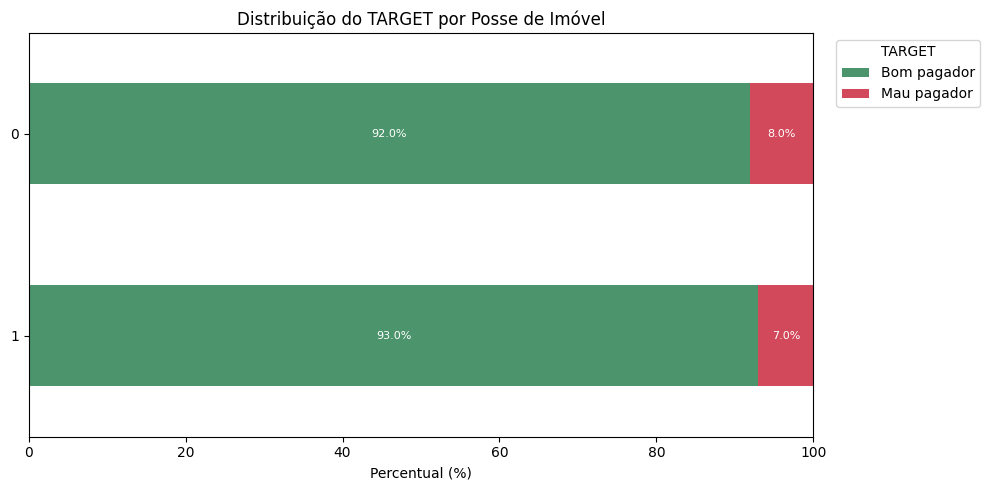

#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em 0 (8.0%), enquanto a menor aparece em 1 (7.0%). A diferença é de 1.0 pontos percentuais. O resultado é descritivo e deve ser interpretado juntamente com a quantidade de clientes de cada categoria, especialmente nos grupos menos frequentes.

In [ ]:
# Compara posse de imóvel com o TARGET
plot_target_categoria(base_modelagem, "OWN_REALTY_NOR", "Distribuição do TARGET por Posse de Imóvel")

tabela_interpretacao = (
    base_modelagem.assign(CATEGORIA=base_modelagem["OWN_REALTY_NOR"].fillna("Não informado"))
    .groupby("CATEGORIA")["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .sort_values("Taxa", ascending=False)
)

maior_categoria = tabela_interpretacao.index[0]
menor_categoria = tabela_interpretacao.index[-1]
maior_taxa = tabela_interpretacao.iloc[0]["Taxa"] * 100
menor_taxa = tabela_interpretacao.iloc[-1]["Taxa"] * 100
diferenca = maior_taxa - menor_taxa

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_categoria} "
    f"({maior_taxa:.1f}%), enquanto a menor aparece em {menor_categoria} "
    f"({menor_taxa:.1f}%). A diferença é de {diferenca:.1f} pontos percentuais. "
    "O resultado é descritivo e deve ser interpretado juntamente com a quantidade "
    "de clientes de cada categoria, especialmente nos grupos menos frequentes."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 3 - Posse de carro

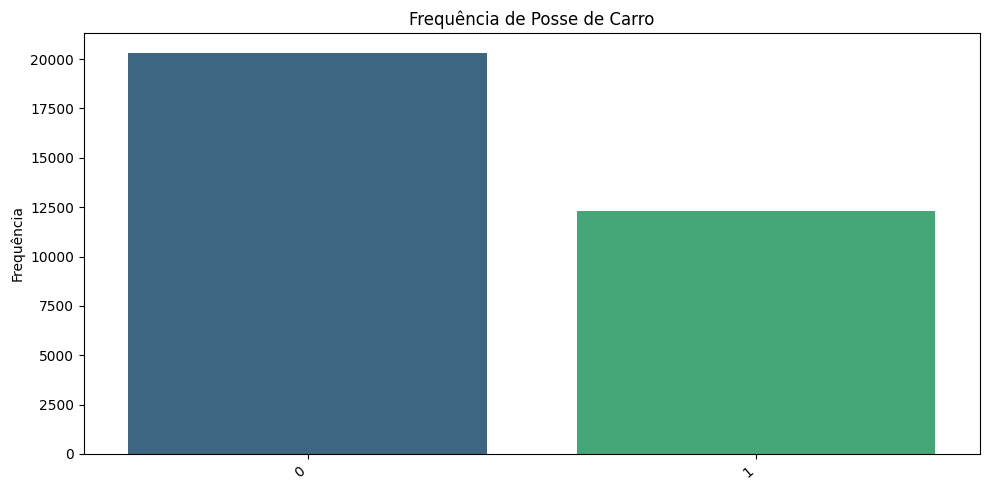

#### Interpretação da distribuição

A categoria mais frequente é 0, com 62.3% dos registros. As duas categorias devem ser comparadas com o TARGET para verificar se a posse de carro diferencia o comportamento de pagamento.

In [ ]:
# Apresenta a frequência de posse de carro
plot_frequencia(base_modelagem, "OWN_CAR_NOR", "Frequência de Posse de Carro", horizontal=False)

frequencia = base_modelagem["OWN_CAR_NOR"].fillna("Não informado").value_counts(normalize=True)
categoria_principal = frequencia.index[0]
percentual_principal = frequencia.iloc[0] * 100

interpretacao = "A categoria mais frequente é {topo}, com {pct:.1f}% dos registros. As duas categorias devem ser comparadas com o TARGET para verificar se a posse de carro diferencia o comportamento de pagamento.".format(
    topo=categoria_principal,
    pct=percentual_principal
)
display(Markdown("#### Interpretação da distribuição\n\n" + interpretacao))

In [ ]:
# Compara posse de carro com o TARGET
plot_target_categoria(base_modelagem, "OWN_CAR_NOR", "Distribuição do TARGET por Posse de Carro")

tabela_interpretacao = (
    base_modelagem.assign(CATEGORIA=base_modelagem["OWN_CAR_NOR"].fillna("Não informado"))
    .groupby("CATEGORIA")["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .sort_values("Taxa", ascending=False)
)

maior_categoria = tabela_interpretacao.index[0]
menor_categoria = tabela_interpretacao.index[-1]
maior_taxa = tabela_interpretacao.iloc[0]["Taxa"] * 100
menor_taxa = tabela_interpretacao.iloc[-1]["Taxa"] * 100
diferenca = maior_taxa - menor_taxa

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_categoria} "
    f"({maior_taxa:.1f}%), enquanto a menor aparece em {menor_categoria} "
    f"({menor_taxa:.1f}%). A diferença é de {diferenca:.1f} pontos percentuais. "
    "O resultado é descritivo e deve ser interpretado juntamente com a quantidade "
    "de clientes de cada categoria, especialmente nos grupos menos frequentes."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 4 - Escolaridade

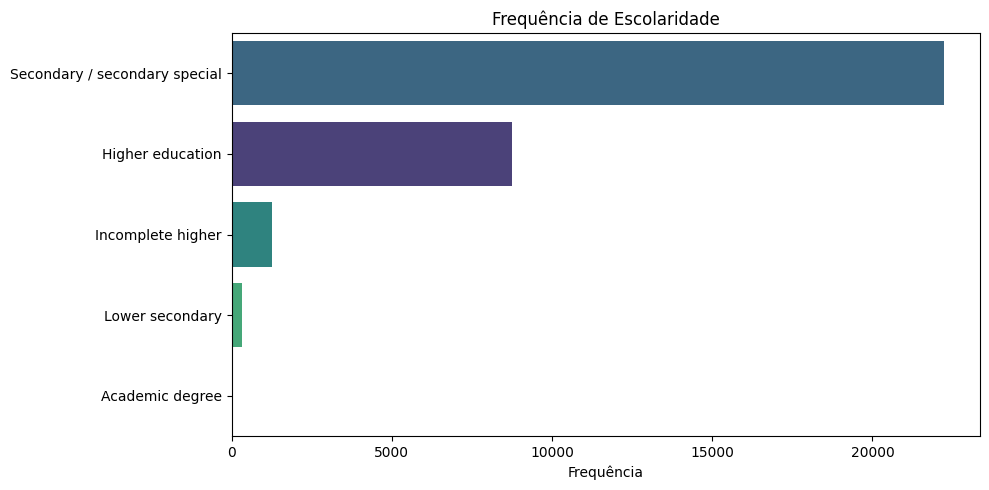

#### Interpretação da distribuição

A escolaridade concentra-se principalmente em Secondary / secondary special, categoria que representa 68.2% da base. Categorias educacionais raras devem ser interpretadas com cautela, pois podem apresentar taxas de inadimplência instáveis.

In [ ]:
# Apresenta a frequência de escolaridade
plot_frequencia(base_modelagem, "NAME_EDUCATION_TYPE", "Frequência de Escolaridade", horizontal=True)

frequencia = base_modelagem["NAME_EDUCATION_TYPE"].fillna("Não informado").value_counts(normalize=True)
categoria_principal = frequencia.index[0]
percentual_principal = frequencia.iloc[0] * 100

interpretacao = "A escolaridade concentra-se principalmente em {topo}, categoria que representa {pct:.1f}% da base. Categorias educacionais raras devem ser interpretadas com cautela, pois podem apresentar taxas de inadimplência instáveis.".format(
    topo=categoria_principal,
    pct=percentual_principal
)
display(Markdown("#### Interpretação da distribuição\n\n" + interpretacao))

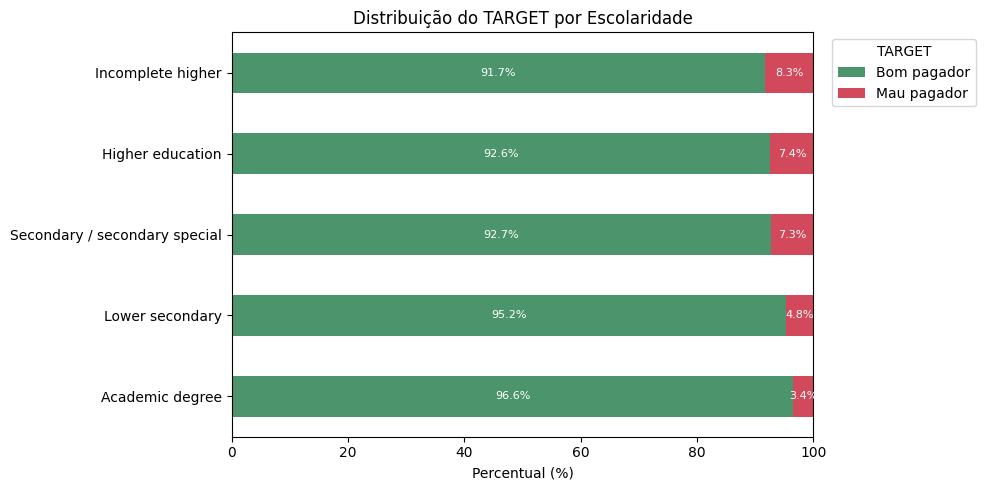

#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em Incomplete higher (8.3%), enquanto a menor aparece em Academic degree (3.4%). A diferença é de 4.8 pontos percentuais. O resultado é descritivo e deve ser interpretado juntamente com a quantidade de clientes de cada categoria, especialmente nos grupos menos frequentes.

In [ ]:
# Compara escolaridade com o TARGET
plot_target_categoria(base_modelagem, "NAME_EDUCATION_TYPE", "Distribuição do TARGET por Escolaridade")

tabela_interpretacao = (
    base_modelagem.assign(CATEGORIA=base_modelagem["NAME_EDUCATION_TYPE"].fillna("Não informado"))
    .groupby("CATEGORIA")["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .sort_values("Taxa", ascending=False)
)

maior_categoria = tabela_interpretacao.index[0]
menor_categoria = tabela_interpretacao.index[-1]
maior_taxa = tabela_interpretacao.iloc[0]["Taxa"] * 100
menor_taxa = tabela_interpretacao.iloc[-1]["Taxa"] * 100
diferenca = maior_taxa - menor_taxa

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_categoria} "
    f"({maior_taxa:.1f}%), enquanto a menor aparece em {menor_categoria} "
    f"({menor_taxa:.1f}%). A diferença é de {diferenca:.1f} pontos percentuais. "
    "O resultado é descritivo e deve ser interpretado juntamente com a quantidade "
    "de clientes de cada categoria, especialmente nos grupos menos frequentes."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 5 - Estado civil

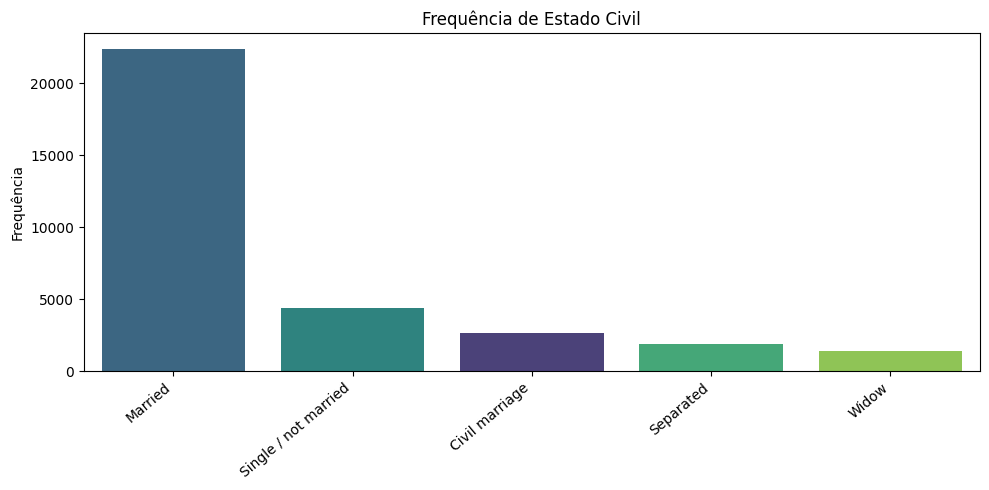

#### Interpretação da distribuição

O estado civil mais frequente é Married, com 68.6% dos clientes. A concentração nessa categoria deve ser considerada ao comparar as taxas de inadimplência entre os grupos.

In [ ]:
# Apresenta a frequência de estado civil
plot_frequencia(base_modelagem, "NAME_FAMILY_STATUS", "Frequência de Estado Civil", horizontal=False)

frequencia = base_modelagem["NAME_FAMILY_STATUS"].fillna("Não informado").value_counts(normalize=True)
categoria_principal = frequencia.index[0]
percentual_principal = frequencia.iloc[0] * 100

interpretacao = "O estado civil mais frequente é {topo}, com {pct:.1f}% dos clientes. A concentração nessa categoria deve ser considerada ao comparar as taxas de inadimplência entre os grupos.".format(
    topo=categoria_principal,
    pct=percentual_principal
)
display(Markdown("#### Interpretação da distribuição\n\n" + interpretacao))

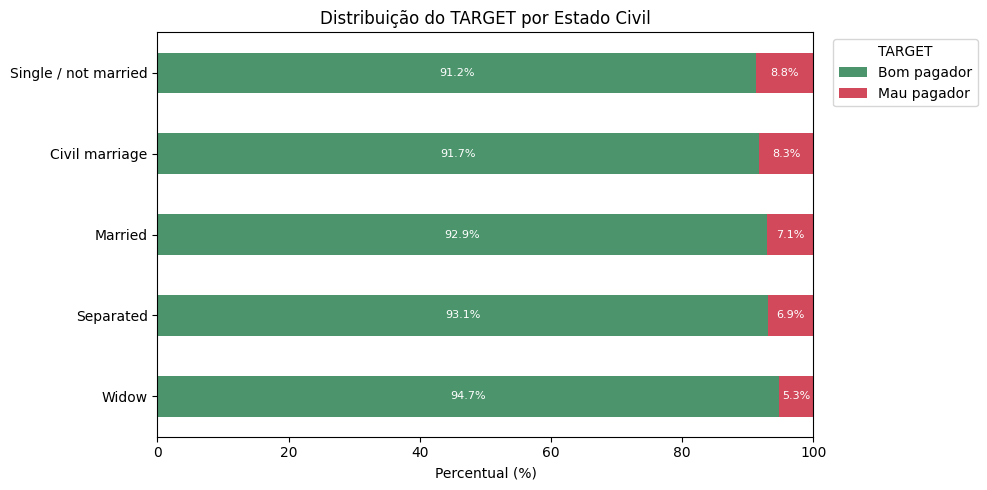

#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em Single / not married (8.8%), enquanto a menor aparece em Widow (5.3%). A diferença é de 3.5 pontos percentuais. O resultado é descritivo e deve ser interpretado juntamente com a quantidade de clientes de cada categoria, especialmente nos grupos menos frequentes.

In [ ]:
# Compara estado civil com o TARGET
plot_target_categoria(base_modelagem, "NAME_FAMILY_STATUS", "Distribuição do TARGET por Estado Civil")

tabela_interpretacao = (
    base_modelagem.assign(CATEGORIA=base_modelagem["NAME_FAMILY_STATUS"].fillna("Não informado"))
    .groupby("CATEGORIA")["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .sort_values("Taxa", ascending=False)
)

maior_categoria = tabela_interpretacao.index[0]
menor_categoria = tabela_interpretacao.index[-1]
maior_taxa = tabela_interpretacao.iloc[0]["Taxa"] * 100
menor_taxa = tabela_interpretacao.iloc[-1]["Taxa"] * 100
diferenca = maior_taxa - menor_taxa

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_categoria} "
    f"({maior_taxa:.1f}%), enquanto a menor aparece em {menor_categoria} "
    f"({menor_taxa:.1f}%). A diferença é de {diferenca:.1f} pontos percentuais. "
    "O resultado é descritivo e deve ser interpretado juntamente com a quantidade "
    "de clientes de cada categoria, especialmente nos grupos menos frequentes."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 6 - Tipo de renda

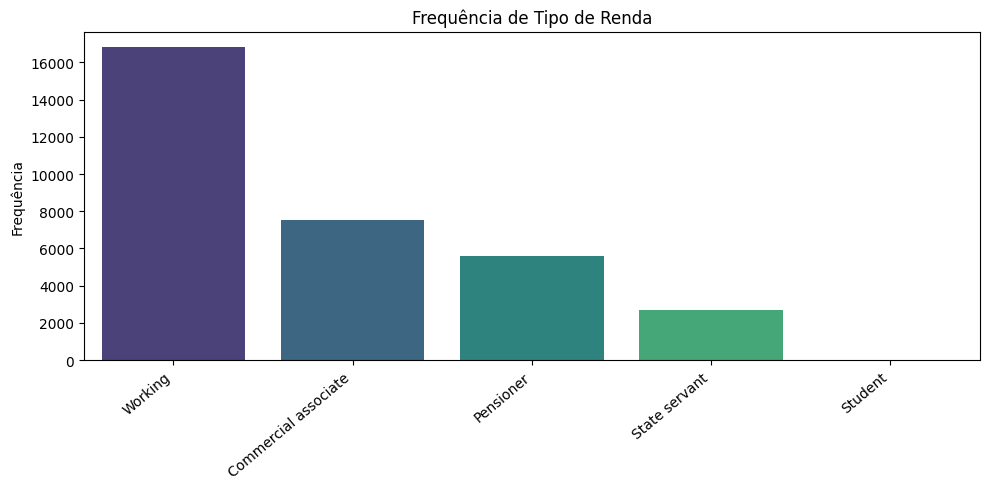

#### Interpretação da distribuição

O tipo de renda predominante é Working, representando 51.5% dos registros. Categorias com poucos clientes não devem fundamentar conclusões fortes, mesmo quando apresentam percentuais extremos.

In [ ]:
# Apresenta a frequência de tipo de renda
plot_frequencia(base_modelagem, "NAME_INCOME_TYPE", "Frequência de Tipo de Renda", horizontal=False)

frequencia = base_modelagem["NAME_INCOME_TYPE"].fillna("Não informado").value_counts(normalize=True)
categoria_principal = frequencia.index[0]
percentual_principal = frequencia.iloc[0] * 100

interpretacao = "O tipo de renda predominante é {topo}, representando {pct:.1f}% dos registros. Categorias com poucos clientes não devem fundamentar conclusões fortes, mesmo quando apresentam percentuais extremos.".format(
    topo=categoria_principal,
    pct=percentual_principal
)
display(Markdown("#### Interpretação da distribuição\n\n" + interpretacao))

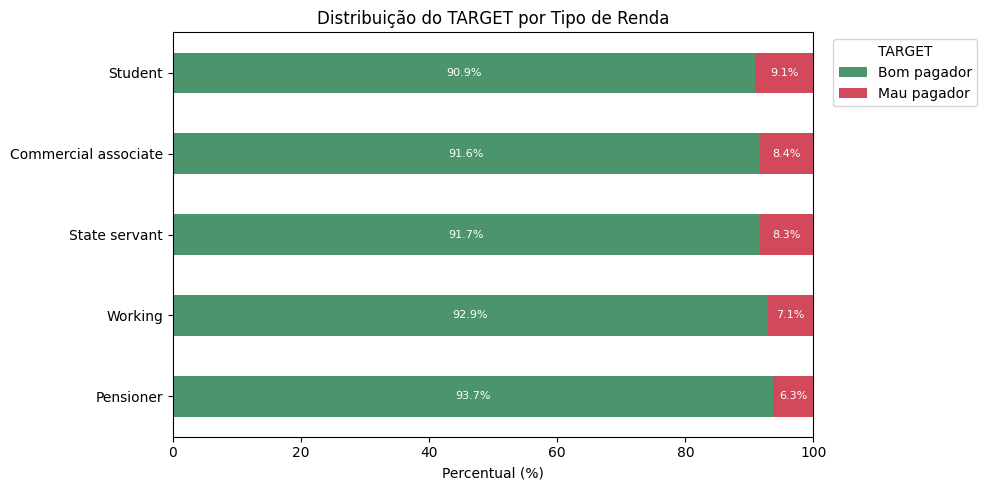

#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em Student (9.1%), enquanto a menor aparece em Pensioner (6.3%). A diferença é de 2.8 pontos percentuais. O resultado é descritivo e deve ser interpretado juntamente com a quantidade de clientes de cada categoria, especialmente nos grupos menos frequentes.

In [ ]:
# Compara tipo de renda com o TARGET
plot_target_categoria(base_modelagem, "NAME_INCOME_TYPE", "Distribuição do TARGET por Tipo de Renda")

tabela_interpretacao = (
    base_modelagem.assign(CATEGORIA=base_modelagem["NAME_INCOME_TYPE"].fillna("Não informado"))
    .groupby("CATEGORIA")["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .sort_values("Taxa", ascending=False)
)

maior_categoria = tabela_interpretacao.index[0]
menor_categoria = tabela_interpretacao.index[-1]
maior_taxa = tabela_interpretacao.iloc[0]["Taxa"] * 100
menor_taxa = tabela_interpretacao.iloc[-1]["Taxa"] * 100
diferenca = maior_taxa - menor_taxa

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_categoria} "
    f"({maior_taxa:.1f}%), enquanto a menor aparece em {menor_categoria} "
    f"({menor_taxa:.1f}%). A diferença é de {diferenca:.1f} pontos percentuais. "
    "O resultado é descritivo e deve ser interpretado juntamente com a quantidade "
    "de clientes de cada categoria, especialmente nos grupos menos frequentes."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 7 - Tipo de moradia

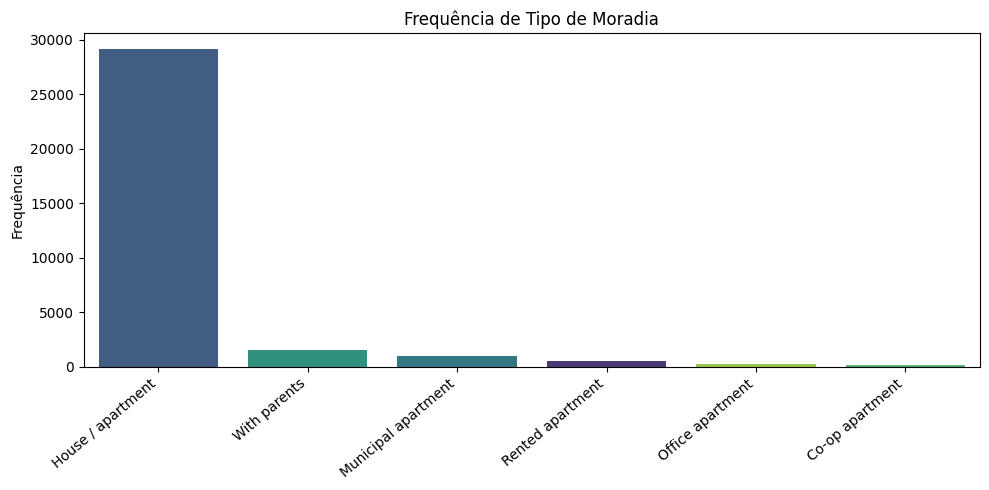

#### Interpretação da distribuição

O tipo de moradia mais frequente é House / apartment, com 89.4% da amostra. A baixa frequência de algumas categorias exige cautela na comparação das taxas de inadimplência.

In [ ]:
# Apresenta a frequência de tipo de moradia
plot_frequencia(base_modelagem, "NAME_HOUSING_TYPE", "Frequência de Tipo de Moradia", horizontal=False)

frequencia = base_modelagem["NAME_HOUSING_TYPE"].fillna("Não informado").value_counts(normalize=True)
categoria_principal = frequencia.index[0]
percentual_principal = frequencia.iloc[0] * 100

interpretacao = "O tipo de moradia mais frequente é {topo}, com {pct:.1f}% da amostra. A baixa frequência de algumas categorias exige cautela na comparação das taxas de inadimplência.".format(
    topo=categoria_principal,
    pct=percentual_principal
)
display(Markdown("#### Interpretação da distribuição\n\n" + interpretacao))

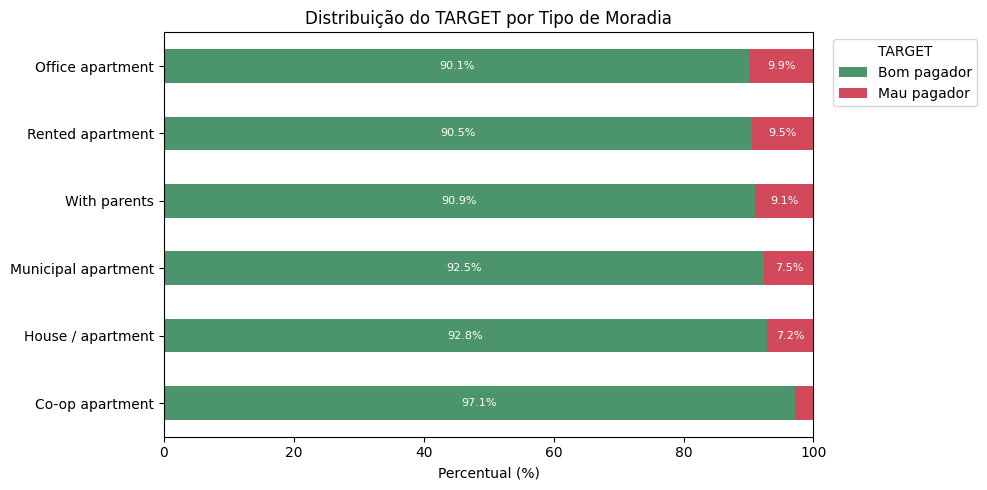

#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em Office apartment (9.9%), enquanto a menor aparece em Co-op apartment (2.9%). A diferença é de 7.0 pontos percentuais. O resultado é descritivo e deve ser interpretado juntamente com a quantidade de clientes de cada categoria, especialmente nos grupos menos frequentes.

In [ ]:
# Compara tipo de moradia com o TARGET
plot_target_categoria(base_modelagem, "NAME_HOUSING_TYPE", "Distribuição do TARGET por Tipo de Moradia")

tabela_interpretacao = (
    base_modelagem.assign(CATEGORIA=base_modelagem["NAME_HOUSING_TYPE"].fillna("Não informado"))
    .groupby("CATEGORIA")["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .sort_values("Taxa", ascending=False)
)

maior_categoria = tabela_interpretacao.index[0]
menor_categoria = tabela_interpretacao.index[-1]
maior_taxa = tabela_interpretacao.iloc[0]["Taxa"] * 100
menor_taxa = tabela_interpretacao.iloc[-1]["Taxa"] * 100
diferenca = maior_taxa - menor_taxa

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_categoria} "
    f"({maior_taxa:.1f}%), enquanto a menor aparece em {menor_categoria} "
    f"({menor_taxa:.1f}%). A diferença é de {diferenca:.1f} pontos percentuais. "
    "O resultado é descritivo e deve ser interpretado juntamente com a quantidade "
    "de clientes de cada categoria, especialmente nos grupos menos frequentes."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 8 - Tipo de Ocupação

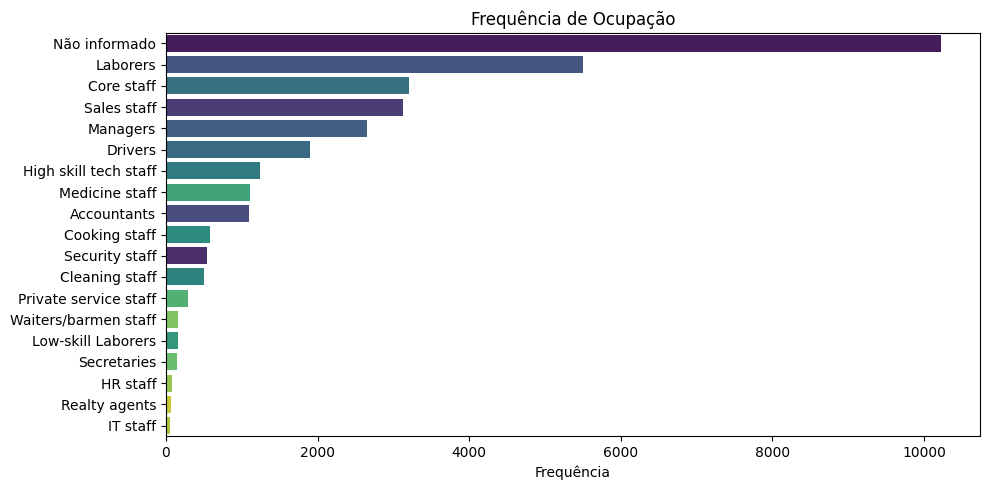

#### Interpretação da distribuição

A categoria mais frequente é Não informado, representando 31.4% dos registros. A presença expressiva de Não informado evidencia ausência relevante de informação ocupacional e deverá ser tratada no pré-processamento.

In [ ]:
# Apresenta a frequência de ocupação
plot_frequencia(base_modelagem, "OCCUPATION_TYPE_NEW", "Frequência de Ocupação", horizontal=True)

frequencia = base_modelagem["OCCUPATION_TYPE_NEW"].fillna("Não informado").value_counts(normalize=True)
categoria_principal = frequencia.index[0]
percentual_principal = frequencia.iloc[0] * 100

interpretacao = "A categoria mais frequente é {topo}, representando {pct:.1f}% dos registros. A presença expressiva de Não informado evidencia ausência relevante de informação ocupacional e deverá ser tratada no pré-processamento.".format(
    topo=categoria_principal,
    pct=percentual_principal
)
display(Markdown("#### Interpretação da distribuição\n\n" + interpretacao))

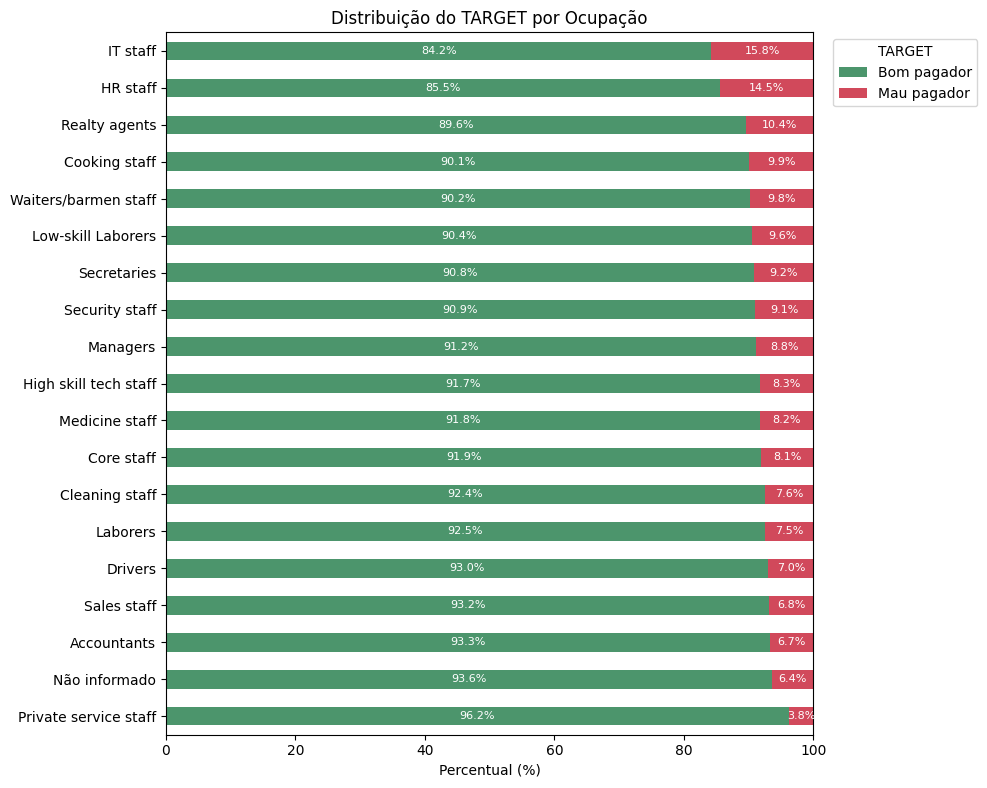

#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em IT staff (15.8%), enquanto a menor aparece em Private service staff (3.8%). A diferença é de 12.0 pontos percentuais. O resultado é descritivo e deve ser interpretado juntamente com a quantidade de clientes de cada categoria, especialmente nos grupos menos frequentes.

In [ ]:
# Compara ocupação com o TARGET
plot_target_categoria(base_modelagem, "OCCUPATION_TYPE_NEW", "Distribuição do TARGET por Ocupação")

tabela_interpretacao = (
    base_modelagem.assign(CATEGORIA=base_modelagem["OCCUPATION_TYPE_NEW"].fillna("Não informado"))
    .groupby("CATEGORIA")["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .sort_values("Taxa", ascending=False)
)

maior_categoria = tabela_interpretacao.index[0]
menor_categoria = tabela_interpretacao.index[-1]
maior_taxa = tabela_interpretacao.iloc[0]["Taxa"] * 100
menor_taxa = tabela_interpretacao.iloc[-1]["Taxa"] * 100
diferenca = maior_taxa - menor_taxa

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_categoria} "
    f"({maior_taxa:.1f}%), enquanto a menor aparece em {menor_categoria} "
    f"({menor_taxa:.1f}%). A diferença é de {diferenca:.1f} pontos percentuais. "
    "O resultado é descritivo e deve ser interpretado juntamente com a quantidade "
    "de clientes de cada categoria, especialmente nos grupos menos frequentes."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 9 - Telefone móvel (celular)

In [ ]:
# Verifica a variabilidade de FLAG_MOBIL
frequencia_mobil = base_modelagem["FLAG_MOBIL"].value_counts(dropna=False)
display(frequencia_mobil.to_frame("Quantidade"))

if base_modelagem["FLAG_MOBIL"].nunique(dropna=False) <= 1:
    texto = "FLAG_MOBIL apresenta apenas uma categoria e, por isso, não possui capacidade para diferenciar os clientes. A variável deverá ser considerada para exclusão no Notebook 03."
else:
    dominante = base_modelagem["FLAG_MOBIL"].value_counts(normalize=True, dropna=False).iloc[0] * 100
    texto = f"FLAG_MOBIL apresenta baixa variabilidade, com {dominante:.1f}% dos registros na categoria dominante. Sua contribuição preditiva tende a ser limitada."

display(Markdown("### Interpretação de FLAG_MOBIL\n\n" + texto))

,Quantidade
FLAG_MOBIL,
1,32617


### Interpretação de FLAG_MOBIL

FLAG_MOBIL apresenta apenas uma categoria e, por isso, não possui capacidade para diferenciar os clientes. A variável deverá ser considerada para exclusão no Notebook 03.

#### 10 - Telefone de trabalho

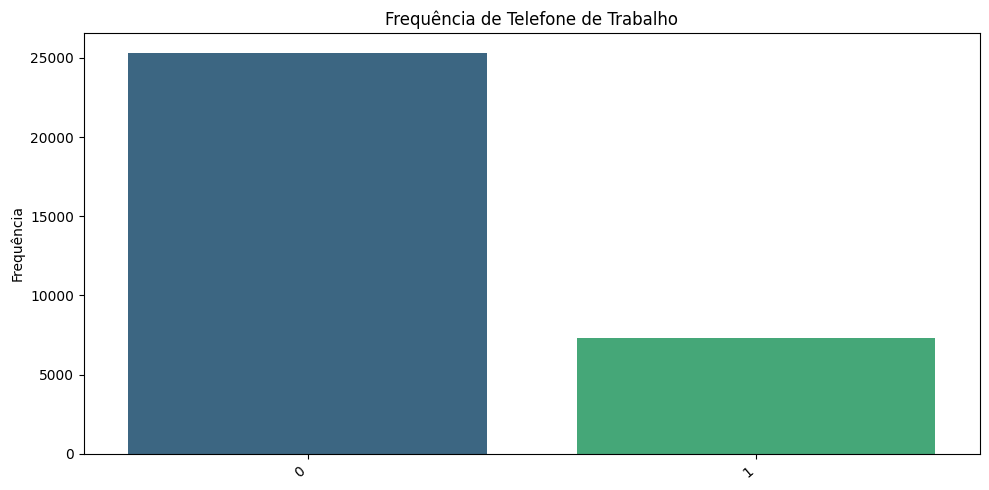

#### Interpretação da distribuição

A categoria 0 concentra 77.6% dos registros de telefone de trabalho, evidenciando a composição dessa informação cadastral na base.

In [ ]:
# Apresenta frequência e relação de telefone de trabalho com o TARGET
plot_frequencia(base_modelagem, "FLAG_WORK_PHONE", "Frequência de Telefone de Trabalho")

freq = base_modelagem["FLAG_WORK_PHONE"].value_counts(normalize=True, dropna=False)
principal = freq.index[0]
pct = freq.iloc[0] * 100
display(Markdown(
    "#### Interpretação da distribuição\n\n"
    f"A categoria {principal} concentra {pct:.1f}% dos registros de telefone de trabalho, "
    "evidenciando a composição dessa informação cadastral na base."
))



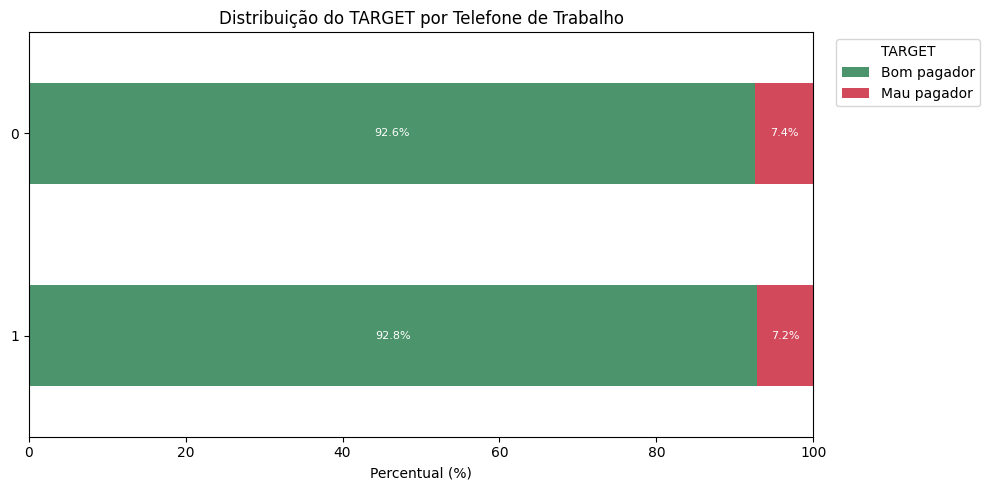

#### Interpretação da relação com o TARGET

As taxas de inadimplência variam de 7.2% a 7.4%, diferença de 0.1 pontos percentuais. Diferenças pequenas indicam que a variável apresenta baixa capacidade isolada de distinguir bons e maus pagadores.

In [ ]:
# Compara tipo de moradia com o TARGET
plot_target_categoria(base_modelagem, "FLAG_WORK_PHONE", "Distribuição do TARGET por Telefone de Trabalho")

taxas = base_modelagem.groupby("FLAG_WORK_PHONE")["TARGET"].mean().mul(100).sort_values(ascending=False)
dif = taxas.max() - taxas.min()
display(Markdown(
    "#### Interpretação da relação com o TARGET\n\n"
    f"As taxas de inadimplência variam de {taxas.min():.1f}% a {taxas.max():.1f}%, "
    f"diferença de {dif:.1f} pontos percentuais. Diferenças pequenas indicam que "
    "a variável apresenta baixa capacidade isolada de distinguir bons e maus pagadores."
))

#### 11 - Telefone residencial

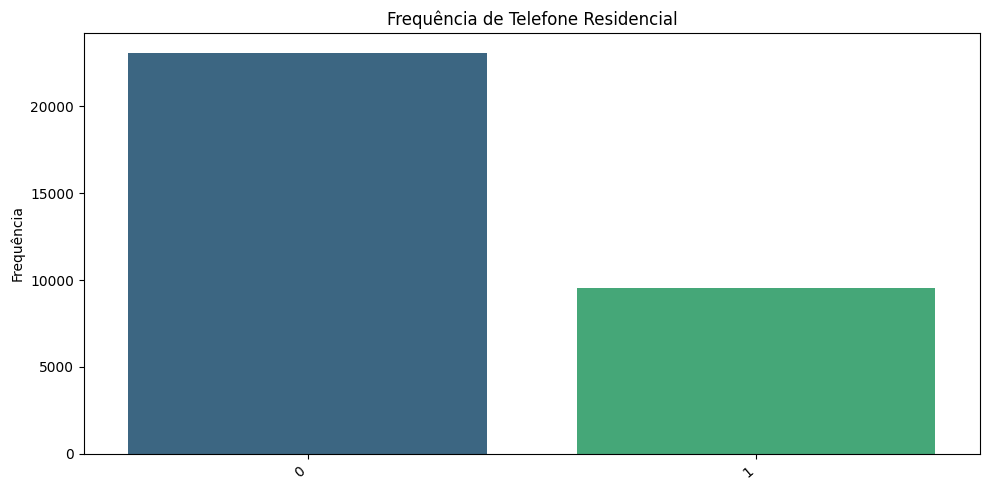

#### Interpretação da distribuição

A categoria 0 concentra 70.8% dos registros de telefone residencial, evidenciando a composição dessa informação cadastral na base.

In [ ]:
# Apresenta frequência e relação de telefone residencial com o TARGET
plot_frequencia(base_modelagem, "FLAG_PHONE", "Frequência de Telefone Residencial")

freq = base_modelagem["FLAG_PHONE"].value_counts(normalize=True, dropna=False)
principal = freq.index[0]
pct = freq.iloc[0] * 100
display(Markdown(
    "#### Interpretação da distribuição\n\n"
    f"A categoria {principal} concentra {pct:.1f}% dos registros de telefone residencial, "
    "evidenciando a composição dessa informação cadastral na base."
))



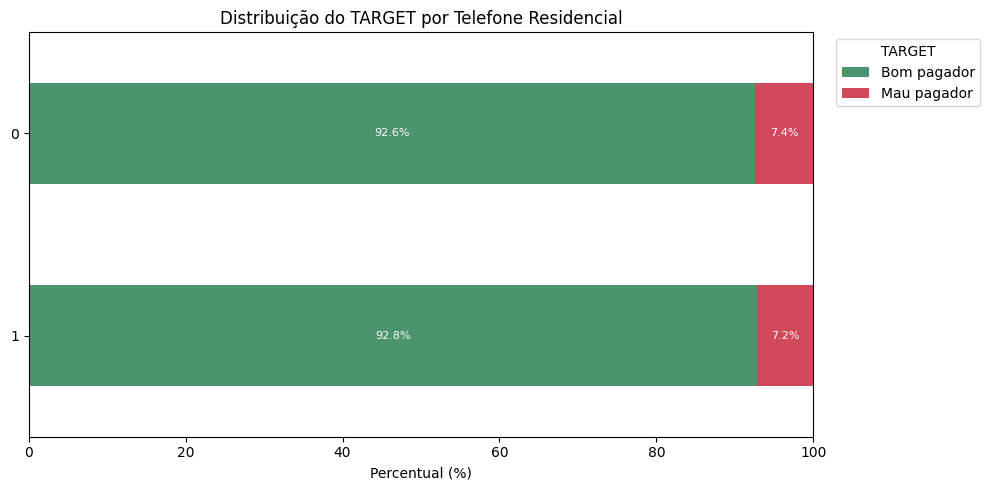

#### Interpretação da relação com o TARGET

As taxas de inadimplência variam de 7.2% a 7.4%, diferença de 0.2 pontos percentuais. Diferenças pequenas indicam que a variável apresenta baixa capacidade isolada de distinguir bons e maus pagadores.

In [ ]:
# Compara posse de telefone residencial com o TARGET
plot_target_categoria(base_modelagem, "FLAG_PHONE", "Distribuição do TARGET por Telefone Residencial")

taxas = base_modelagem.groupby("FLAG_PHONE")["TARGET"].mean().mul(100).sort_values(ascending=False)
dif = taxas.max() - taxas.min()
display(Markdown(
    "#### Interpretação da relação com o TARGET\n\n"
    f"As taxas de inadimplência variam de {taxas.min():.1f}% a {taxas.max():.1f}%, "
    f"diferença de {dif:.1f} pontos percentuais. Diferenças pequenas indicam que "
    "a variável apresenta baixa capacidade isolada de distinguir bons e maus pagadores."
))

#### 12 - E-mail

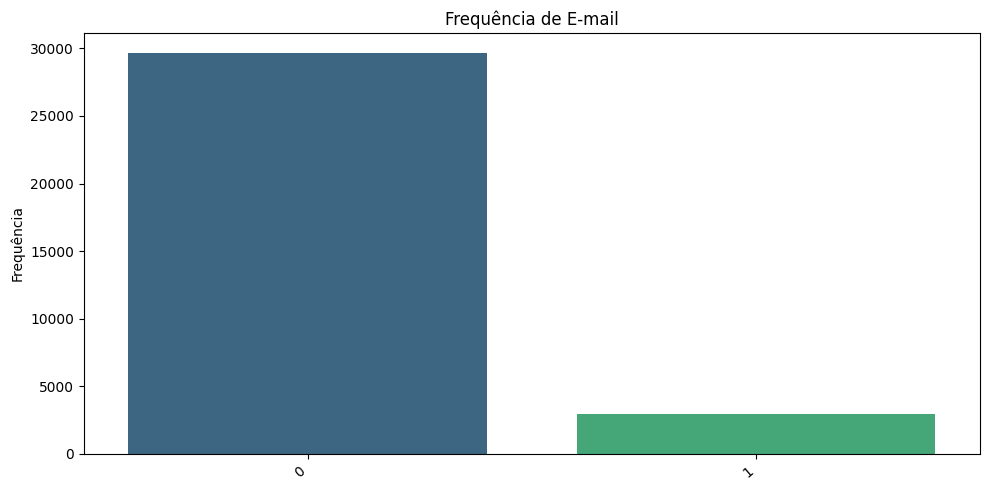

#### Interpretação da distribuição

A categoria 0 concentra 91.0% dos registros de e-mail, evidenciando a composição dessa informação cadastral na base.

In [ ]:
# Apresenta frequência e relação de e-mail com o TARGET
plot_frequencia(base_modelagem, "FLAG_EMAIL", "Frequência de E-mail")

freq = base_modelagem["FLAG_EMAIL"].value_counts(normalize=True, dropna=False)
principal = freq.index[0]
pct = freq.iloc[0] * 100
display(Markdown(
    "#### Interpretação da distribuição\n\n"
    f"A categoria {principal} concentra {pct:.1f}% dos registros de e-mail, "
    "evidenciando a composição dessa informação cadastral na base."
))



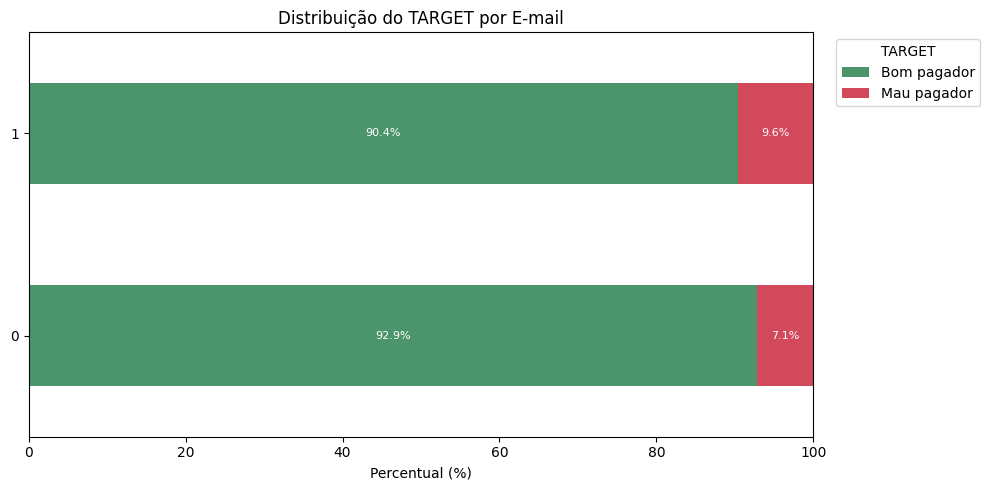

#### Interpretação da relação com o TARGET

As taxas de inadimplência variam de 7.1% a 9.6%, diferença de 2.4 pontos percentuais. Diferenças pequenas indicam que a variável apresenta baixa capacidade isolada de distinguir bons e maus pagadores.

In [ ]:
plot_target_categoria(base_modelagem, "FLAG_EMAIL", "Distribuição do TARGET por E-mail")

taxas = base_modelagem.groupby("FLAG_EMAIL")["TARGET"].mean().mul(100).sort_values(ascending=False)
dif = taxas.max() - taxas.min()
display(Markdown(
    "#### Interpretação da relação com o TARGET\n\n"
    f"As taxas de inadimplência variam de {taxas.min():.1f}% a {taxas.max():.1f}%, "
    f"diferença de {dif:.1f} pontos percentuais. Diferenças pequenas indicam que "
    "a variável apresenta baixa capacidade isolada de distinguir bons e maus pagadores."
))

### e) Variáveis numéricas

In [ ]:
# Cria faixas exclusivamente para a interpretação exploratória
base_modelagem["FAIXA_IDADE_EDA"] = pd.cut(
    base_modelagem["YEARS_BIRTH"],
    bins=[18, 26, 36, 46, 56, 66, np.inf],
    labels=["18 a 25", "26 a 35", "36 a 45", "46 a 55", "56 a 65", "66 ou mais"],
    right=False
)

base_modelagem["FAIXA_EMPREGO_EDA"] = pd.cut(
    base_modelagem["YEARS_EMPLOYED"],
    bins=[-0.01, 0, 2, 5, 10, 20, np.inf],
    labels=["0", "Até 2", "2 a 5", "5 a 10", "10 a 20", "Acima de 20"],
    include_lowest=True
)

base_modelagem["FAIXA_FILHOS_EDA"] = pd.cut(
    base_modelagem["CNT_CHILDREN"],
    bins=[-1, 0, 1, 2, np.inf],
    labels=["0 filhos", "1 filho", "2 filhos", "3 ou mais"],
    right=True,
    include_lowest=True
)

base_modelagem["FAIXA_FAMILIA_EDA"] = pd.cut(
    base_modelagem["CNT_FAM_MEMBERS"],
    bins=[0, 1, 2, 3, 4, np.inf],
    labels=["1 membro", "2 membros", "3 membros", "4 membros", "5 ou mais"],
    right=True,
    include_lowest=True
)

base_modelagem["DECIL_RENDA_EDA"] = pd.qcut(
    base_modelagem["AMT_INCOME_TOTAL"], q=10, duplicates="drop"
)

base_modelagem["DECIL_RENDA_PC_EDA"] = pd.qcut(
    base_modelagem["INCOME_PER_CAPITA"], q=10, duplicates="drop"
)

print("Registros com zero ou menos membros da família:", int((base_modelagem["CNT_FAM_MEMBERS"] <= 0).sum()))

Registros com zero ou menos membros da família: 0


#### 1 - Idade

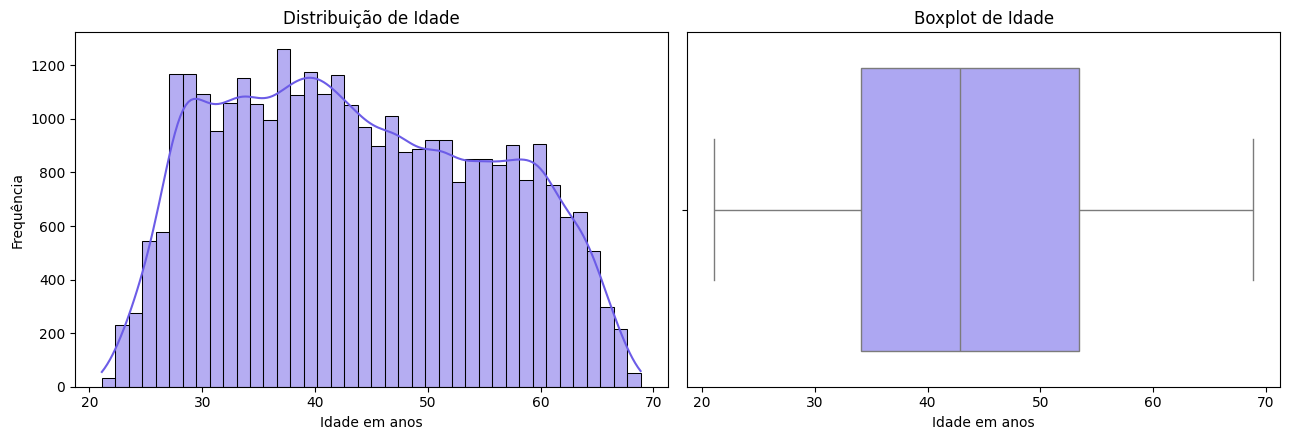

#### Interpretação da distribuição

A variável apresenta mediana de 42.9, com 50% dos valores entre 34.1 e 53.4. Os registros variam de 21.1 a 68.9. O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a concentração central e possíveis valores estatisticamente atípicos, que não devem ser removidos automaticamente.

In [ ]:
# Apresenta histograma e boxplot de idade
plot_numerica(base_modelagem, "YEARS_BIRTH", "Idade", "Idade em anos")

serie = base_modelagem["YEARS_BIRTH"].dropna()
mediana = serie.median()
q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
minimo = serie.min()
maximo = serie.max()

texto = (
    f"A variável apresenta mediana de {mediana:.1f}, com 50% dos valores entre "
    f"{q1:.1f} e {q3:.1f}. Os registros variam de {minimo:.1f} a {maximo:.1f}. "
    "O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a "
    "concentração central e possíveis valores estatisticamente atípicos, que não devem "
    "ser removidos automaticamente."
)
display(Markdown("#### Interpretação da distribuição\n\n" + texto))

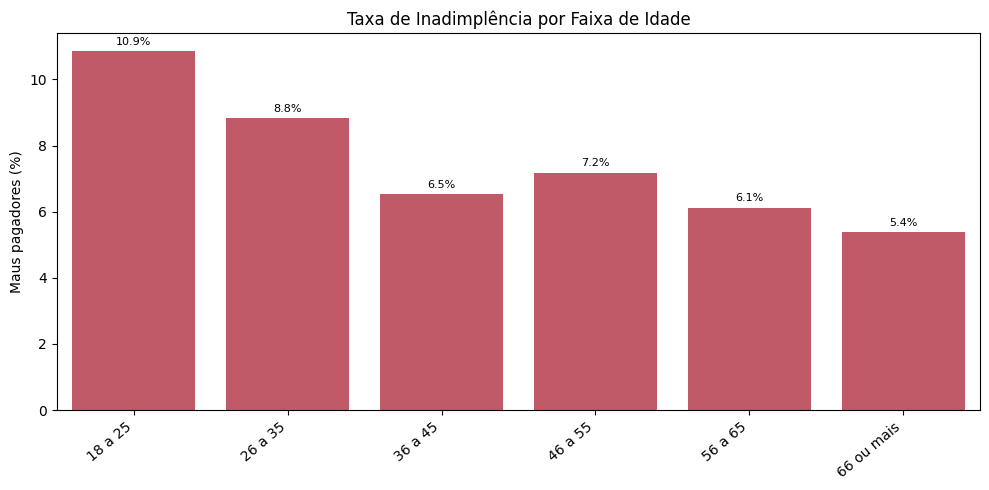

,FAIXA_IDADE_EDA,Quantidade,Taxa de inadimplência (%)
0,18 a 25,1123,10.863758
1,26 a 35,8708,8.830960
2,36 a 45,9031,6.521980
3,46 a 55,7392,7.183442
4,56 a 65,5992,6.124833
5,66 ou mais,371,5.390836


#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em 18 a 25 (10.9%), enquanto a menor ocorre em 66 ou mais (5.4%). A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. Grupos pequenos podem apresentar percentuais mais instáveis.

In [ ]:
# Compara idade com o TARGET por faixas
plot_target_faixa(base_modelagem, "FAIXA_IDADE_EDA", "Taxa de Inadimplência por Faixa de Idade")

taxas = (
    base_modelagem.groupby("FAIXA_IDADE_EDA", observed=True)["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .dropna()
)
maior_grupo = taxas["Taxa"].idxmax()
menor_grupo = taxas["Taxa"].idxmin()
maior_taxa = taxas["Taxa"].max() * 100
menor_taxa = taxas["Taxa"].min() * 100

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_grupo} ({maior_taxa:.1f}%), "
    f"enquanto a menor ocorre em {menor_grupo} ({menor_taxa:.1f}%). "
    "A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. "
    "Grupos pequenos podem apresentar percentuais mais instáveis."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 2 - Tempo de emprego

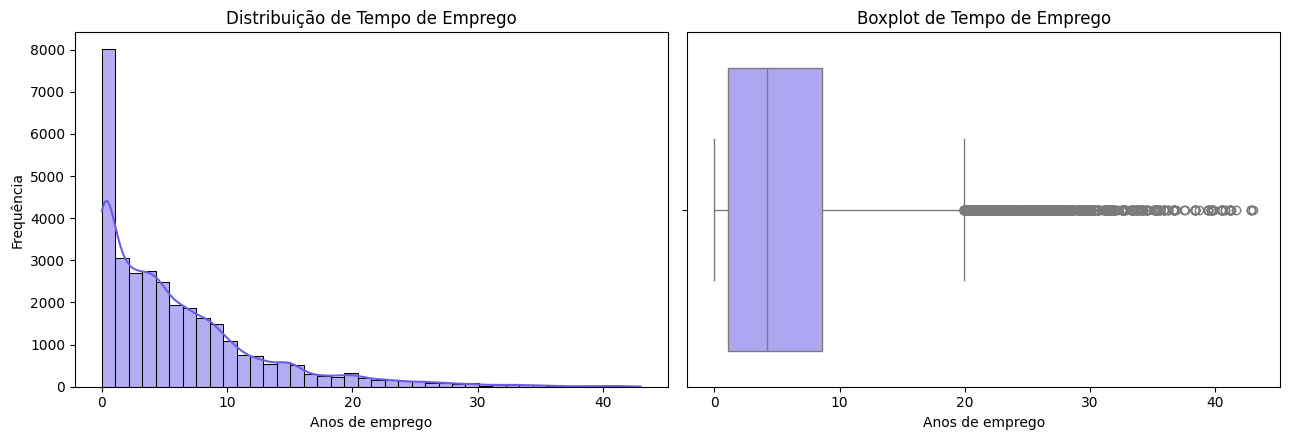

#### Interpretação da distribuição

A variável apresenta mediana de 4.2, com 50% dos valores entre 1.1 e 8.6. Os registros variam de 0.0 a 43.0. O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a concentração central e possíveis valores estatisticamente atípicos, que não devem ser removidos automaticamente.

In [ ]:
# Apresenta histograma e boxplot de tempo de emprego
plot_numerica(base_modelagem, "YEARS_EMPLOYED", "Tempo de Emprego", "Anos de emprego")

serie = base_modelagem["YEARS_EMPLOYED"].dropna()
mediana = serie.median()
q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
minimo = serie.min()
maximo = serie.max()

texto = (
    f"A variável apresenta mediana de {mediana:.1f}, com 50% dos valores entre "
    f"{q1:.1f} e {q3:.1f}. Os registros variam de {minimo:.1f} a {maximo:.1f}. "
    "O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a "
    "concentração central e possíveis valores estatisticamente atípicos, que não devem "
    "ser removidos automaticamente."
)
display(Markdown("#### Interpretação da distribuição\n\n" + texto))

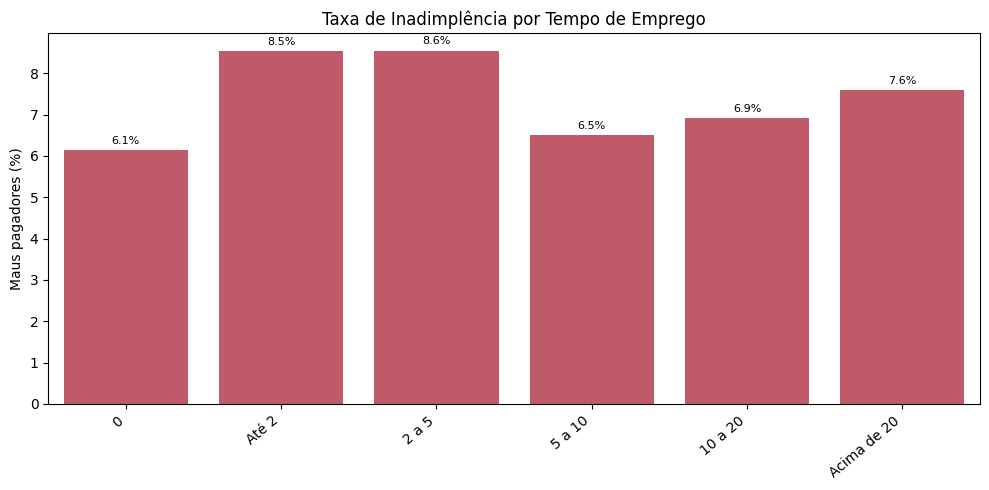

,FAIXA_EMPREGO_EDA,Quantidade,Taxa de inadimplência (%)
0,0,5571,6.138934
1,Até 2,5122,8.531824
2,2 a 5,7577,8.552197
3,5 a 10,7940,6.511335
4,10 a 20,4842,6.918629
5,Acima de 20,1565,7.603834


#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em 2 a 5 (8.6%), enquanto a menor ocorre em 0 (6.1%). A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. Grupos pequenos podem apresentar percentuais mais instáveis.

In [ ]:
# Compara tempo de emprego com o TARGET por faixas
plot_target_faixa(base_modelagem, "FAIXA_EMPREGO_EDA", "Taxa de Inadimplência por Tempo de Emprego")

taxas = (
    base_modelagem.groupby("FAIXA_EMPREGO_EDA", observed=True)["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .dropna()
)
maior_grupo = taxas["Taxa"].idxmax()
menor_grupo = taxas["Taxa"].idxmin()
maior_taxa = taxas["Taxa"].max() * 100
menor_taxa = taxas["Taxa"].min() * 100

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_grupo} ({maior_taxa:.1f}%), "
    f"enquanto a menor ocorre em {menor_grupo} ({menor_taxa:.1f}%). "
    "A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. "
    "Grupos pequenos podem apresentar percentuais mais instáveis."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 3 - Quantidade de filhos

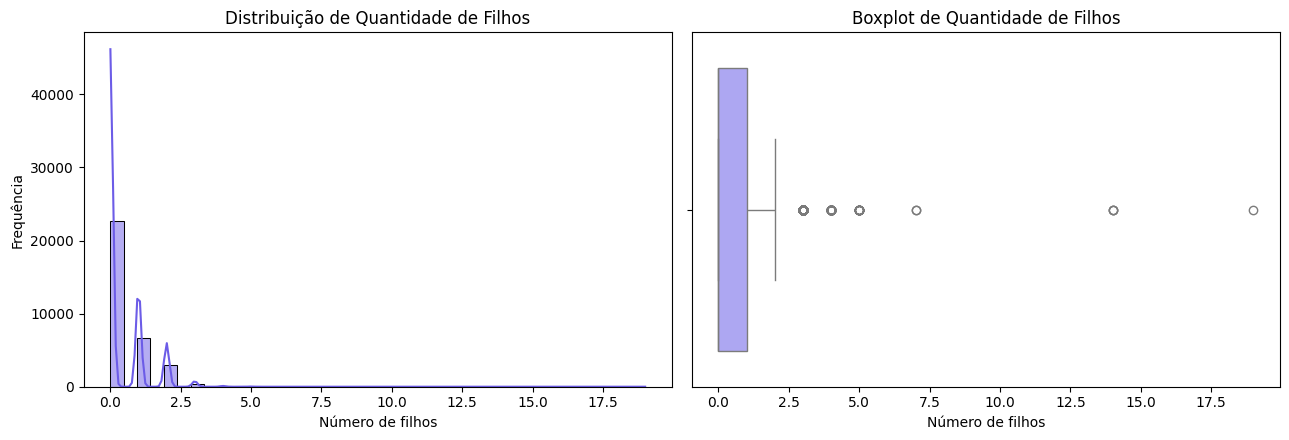

#### Interpretação da distribuição

A variável apresenta mediana de 0.0, com 50% dos valores entre 0.0 e 1.0. Os registros variam de 0.0 a 19.0. O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a concentração central e possíveis valores estatisticamente atípicos, que não devem ser removidos automaticamente.

In [ ]:
# Apresenta histograma e boxplot de quantidade de filhos
plot_numerica(base_modelagem, "CNT_CHILDREN", "Quantidade de Filhos", "Número de filhos")

serie = base_modelagem["CNT_CHILDREN"].dropna()
mediana = serie.median()
q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
minimo = serie.min()
maximo = serie.max()

texto = (
    f"A variável apresenta mediana de {mediana:.1f}, com 50% dos valores entre "
    f"{q1:.1f} e {q3:.1f}. Os registros variam de {minimo:.1f} a {maximo:.1f}. "
    "O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a "
    "concentração central e possíveis valores estatisticamente atípicos, que não devem "
    "ser removidos automaticamente."
)
display(Markdown("#### Interpretação da distribuição\n\n" + texto))

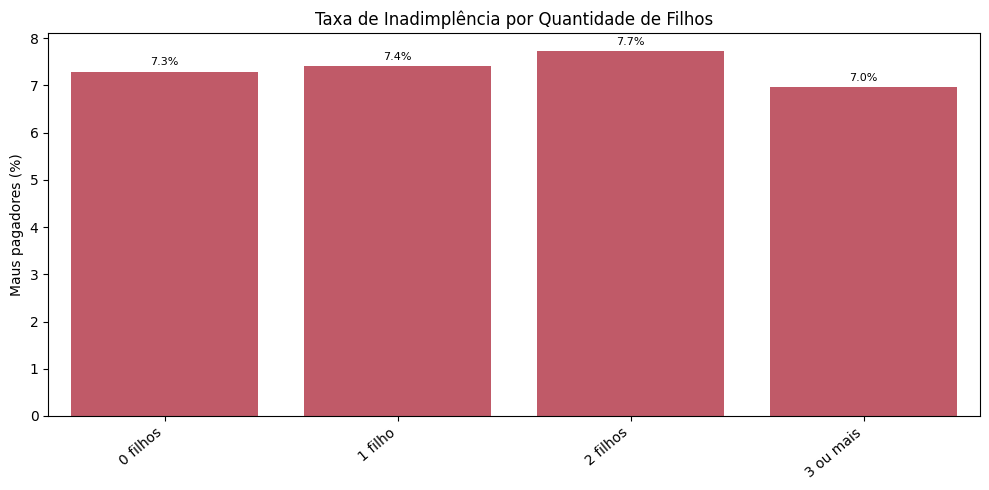

,FAIXA_FILHOS_EDA,Quantidade,Taxa de inadimplência (%)
0,0 filhos,22618,7.295075
1,1 filho,6630,7.405732
2,2 filhos,2924,7.729138
3,3 ou mais,445,6.966292


#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em 2 filhos (7.7%), enquanto a menor ocorre em 3 ou mais (7.0%). A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. Grupos pequenos podem apresentar percentuais mais instáveis.

In [ ]:
# Compara quantidade de filhos com o TARGET por faixas
plot_target_faixa(base_modelagem, "FAIXA_FILHOS_EDA", "Taxa de Inadimplência por Quantidade de Filhos")

taxas = (
    base_modelagem.groupby("FAIXA_FILHOS_EDA", observed=True)["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .dropna()
)
maior_grupo = taxas["Taxa"].idxmax()
menor_grupo = taxas["Taxa"].idxmin()
maior_taxa = taxas["Taxa"].max() * 100
menor_taxa = taxas["Taxa"].min() * 100

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_grupo} ({maior_taxa:.1f}%), "
    f"enquanto a menor ocorre em {menor_grupo} ({menor_taxa:.1f}%). "
    "A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. "
    "Grupos pequenos podem apresentar percentuais mais instáveis."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 4 - Membros da família


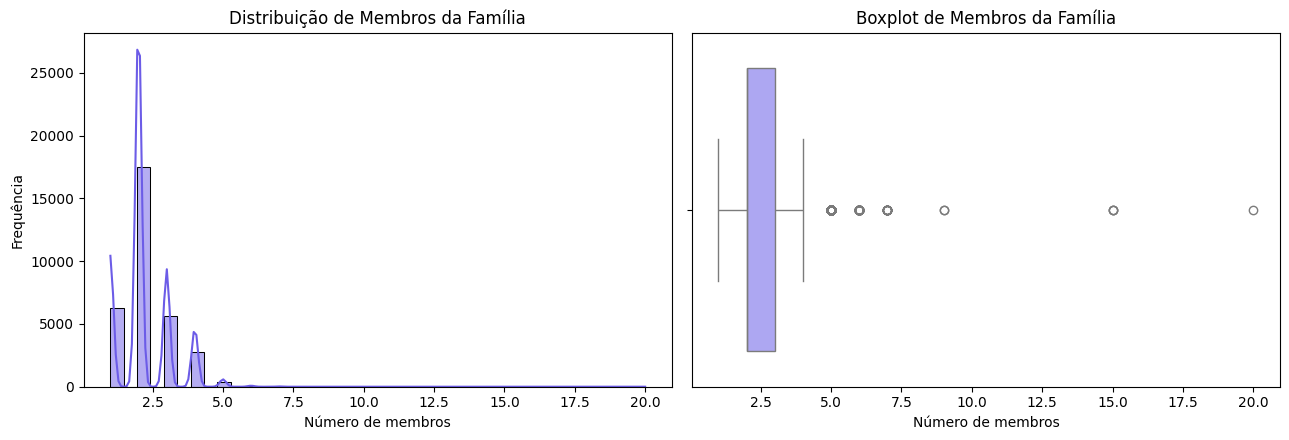

#### Interpretação da distribuição

A variável apresenta mediana de 2.0, com 50% dos valores entre 2.0 e 3.0. Os registros variam de 1.0 a 20.0. O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a concentração central e possíveis valores estatisticamente atípicos, que não devem ser removidos automaticamente.

In [ ]:
# Apresenta histograma e boxplot de membros da família
plot_numerica(base_modelagem, "CNT_FAM_MEMBERS", "Membros da Família", "Número de membros")

serie = base_modelagem["CNT_FAM_MEMBERS"].dropna()
mediana = serie.median()
q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
minimo = serie.min()
maximo = serie.max()

texto = (
    f"A variável apresenta mediana de {mediana:.1f}, com 50% dos valores entre "
    f"{q1:.1f} e {q3:.1f}. Os registros variam de {minimo:.1f} a {maximo:.1f}. "
    "O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a "
    "concentração central e possíveis valores estatisticamente atípicos, que não devem "
    "ser removidos automaticamente."
)
display(Markdown("#### Interpretação da distribuição\n\n" + texto))

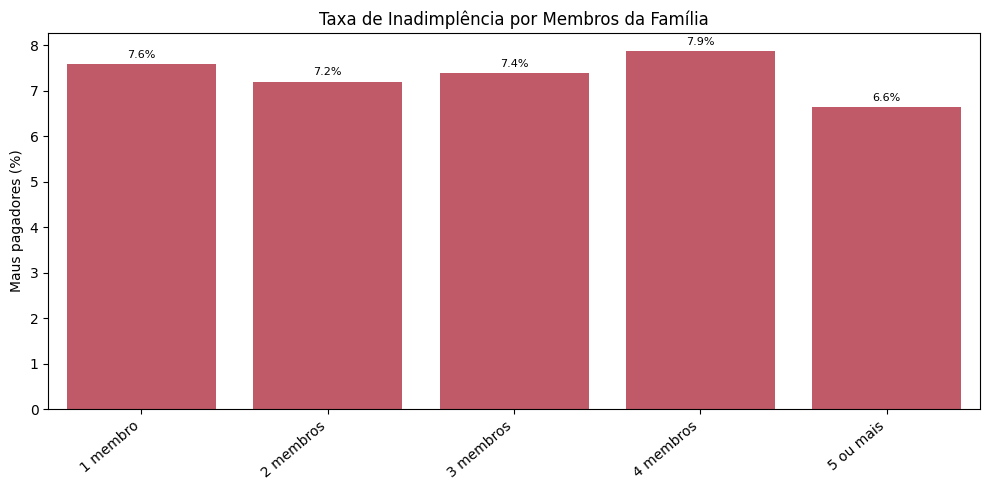

,FAIXA_FAMILIA_EDA,Quantidade,Taxa de inadimplência (%)
0,1 membro,6278,7.582032
1,2 membros,17484,7.195150
2,3 membros,5639,7.377195
3,4 membros,2794,7.874016
4,5 ou mais,422,6.635071


#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em 4 membros (7.9%), enquanto a menor ocorre em 5 ou mais (6.6%). A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. Grupos pequenos podem apresentar percentuais mais instáveis.

In [ ]:
# Compara membros da família com o TARGET por faixas
plot_target_faixa(base_modelagem, "FAIXA_FAMILIA_EDA", "Taxa de Inadimplência por Membros da Família")

taxas = (
    base_modelagem.groupby("FAIXA_FAMILIA_EDA", observed=True)["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .dropna()
)
maior_grupo = taxas["Taxa"].idxmax()
menor_grupo = taxas["Taxa"].idxmin()
maior_taxa = taxas["Taxa"].max() * 100
menor_taxa = taxas["Taxa"].min() * 100

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_grupo} ({maior_taxa:.1f}%), "
    f"enquanto a menor ocorre em {menor_grupo} ({menor_taxa:.1f}%). "
    "A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. "
    "Grupos pequenos podem apresentar percentuais mais instáveis."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 5 - Renda familiar total

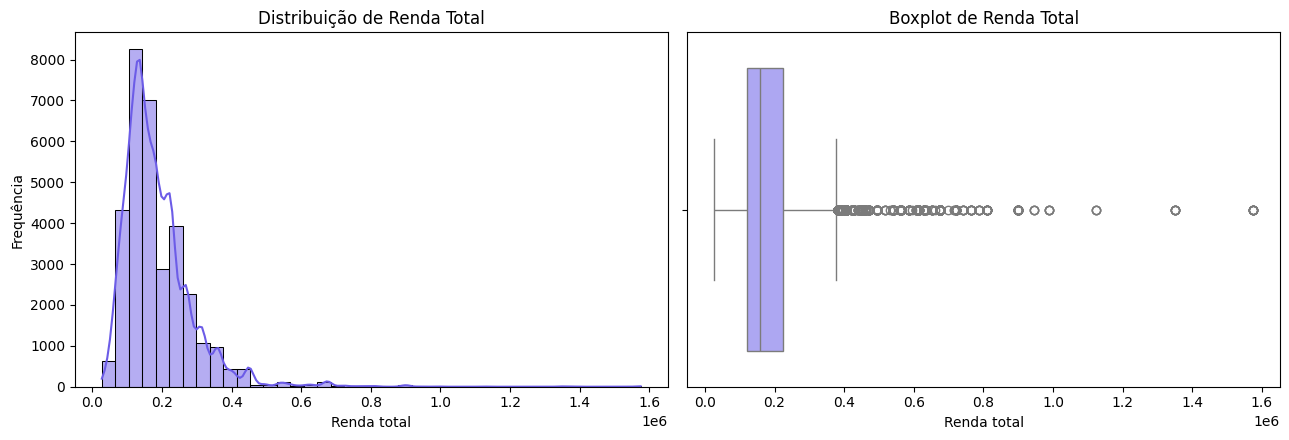

#### Interpretação da distribuição

A variável apresenta mediana de 157500.0, com 50% dos valores entre 121500.0 e 225000.0. Os registros variam de 27000.0 a 1575000.0. O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a concentração central e possíveis valores estatisticamente atípicos, que não devem ser removidos automaticamente.

In [ ]:
# Apresenta histograma e boxplot de renda total
plot_numerica(base_modelagem, "AMT_INCOME_TOTAL", "Renda Total", "Renda total")

serie = base_modelagem["AMT_INCOME_TOTAL"].dropna()
mediana = serie.median()
q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
minimo = serie.min()
maximo = serie.max()

texto = (
    f"A variável apresenta mediana de {mediana:.1f}, com 50% dos valores entre "
    f"{q1:.1f} e {q3:.1f}. Os registros variam de {minimo:.1f} a {maximo:.1f}. "
    "O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a "
    "concentração central e possíveis valores estatisticamente atípicos, que não devem "
    "ser removidos automaticamente."
)
display(Markdown("#### Interpretação da distribuição\n\n" + texto))

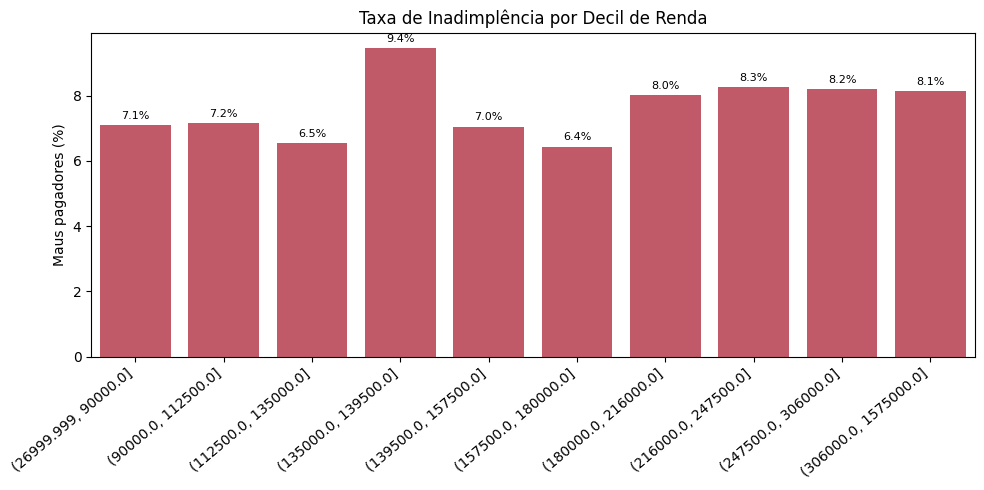

,DECIL_RENDA_EDA,Quantidade,Taxa de inadimplência (%)
0,"(26999.999, 90000.0]",4070,7.100737
1,"(90000.0, 112500.0]",3733,7.152424
2,"(112500.0, 135000.0]",5238,6.548301
3,"(135000.0, 139500.0]",127,9.448819
4,"(139500.0, 157500.0]",3533,7.047835
5,"(157500.0, 180000.0]",3495,6.437768
6,"(180000.0, 216000.0]",2884,8.009709
7,"(216000.0, 247500.0]",3729,8.259587
8,"(247500.0, 306000.0]",2549,8.199294
9,"(306000.0, 1575000.0]",3259,8.131329


#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em (135000.0, 139500.0] (9.4%), enquanto a menor ocorre em (157500.0, 180000.0] (6.4%). A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. Grupos pequenos podem apresentar percentuais mais instáveis.

In [ ]:
# Compara renda total com o TARGET por faixas
plot_target_faixa(base_modelagem, "DECIL_RENDA_EDA", "Taxa de Inadimplência por Decil de Renda")

taxas = (
    base_modelagem.groupby("DECIL_RENDA_EDA", observed=True)["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .dropna()
)
maior_grupo = taxas["Taxa"].idxmax()
menor_grupo = taxas["Taxa"].idxmin()
maior_taxa = taxas["Taxa"].max() * 100
menor_taxa = taxas["Taxa"].min() * 100

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_grupo} ({maior_taxa:.1f}%), "
    f"enquanto a menor ocorre em {menor_grupo} ({menor_taxa:.1f}%). "
    "A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. "
    "Grupos pequenos podem apresentar percentuais mais instáveis."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 6 - Renda per-capita

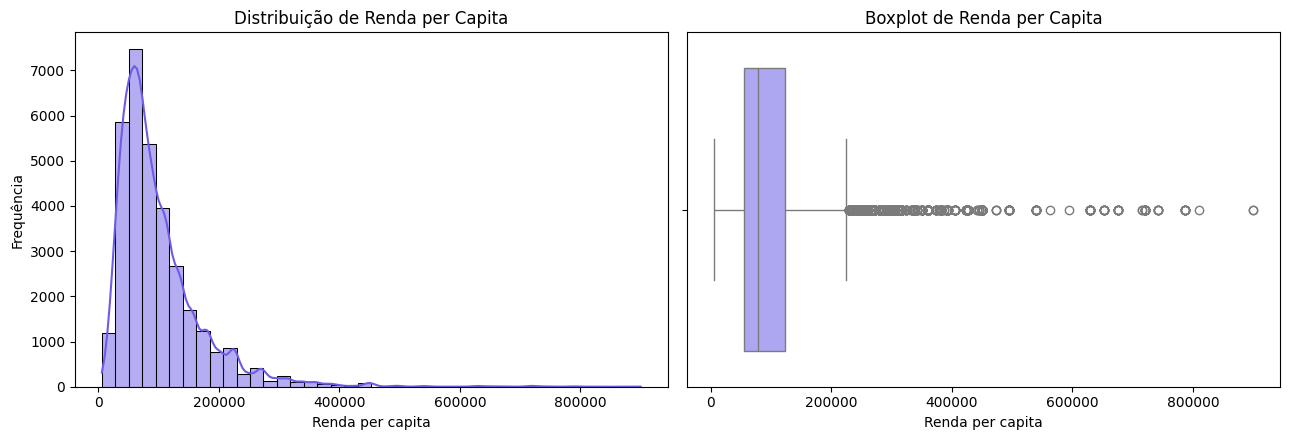

#### Interpretação da distribuição

A variável apresenta mediana de 78750.0, com 50% dos valores entre 55500.0 e 123750.0. Os registros variam de 5625.0 a 900000.0. O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a concentração central e possíveis valores estatisticamente atípicos, que não devem ser removidos automaticamente.

In [ ]:
# Apresenta histograma e boxplot de renda per capita
plot_numerica(base_modelagem, "INCOME_PER_CAPITA", "Renda per Capita", "Renda per capita")

serie = base_modelagem["INCOME_PER_CAPITA"].dropna()
mediana = serie.median()
q1 = serie.quantile(0.25)
q3 = serie.quantile(0.75)
minimo = serie.min()
maximo = serie.max()

texto = (
    f"A variável apresenta mediana de {mediana:.1f}, com 50% dos valores entre "
    f"{q1:.1f} e {q3:.1f}. Os registros variam de {minimo:.1f} a {maximo:.1f}. "
    "O histograma mostra a forma da distribuição, enquanto o boxplot evidencia a "
    "concentração central e possíveis valores estatisticamente atípicos, que não devem "
    "ser removidos automaticamente."
)
display(Markdown("#### Interpretação da distribuição\n\n" + texto))

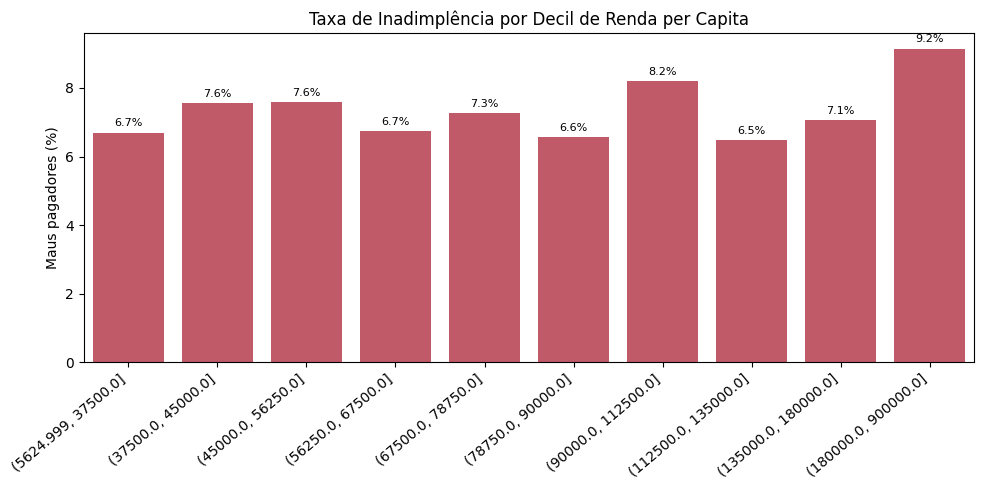

,DECIL_RENDA_PC_EDA,Quantidade,Taxa de inadimplência (%)
0,"(5624.999, 37500.0]",3627,6.699752
1,"(37500.0, 45000.0]",2913,7.552352
2,"(45000.0, 56250.0]",3439,7.589416
3,"(56250.0, 67500.0]",4107,6.744582
4,"(67500.0, 78750.0]",2764,7.272069
5,"(78750.0, 90000.0]",2836,6.558533
6,"(90000.0, 112500.0]",4020,8.208955
7,"(112500.0, 135000.0]",2747,6.479796
8,"(135000.0, 180000.0]",2973,7.063572
9,"(180000.0, 900000.0]",3191,9.150736


#### Interpretação da relação com o TARGET

A maior taxa de inadimplência ocorre em (180000.0, 900000.0] (9.2%), enquanto a menor ocorre em (112500.0, 135000.0] (6.5%). A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. Grupos pequenos podem apresentar percentuais mais instáveis.

In [ ]:
# Compara renda per capita com o TARGET por faixas
plot_target_faixa(base_modelagem, "DECIL_RENDA_PC_EDA", "Taxa de Inadimplência por Decil de Renda per Capita")

taxas = (
    base_modelagem.groupby("DECIL_RENDA_PC_EDA", observed=True)["TARGET"]
    .agg(Quantidade="size", Taxa="mean")
    .dropna()
)
maior_grupo = taxas["Taxa"].idxmax()
menor_grupo = taxas["Taxa"].idxmin()
maior_taxa = taxas["Taxa"].max() * 100
menor_taxa = taxas["Taxa"].min() * 100

texto = (
    f"A maior taxa de inadimplência ocorre em {maior_grupo} ({maior_taxa:.1f}%), "
    f"enquanto a menor ocorre em {menor_grupo} ({menor_taxa:.1f}%). "
    "A comparação é descritiva e deve considerar a quantidade de clientes em cada faixa. "
    "Grupos pequenos podem apresentar percentuais mais instáveis."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

#### 7 - Distribuição logarítmica da renda

#### Interpretação da relação com o TARGET

A transformação reduz a influência visual das rendas mais elevadas e facilita a visualização da região de maior concentração. Se adotada na modelagem, deverá ser aplicada no pipeline do Notebook 03 e ajustada somente com os dados de treinamento.

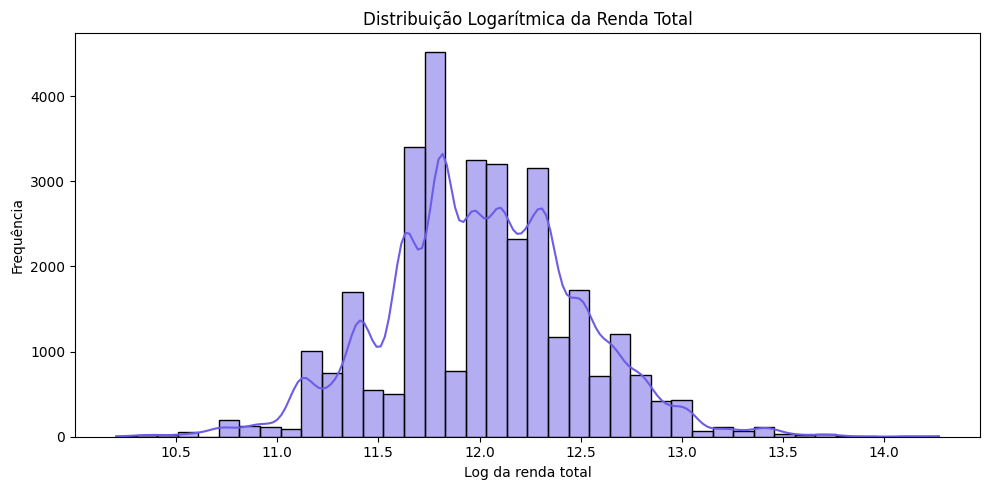

In [ ]:
# Aplica transformação logarítmica somente para visualização
base_modelagem["LOG_INCOME_EDA"] = np.log1p(base_modelagem["AMT_INCOME_TOTAL"])
plt.figure(figsize=(10, 5))
sns.histplot(data=base_modelagem, x="LOG_INCOME_EDA", bins=40, kde=True, color="#6C5CE7")
plt.title("Distribuição Logarítmica da Renda Total")
plt.xlabel("Log da renda total")
plt.ylabel("Frequência")
plt.tight_layout()

texto = (
    f"A transformação reduz a influência visual das rendas mais elevadas e facilita a visualização da região de maior concentração. Se adotada na modelagem, deverá ser aplicada no pipeline do Notebook 03 e ajustada somente com os dados de treinamento."
)
display(Markdown("#### Interpretação da relação com o TARGET\n\n" + texto))

plt.show()

### f) Análise de correlações

### Definição das correlações

A matriz de correlação de Spearman permite avaliar a intensidade e a direção das associações monotônicas entre as variáveis numéricas. Em relação ao TARGET, as correlações observadas são muito fracas, variando aproximadamente entre -0,04 e 0,03. Portanto, nenhuma das características analisadas apresenta, isoladamente, forte associação monotônica com a classificação entre bons e maus pagadores.

As baixas correlações com o TARGET não significam que as variáveis sejam necessariamente irrelevantes para a modelagem. Os modelos poderão identificar relações não lineares, interações e combinações entre características que não são representadas adequadamente por uma correlação individual.

Entre as variáveis explicativas, destaca-se a correlação positiva forte de aproximadamente 0,82 entre CNT_CHILDREN e CNT_FAM_MEMBERS. Esse resultado é esperado, pois a quantidade de filhos participa diretamente da composição familiar.

Também foi identificada correlação positiva forte de aproximadamente 0,73 entre AMT_INCOME_TOTAL e INCOME_PER_CAPITA. Essa associação é coerente porque a renda per capita é calculada a partir da renda total e da quantidade de membros da família.

INCOME_PER_CAPITA apresenta correlação negativa de aproximadamente -0,63 com CNT_FAM_MEMBERS e de -0,46 com CNT_CHILDREN. Esse comportamento é coerente com a construção da variável, pois o aumento da quantidade de integrantes tende a reduzir a renda disponível por pessoa quando a renda familiar permanece constante. Por esse motivo, renda total, renda per capita, quantidade de filhos e número de membros da família devem ser interpretados conjuntamente.

YEARS_EMPLOYED apresenta correlação negativa moderada de aproximadamente -0,65 com IS_RETIRED e EMPLOYMENT_SPECIAL_VALUE. Essa associação decorre principalmente do tratamento do código especial 365243, que recebeu valor zero em YEARS_EMPLOYED. Como todos os registros com esse código pertencem à categoria Pensioner, os clientes pensionistas ficaram concentrados no valor zero da variável tratada.

YEARS_BIRTH também apresenta correlação positiva moderada de aproximadamente 0,59 com IS_RETIRED e EMPLOYMENT_SPECIAL_VALUE. Esse resultado é coerente com a maior concentração da condição de pensionista entre clientes de idade mais elevada. Como YEARS_BIRTH representa a idade em anos, valores maiores correspondem a clientes mais velhos.

IS_RETIRED e EMPLOYMENT_SPECIAL_VALUE apresentam correlação igual a 1,00, indicando associação praticamente perfeita entre as duas variáveis na base analisada. Apesar disso, as variáveis representam conceitos diferentes. IS_RETIRED identifica todos os clientes classificados como Pensioner, enquanto EMPLOYMENT_SPECIAL_VALUE registra somente os casos que possuíam o código especial 365243 em DAYS_EMPLOYED.

A correlação praticamente perfeita decorre do fato de todos os registros com o código especial pertencerem à categoria Pensioner e de apenas 17 pensionistas possuírem valores regulares em DAYS_EMPLOYED. Embora exista essa pequena diferença conceitual e operacional, ela não foi suficiente para alterar o coeficiente apresentado na matriz com duas casas decimais. Portanto, as duas variáveis carregam informações altamente redundantes.

Diante dessa redundância, foi decidido manter IS_RETIRED na base destinada ao Notebook 03, pois essa variável possui interpretação cadastral e operacional mais direta. EMPLOYMENT_SPECIAL_VALUE permanecerá somente na base completa para documentação e auditoria do tratamento realizado, não devendo integrar a matriz preditiva.

EMPLOYMENT_NOT_INFORMED não foi incluída na matriz de correlação porque permaneceu constante em zero. Como uma variável constante não apresenta variabilidade, não é possível estabelecer uma correlação informativa com as demais variáveis nem utilizá-la para diferenciar os clientes. Por esse motivo, ela também não será encaminhada à modelagem.

As associações identificadas descrevem padrões existentes na base, mas não representam relações causais. A correlação indica apenas que duas variáveis apresentam comportamento conjunto, sem demonstrar que uma delas provoque alterações na outra.

A etapa de modelagem deverá avaliar a contribuição conjunta das variáveis, verificar possíveis relações não lineares e analisar se as características produzem ganho efetivo de desempenho. A permanência definitiva das variáveis deverá considerar os resultados dos modelos, a importância das características, a estabilidade das métricas e a coerência das relações identificadas

#### 1 - Matriz de correlação

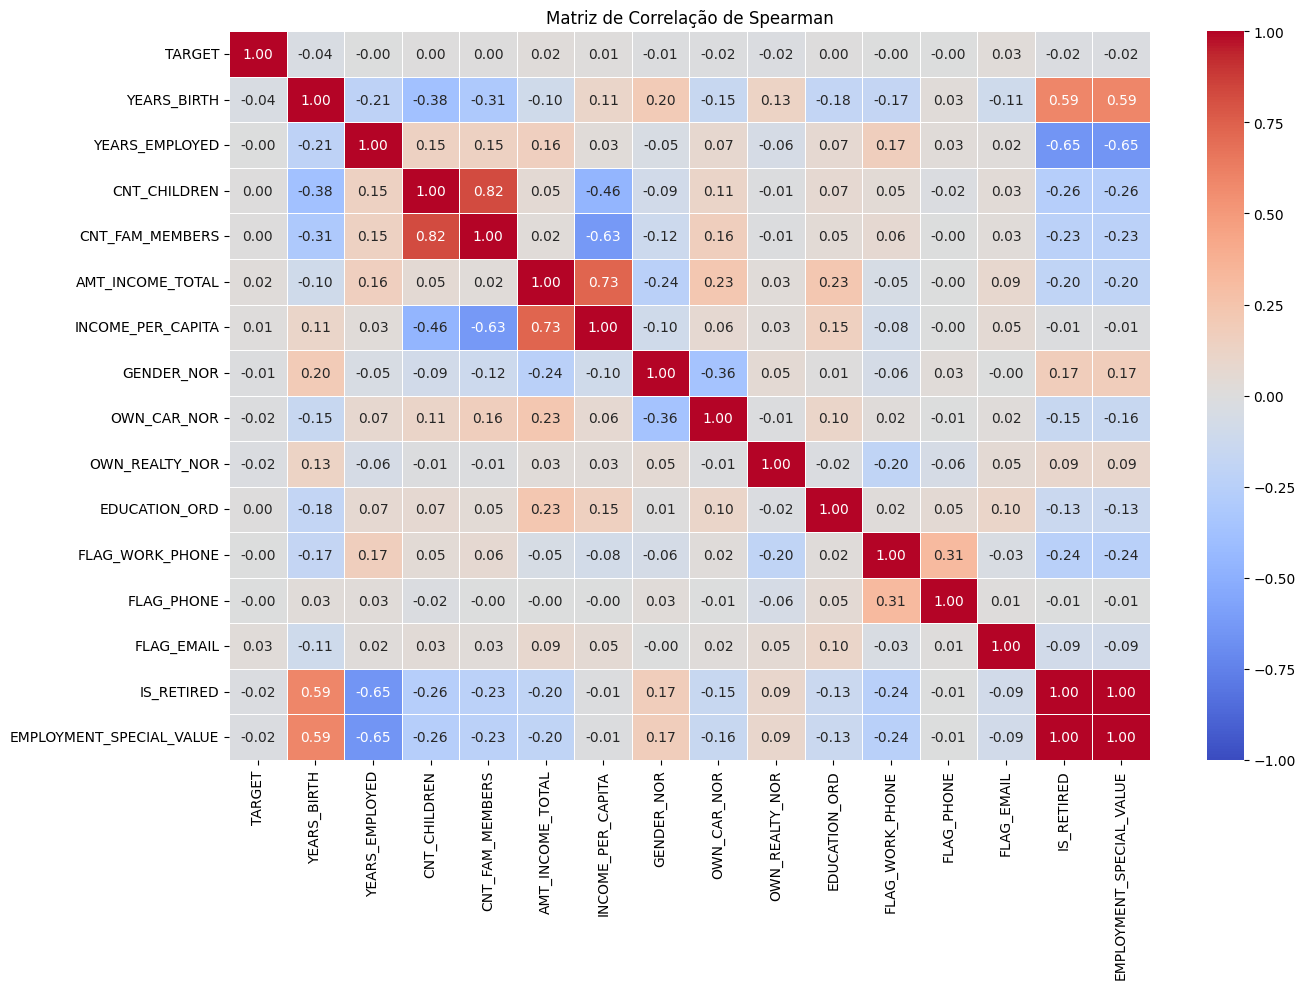

,Correlação com TARGET
YEARS_BIRTH,-0.038574
EMPLOYMENT_SPECIAL_VALUE,-0.021095
IS_RETIRED,-0.018653
OWN_REALTY_NOR,-0.018285
OWN_CAR_NOR,-0.015082
GENDER_NOR,-0.010473
FLAG_PHONE,-0.004136
YEARS_EMPLOYED,-0.003820
FLAG_WORK_PHONE,-0.002210
CNT_FAM_MEMBERS,0.000309


EMPLOYMENT_NOT_INFORMED
0    32617
Name: count, dtype: int64
Quantidade de valores únicos: 1


In [ ]:
# Calcula a matriz de correlação de Spearman
variaveis_correlacao=["TARGET","YEARS_BIRTH","YEARS_EMPLOYED","CNT_CHILDREN","CNT_FAM_MEMBERS","AMT_INCOME_TOTAL","INCOME_PER_CAPITA","GENDER_NOR","OWN_CAR_NOR","OWN_REALTY_NOR","EDUCATION_ORD","FLAG_WORK_PHONE","FLAG_PHONE","FLAG_EMAIL","IS_RETIRED","EMPLOYMENT_SPECIAL_VALUE"]
matriz_correlacao=base_modelagem[variaveis_correlacao].corr(method="spearman")
plt.figure(figsize=(14,10))
sns.heatmap(matriz_correlacao,annot=True,cmap="coolwarm",fmt=".2f",center=0,vmin=-1,vmax=1,linewidths=.5)
plt.title("Matriz de Correlação de Spearman"); plt.tight_layout(); plt.show()
display(matriz_correlacao["TARGET"].drop("TARGET").sort_values().to_frame("Correlação com TARGET"))

# Verifica a distribuição de EMPLOYMENT_NOT_INFORMED
print(base_modelagem["EMPLOYMENT_NOT_INFORMED"].value_counts(dropna=False))
print("Quantidade de valores únicos:",base_modelagem["EMPLOYMENT_NOT_INFORMED"].nunique(dropna=False))

### g) Outliers

valores estatisticamente atípicos nas principais variáveis numéricas por meio do intervalo interquartil. A classificação como outlier não significa, por si só, que o registro esteja incorreto, pois valores extremos podem representar situações reais da população analisada.

In [ ]:
# Identifica valores atípicos pelo intervalo interquartil
variaveis_outliers = ["AMT_INCOME_TOTAL", "INCOME_PER_CAPITA", "YEARS_EMPLOYED", "CNT_CHILDREN", "CNT_FAM_MEMBERS"]
resumo = []
for coluna in variaveis_outliers:
    valores = base_modelagem[coluna].dropna()
    q1, q3 = valores.quantile(0.25), valores.quantile(0.75)
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mascara = (valores < inferior) | (valores > superior)
    resumo.append({"Variável": coluna, "Q1": round(q1, 2), "Q3": round(q3, 2), "Limite inferior": round(inferior, 2), "Limite superior": round(superior, 2), "Quantidade": int(mascara.sum()), "Percentual (%)": round(mascara.mean() * 100, 2)})
display(pd.DataFrame(resumo))

,Variável,Q1,Q3,Limite inferior,Limite superior,Quantidade,Percentual (%)
0,AMT_INCOME_TOTAL,121500.00,225000.00,-33750.00,380250.00,1323,4.06
1,INCOME_PER_CAPITA,55500.00,123750.00,-46875.00,226125.00,1555,4.77
2,YEARS_EMPLOYED,1.11,8.63,-10.18,19.92,1587,4.87
3,CNT_CHILDREN,0.00,1.00,-1.50,2.50,445,1.36
4,CNT_FAM_MEMBERS,2.00,3.00,0.50,4.50,422,1.29


In [ ]:
# Registra as decisões adotadas para os valores atípicos

tratamentos_outliers = pd.DataFrame({"Variável": ["AMT_INCOME_TOTAL", "INCOME_PER_CAPITA", "YEARS_EMPLOYED", "CNT_CHILDREN", "CNT_FAM_MEMBERS"], "Decisão adotada": ["Manter os valores originais", "Manter os valores originais", "Zerar somente o código especial 365243", "Manter os valores originais", "Manter os valores originais"], "Justificativa": ["Valores elevados podem representar rendas válidas", "Valores elevados podem representar situações reais", "O código especial não representa tempo real de emprego", "Valores extremos podem representar estruturas familiares reais", "Valores extremos podem representar estruturas familiares reais"]})

# Convertemos o DataFrame para uma string formatada em Markdown usando .to_markdown()
display(Markdown("#### Interpretação da distribuição\n\n" + tratamentos_outliers.to_markdown(index=False)))

#### Interpretação da distribuição

| Variável          | Decisão adotada                        | Justificativa                                                  |
|:------------------|:---------------------------------------|:---------------------------------------------------------------|
| AMT_INCOME_TOTAL  | Manter os valores originais            | Valores elevados podem representar rendas válidas              |
| INCOME_PER_CAPITA | Manter os valores originais            | Valores elevados podem representar situações reais             |
| YEARS_EMPLOYED    | Zerar somente o código especial 365243 | O código especial não representa tempo real de emprego         |
| CNT_CHILDREN      | Manter os valores originais            | Valores extremos podem representar estruturas familiares reais |
| CNT_FAM_MEMBERS   | Manter os valores originais            | Valores extremos podem representar estruturas familiares reais |

**Interpretação e decisão sobre os valores atípicos**

Os valores identificados pelo intervalo interquartil não serão removidos, limitados ou winsorizados automaticamente. Os valores extremos de renda total, renda per capita, quantidade de filhos, número de membros da família e tempo de emprego serão preservados quando plausíveis, pois podem representar situações reais da população analisada.

Em YEARS_EMPLOYED, os tempos superiores ao limite estatístico permanecerão inalterados. O único tratamento específico foi aplicado ao código especial 365243 da variável original DAYS_EMPLOYED, que não representa tempo real de trabalho e foi convertido em zero em YEARS_EMPLOYED. Os demais valores válidos foram preservados.

Nas variáveis CNT_CHILDREN e CNT_FAM_MEMBERS, os valores extremos podem representar famílias maiores e não constituem, necessariamente, erros cadastrais. Da mesma forma, rendas elevadas podem corresponder a situações econômicas reais e não serão excluídas apenas por ultrapassarem os limites do intervalo interquartil.

OCCUPATION_TYPE_NEW não foi incluída no cálculo de outliers porque possui natureza categórica.A análise de outliers pelo intervalo interquartil foi aplicada somente às variáveis numéricas. Como OCCUPATION_TYPE_NEW possui natureza categórica, sua avaliação foi realizada por meio da frequência das categorias, da presença de grupos pouco representativos e da proporção de registros classificados como Não informado.

Portanto, a identificação de outliers foi utilizada para caracterizar as distribuições e documentar as decisões metodológicas. Não será aplicada winsorização nem exclusão automática de registros nesta etapa.

### h) Baixa variabilidade e vazamento de informação

Esta etapa identifica variáveis constantes ou excessivamente concentradas em uma única categoria e registra as colunas que não deverão integrar a matriz preditiva por duplicidade, redundância ou risco de vazamento de informação.

In [ ]:
# Define as variáveis avaliadas quanto à variabilidade

colunas_avaliar = ["FLAG_MOBIL", "FLAG_WORK_PHONE", "FLAG_PHONE", "FLAG_EMAIL", "CODE_GENDER", "FLAG_OWN_CAR", "FLAG_OWN_REALTY", "IS_RETIRED", "EMPLOYMENT_SPECIAL_VALUE", "EMPLOYMENT_NOT_INFORMED"]

# Cria uma lista para armazenar os resultados

resumo_variabilidade = []

# Calcula a quantidade de valores únicos e a categoria dominante

for coluna in colunas_avaliar:
    frequencias = base_modelagem[coluna].value_counts(normalize=True, dropna=False)
    resumo_variabilidade.append({"Variável": coluna, "Valores únicos": base_modelagem[coluna].nunique(dropna=False), "Categoria dominante (%)": round(frequencias.iloc[0] * 100, 2)})

# Converte os resultados em DataFrame

resumo_variabilidade_df = pd.DataFrame(resumo_variabilidade)

# Exibe o resumo de variabilidade

display(resumo_variabilidade_df)


,Variável,Valores únicos,Categoria dominante (%)
0,FLAG_MOBIL,1,100.00
1,FLAG_WORK_PHONE,2,77.61
2,FLAG_PHONE,2,70.77
3,FLAG_EMAIL,2,90.96
4,CODE_GENDER,2,67.22
5,FLAG_OWN_CAR,2,62.29
6,FLAG_OWN_REALTY,2,67.39
7,IS_RETIRED,2,82.87
8,EMPLOYMENT_SPECIAL_VALUE,2,82.92
9,EMPLOYMENT_NOT_INFORMED,1,100.00


**Interpretação da baixa variabilidade e cuidados com vazamento**

FLAG_MOBIL e EMPLOYMENT_NOT_INFORMED apresentam somente um valor em toda a base. Como variáveis constantes não possuem capacidade para diferenciar os clientes, ambas deverão ser excluídas da matriz preditiva.

IS_RETIRED e EMPLOYMENT_SPECIAL_VALUE possuem duas categorias, mas apresentam associação praticamente perfeita. IS_RETIRED identifica todos os clientes classificados como Pensioner, enquanto EMPLOYMENT_SPECIAL_VALUE registra somente os casos que possuíam o código especial 365243 em DAYS_EMPLOYED. Como IS_RETIRED possui interpretação cadastral mais direta, essa variável será encaminhada ao Notebook 03. EMPLOYMENT_SPECIAL_VALUE permanecerá somente na base completa para documentação e auditoria do tratamento.

CODE_GENDER, FLAG_OWN_CAR e FLAG_OWN_REALTY também não serão utilizadas diretamente na matriz preditiva, pois já possuem versões numéricas equivalentes, denominadas GENDER_NOR, OWN_CAR_NOR e OWN_REALTY_NOR. A utilização simultânea das versões originais e tratadas provocaria duplicidade de informação.

Da mesma forma, DAYS_BIRTH, DAYS_EMPLOYED e OCCUPATION_TYPE serão substituídas, respectivamente, por YEARS_BIRTH, YEARS_EMPLOYED e OCCUPATION_TYPE_NEW. As colunas originais permanecerão preservadas somente na base completa.

WORST_STATUS, MAX_DELINQUENCY_LEVEL, NUM_MONTHS_OVERDUE, PCT_MONTHS_OVERDUE e MOST_RECENT_STATUS não deverão integrar a matriz preditiva porque foram derivadas do mesmo histórico de pagamento utilizado na construção do TARGET. A utilização dessas variáveis forneceria ao modelo informações relacionadas à própria resposta, caracterizando vazamento de informação e produzindo uma avaliação artificialmente otimista do desempenho.

As demais variáveis com duas ou mais categorias não serão excluídas automaticamente apenas por apresentarem concentração em uma categoria dominante. A decisão final sobre sua permanência poderá considerar o desempenho dos modelos, a importância das variáveis e a existência de redundância no Notebook 03.

### i) Verificação de perfis idênticos entre clientes

In [ ]:
# Define atributos cadastrais disponíveis antes da modelagem
colunas_perfil = [
    "YEARS_BIRTH",
    "GENDER_NOR",
    "NAME_FAMILY_STATUS",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "AMT_INCOME_TOTAL",
    "INCOME_PER_CAPITA",
    "NAME_INCOME_TYPE",
    "OCCUPATION_TYPE_NEW",
    "YEARS_EMPLOYED",
    "IS_RETIRED",
    "EDUCATION_ORD",
    "NAME_HOUSING_TYPE",
    "FLAG_WORK_PHONE",
    "FLAG_PHONE",
    "FLAG_EMAIL",
    "OWN_CAR_NOR",
    "OWN_REALTY_NOR"
]

# Verifica perfis completamente repetidos, desconsiderando ID e TARGET
mascara_perfis_repetidos = base_modelagem.duplicated(
    subset=colunas_perfil,
    keep=False
)

perfis_repetidos = base_modelagem.loc[
    mascara_perfis_repetidos,
    ["ID", "TARGET"] + colunas_perfil
].copy()

print(
    "Clientes pertencentes a perfis repetidos:",
    perfis_repetidos.shape[0]
)

print(
    "Quantidade de perfis distintos repetidos:",
    perfis_repetidos[colunas_perfil].drop_duplicates().shape[0]
)

display(
    perfis_repetidos
    .sort_values(colunas_perfil)
    .head()
)


Clientes pertencentes a perfis repetidos: 29543
Quantidade de perfis distintos repetidos: 6190


,ID,TARGET,YEARS_BIRTH,GENDER_NOR,NAME_FAMILY_STATUS,CNT_CHILDREN,CNT_FAM_MEMBERS,AMT_INCOME_TOTAL,INCOME_PER_CAPITA,NAME_INCOME_TYPE,OCCUPATION_TYPE_NEW,YEARS_EMPLOYED,IS_RETIRED,EDUCATION_ORD,NAME_HOUSING_TYPE,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OWN_CAR_NOR,OWN_REALTY_NOR
2876,5022809,0,21.144422,0,Single / not married,0,1.0,135000.0,135000.0,Commercial associate,Sales staff,1.002053,0,2,Rented apartment,0,0,1,0,1
2877,5022810,0,21.144422,0,Single / not married,0,1.0,135000.0,135000.0,Commercial associate,Sales staff,1.002053,0,2,Rented apartment,0,0,1,0,1
29053,5137125,0,21.237509,1,Single / not married,0,1.0,90000.0,90000.0,Commercial associate,Sales staff,2.464066,0,2,With parents,0,0,0,0,0
29054,5137126,0,21.237509,1,Single / not married,0,1.0,90000.0,90000.0,Commercial associate,Sales staff,2.464066,0,2,With parents,0,0,0,0,0
29055,5137127,0,21.237509,1,Single / not married,0,1.0,90000.0,90000.0,Commercial associate,Sales staff,2.464066,0,2,With parents,0,0,0,0,0


In [ ]:
# Cria um identificador numérico para cada perfil cadastral
base_modelagem["ID_GRUPO_PERFIL"] = (
base_modelagem.groupby(colunas_perfil, dropna=False).ngroup()
)

# Confirma a criação da variável
print("ID_GRUPO_PERFIL criado:", "ID_GRUPO_PERFIL" in base_modelagem.columns)
print("Quantidade de grupos de perfis:", base_modelagem["ID_GRUPO_PERFIL"].nunique())

ID_GRUPO_PERFIL criado: True
Quantidade de grupos de perfis: 9264


In [ ]:
# Verifica se perfis idênticos possuem classificações diferentes no TARGET
conflitos_target_perfil = (
    base_modelagem
    .groupby(colunas_perfil, dropna=False)["TARGET"]
    .nunique()
    .reset_index(name="Quantidade_classes_TARGET")
)

conflitos_target_perfil = conflitos_target_perfil[
    conflitos_target_perfil["Quantidade_classes_TARGET"] > 1
]

print(
    "Perfis idênticos com TARGET divergente:",
    conflitos_target_perfil.shape[0]
)

Perfis idênticos com TARGET divergente: 1136


In [ ]:
# Produz a interpretação dos perfis idênticos
quantidade_clientes_repetidos = perfis_repetidos.shape[0]
quantidade_perfis_repetidos = perfis_repetidos[colunas_perfil].drop_duplicates().shape[0]
quantidade_conflitos = conflitos_target_perfil.shape[0]

texto_perfis = (
f"Foram identificados {quantidade_clientes_repetidos:,} clientes pertencentes "
f"a {quantidade_perfis_repetidos:,} perfis cadastrais repetidos. "
f"Entre esses perfis {quantidade_conflitos:,} apresentam mais de uma classe "
"de TARGET. A variável ID_GRUPO_PERFIL foi criada para manter clientes com "
"atributos cadastrais idênticos no mesmo subconjunto durante a separação entre "
"treino e teste. Essa variável será utilizada somente para agrupamento e não "
"integrará a matriz de atributos preditivos."
)

display(Markdown(
"#### Interpretação dos perfis idênticos\n\n" + texto_perfis
))

#### Interpretação dos perfis idênticos

Foram identificados 29,543 clientes pertencentes a 6,190 perfis cadastrais repetidos. Entre esses perfis 1,136 apresentam mais de uma classe de TARGET. A variável ID_GRUPO_PERFIL foi criada para manter clientes com atributos cadastrais idênticos no mesmo subconjunto durante a separação entre treino e teste. Essa variável será utilizada somente para agrupamento e não integrará a matriz de atributos preditivos.

## 1.3 Síntese da EDA

A análise exploratória permitiu compreender a estrutura, a qualidade e a distribuição das principais características da base integrada. A verificação inicial confirmou a unicidade dos identificadores e a presença somente das classes válidas do TARGET, em que 0 representa bom pagador e 1 representa mau pagador. Os clientes cujo histórico era composto exclusivamente pelo status X não foram incluídos na base supervisionada, pois a ausência de uma operação de crédito observada não fornece evidência suficiente para classificá-los como bons ou maus pagadores.

A distribuição do TARGET apresentou desequilíbrio entre as classes, com predominância de bons pagadores e menor participação de maus pagadores. Essa característica deverá ser considerada no Notebook 03 durante a divisão dos dados, o treinamento dos modelos e a avaliação dos resultados. A acurácia não deverá ser utilizada isoladamente, sendo necessário analisar também recall, precisão, F1-score, PR-AUC, ROC-AUC e matriz de confusão, com atenção especial à identificação da classe minoritária.

As variáveis categóricas apresentaram concentrações em determinadas categorias demográficas, familiares, econômicas, profissionais, cadastrais e patrimoniais. As diferenças observadas nas taxas de inadimplência foram, em geral, pequenas quando cada variável foi analisada isoladamente. Categorias com poucos clientes podem apresentar percentuais mais instáveis e, por isso, não devem fundamentar conclusões definitivas sem que a quantidade de registros de cada grupo também seja considerada.

A escolaridade foi preservada na variável original NAME_EDUCATION_TYPE e representada de forma ordinal por EDUCATION_ORD. A codificação adotada respeita a ordem natural dos níveis educacionais, mas não pressupõe que exista distância equivalente entre eles. Para evitar duas representações simultâneas da mesma informação na modelagem, somente EDUCATION_ORD será transportada para o arquivo destinado ao Notebook 03.

A variável de ocupação foi tratada por meio da criação de OCCUPATION_TYPE_NEW. Os valores ausentes de OCCUPATION_TYPE foram substituídos pela categoria Não informado, sem alteração da coluna original. A variável tratada será transportada para o Notebook 03 e deverá ser processada como característica categórica dentro do pipeline. A coluna original OCCUPATION_TYPE permanecerá somente na base completa para conferência e auditoria.

As variáveis numéricas de idade, tempo de emprego, quantidade de filhos, número de membros da família, renda total e renda per capita apresentaram distribuições com diferentes níveis de assimetria e valores estatisticamente atípicos. Esses valores foram examinados por meio de histogramas, boxplots, faixas exploratórias e limites calculados pelo intervalo interquartil.

Os valores identificados como outliers não foram automaticamente interpretados como erros. Rendas elevadas, famílias numerosas e períodos longos de emprego podem representar situações reais da população analisada. Por esse motivo, não foi aplicada winsorização, limitação ou exclusão automática de registros. A identificação dos outliers foi utilizada para caracterizar as distribuições e documentar as decisões metodológicas.

Na variável DAYS_EMPLOYED, o valor 365243 foi identificado como um código especial que não representa uma quantidade real de dias trabalhados. Esse código foi convertido em zero na nova variável YEARS_EMPLOYED, enquanto os demais valores válidos foram convertidos de dias negativos para anos positivos. A coluna original DAYS_EMPLOYED foi preservada na base completa, mas não será transportada para o arquivo de modelagem.

A variável EMPLOYMENT_SPECIAL_VALUE foi criada para registrar os clientes que possuíam originalmente o código especial 365243. A variável IS_RETIRED, por sua vez, foi criada para identificar todos os clientes classificados como Pensioner. Foram encontrados 5.571 registros com o código especial e 5.588 pensionistas, indicando a existência de apenas 17 pensionistas com valores regulares em DAYS_EMPLOYED.

A matriz de correlação confirmou associação praticamente perfeita entre IS_RETIRED e EMPLOYMENT_SPECIAL_VALUE, com coeficiente apresentado como 1,00. Embora as duas variáveis representem conceitos distintos, elas carregam informações altamente redundantes na base analisada. Por esse motivo, IS_RETIRED será transportada para o Notebook 03, enquanto EMPLOYMENT_SPECIAL_VALUE permanecerá somente na base completa para documentação e auditoria do tratamento realizado.

A variável EMPLOYMENT_NOT_INFORMED foi criada para identificar clientes não pensionistas que apresentassem o código especial 365243. Como nenhum registro apresentou essa condição, a variável permaneceu constante em zero. Dessa forma, EMPLOYMENT_NOT_INFORMED não possui capacidade para diferenciar os clientes e não será encaminhada à modelagem.

A matriz de correlação de Spearman mostrou que as associações individuais com o TARGET são muito fracas, com coeficientes situados aproximadamente entre -0,04 e 0,03. Esse resultado indica que nenhuma das características analisadas apresenta, isoladamente, forte associação monotônica com a classificação entre bons e maus pagadores.

As baixas correlações individuais com o TARGET não significam que as variáveis sejam necessariamente irrelevantes. Os modelos poderão identificar relações não lineares, interações e combinações entre características que não são representadas adequadamente por uma correlação individual. A contribuição efetiva das variáveis deverá ser avaliada durante a modelagem.

Entre as variáveis explicativas, foi observada correlação positiva forte de aproximadamente 0,82 entre CNT_CHILDREN e CNT_FAM_MEMBERS, resultado esperado porque a quantidade de filhos participa da composição familiar. Também foi identificada correlação positiva forte de aproximadamente 0,73 entre AMT_INCOME_TOTAL e INCOME_PER_CAPITA.

A renda per capita apresentou correlação negativa de aproximadamente -0,63 com CNT_FAM_MEMBERS e de -0,46 com CNT_CHILDREN. Esse comportamento é coerente com a construção da variável, pois o aumento da quantidade de integrantes tende a reduzir a renda disponível por pessoa quando a renda familiar permanece constante. A contribuição conjunta de renda total, renda per capita, quantidade de filhos e membros da família deverá ser avaliada no Notebook 03.

YEARS_EMPLOYED apresentou correlação negativa moderada de aproximadamente -0,65 com IS_RETIRED e EMPLOYMENT_SPECIAL_VALUE. Essa relação decorre principalmente da conversão do código especial 365243 em zero na variável tratada. YEARS_BIRTH também apresentou correlação positiva moderada de aproximadamente 0,59 com as variáveis relacionadas à condição de pensionista, resultado coerente com a maior concentração dessa condição entre clientes de idade mais elevada.

A análise de baixa variabilidade confirmou que FLAG_MOBIL e EMPLOYMENT_NOT_INFORMED são constantes. Como variáveis sem variabilidade não possuem capacidade para diferenciar os clientes, ambas foram indicadas para exclusão da matriz preditiva.

As versões originais CODE_GENDER, FLAG_OWN_CAR e FLAG_OWN_REALTY não serão utilizadas simultaneamente com suas respectivas versões numéricas GENDER_NOR, OWN_CAR_NOR e OWN_REALTY_NOR. Da mesma forma, DAYS_BIRTH, DAYS_EMPLOYED e OCCUPATION_TYPE foram substituídas, respectivamente, por YEARS_BIRTH, YEARS_EMPLOYED e OCCUPATION_TYPE_NEW no arquivo destinado ao Notebook 03. Essa decisão reduz a duplicidade de informação e mantém a base de modelagem mais organizada.

As variáveis WORST_STATUS, MAX_DELINQUENCY_LEVEL, NUM_MONTHS_OVERDUE, PCT_MONTHS_OVERDUE e MOST_RECENT_STATUS não serão encaminhadas à modelagem porque foram derivadas do mesmo histórico de pagamento utilizado na construção do TARGET. A utilização dessas informações como atributos preditivos caracterizaria vazamento de dados e poderia produzir uma avaliação artificialmente otimista dos modelos.

As faixas FAIXA_IDADE_EDA, FAIXA_EMPREGO_EDA, FAIXA_FILHOS_EDA, FAIXA_FAMILIA_EDA, DECIL_RENDA_EDA e DECIL_RENDA_PC_EDA foram criadas exclusivamente para facilitar a análise gráfica. A variável LOG_INCOME_EDA também foi utilizada somente para visualizar a distribuição logarítmica da renda. Essas variáveis auxiliares não serão automaticamente transportadas para a modelagem. Caso alguma transformação seja utilizada no Notebook 03, deverá ser aplicada dentro do pipeline e ajustada exclusivamente com os dados de treinamento.

A análise também identificou clientes com IDs diferentes e atributos cadastrais idênticos. Esses registros não representam necessariamente duplicidades indevidas, pois clientes distintos podem compartilhar o mesmo conjunto de características observadas. Entretanto, a distribuição desses perfis entre treino e teste pode permitir que combinações idênticas de atributos apareçam nos dois subconjuntos, produzindo uma avaliação mais otimista do que o desempenho esperado em dados realmente novos.

Para controlar esse risco, foi criada a variável ID_GRUPO_PERFIL, que atribui o mesmo identificador aos clientes com perfis cadastrais idênticos. No Notebook 03, essa variável deverá ser utilizada somente para controlar a separação dos dados, mantendo os integrantes de um mesmo grupo no mesmo subconjunto. ID_GRUPO_PERFIL não deverá integrar a matriz de atributos preditivos.

A existência de perfis idênticos com valores divergentes de TARGET evidencia que clientes com as mesmas características cadastrais observadas podem apresentar comportamentos de pagamento diferentes. Esse resultado demonstra uma limitação informacional da base e indica que os atributos disponíveis não permitem uma separação perfeita entre bons e maus pagadores.

A coluna ID será preservada no arquivo destinado ao Notebook 03 para rastreabilidade e auditoria, mas deverá ser retirada da matriz de atributos antes do treinamento. Da mesma forma, ID_GRUPO_PERFIL será preservada apenas para controlar a separação dos dados. O TARGET também será transportado, mas será separado como variável resposta y e não fará parte da matriz de atributos X.

Ao final da EDA, foi definida uma base selecionada com 21 colunas para o Notebook 03. Essa base contém ID, ID_GRUPO_PERFIL, 18 características destinadas à avaliação e o TARGET. As variáveis constantes, redundantes, substituídas por versões tratadas ou associadas ao vazamento de informação não foram transportadas para o arquivo reduzido.

Por fim, a análise exploratória demonstrou que nenhuma variável isolada é suficiente para explicar a inadimplência. O Notebook 03 deverá avaliar o efeito conjunto das características, realizar o pré-processamento dentro dos pipelines, controlar a separação dos perfis idênticos, comparar os modelos e analisar o desempenho com atenção especial à classe minoritária.

O modelo deverá ser interpretado como instrumento de apoio à análise, à triagem e à priorização de risco, e não como mecanismo autônomo de decisão de crédito. A permanência definitiva das variáveis deverá considerar o desempenho dos modelos, a estabilidade das métricas, a importância das características, a existência de redundância e a coerência das relações identificadas.

# 02 — Pré-processamento

**Interpretação:** _comente cada correlação relevante, uma a uma._

### a) Identificação dos grupos

In [ ]:
# Separa identificadores, grupos, variável resposta e atributos preditivos
ids = base_modelagem["ID"].copy()
grupos = base_modelagem["ID_GRUPO_PERFIL"].copy()
y = base_modelagem["TARGET"].copy()

X = base_modelagem.drop(columns=[
    "ID",
    "ID_GRUPO_PERFIL",
    "TARGET"
]).copy()

print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)
print("Quantidade de IDs:", ids.nunique())
print("Quantidade de grupos:", grupos.nunique())
print("Quantidade de variáveis preditoras:", X.shape[1])

Dimensão de X: (32617, 39)
Dimensão de y: (32617,)
Quantidade de IDs: 32617
Quantidade de grupos: 9264
Quantidade de variáveis preditoras: 39


In [ ]:
# Define os grupos de variáveis utilizados no pré-processamento
variaveis_numericas = [
    "YEARS_BIRTH",
    "YEARS_EMPLOYED",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "AMT_INCOME_TOTAL",
    "INCOME_PER_CAPITA"
]

variaveis_categoricas = [
    "NAME_FAMILY_STATUS",
    "NAME_INCOME_TYPE",
    "OCCUPATION_TYPE_NEW",
    "NAME_HOUSING_TYPE"
]

variavel_ordinal = [
    "EDUCATION_ORD"
]

variaveis_binarias = [
    "GENDER_NOR",
    "OWN_CAR_NOR",
    "OWN_REALTY_NOR",
    "IS_RETIRED",
    "FLAG_WORK_PHONE",
    "FLAG_PHONE",
    "FLAG_EMAIL"
]

variaveis_definidas = (
    variaveis_numericas
    + variaveis_categoricas
    + variavel_ordinal
    + variaveis_binarias
)

nao_classificadas = [coluna for coluna in X.columns if coluna not in variaveis_definidas]
inexistentes = [coluna for coluna in variaveis_definidas if coluna not in X.columns]

print("Variáveis numéricas:", len(variaveis_numericas))
print("Variáveis categóricas:", len(variaveis_categoricas))
print("Variáveis ordinais:", len(variavel_ordinal))
print("Variáveis binárias:", len(variaveis_binarias))
print("Variáveis não classificadas:", nao_classificadas if nao_classificadas else "Nenhuma")
print("Variáveis definidas, mas ausentes:", inexistentes if inexistentes else "Nenhuma")

Variáveis numéricas: 6
Variáveis categóricas: 4
Variáveis ordinais: 1
Variáveis binárias: 7
Variáveis não classificadas: ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_EDUCATION_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'FLAG_MOBIL', 'OCCUPATION_TYPE', 'MESES_OBSERVADOS', 'MESES_COM_CREDITO', 'MES_MAIS_ANTIGO_JANELA', 'MES_MAIS_RECENTE_JANELA', 'EMPLOYMENT_SPECIAL_VALUE', 'EMPLOYMENT_NOT_INFORMED', 'FAIXA_IDADE_EDA', 'FAIXA_EMPREGO_EDA', 'FAIXA_FILHOS_EDA', 'FAIXA_FAMILIA_EDA', 'DECIL_RENDA_EDA', 'DECIL_RENDA_PC_EDA', 'LOG_INCOME_EDA']
Variáveis definidas, mas ausentes: Nenhuma


### b) Decisão sobre as colunas de controle

ID e ID_GRUPO_PERFIL permanecem no arquivo processado, mas foram retiradas de X. O identificador individual não representa uma característica de risco, e o identificador de grupo é apenas um recurso de controle da divisão dos dados. O TARGET foi separado em y porque representa a resposta a ser prevista.

### c) Separação posterior dos dados

A divisão entre treino e teste não será realizada neste notebook. Essa etapa será executada posteriormente no notebook de modelagem, após o carregamento da base validada.

A coluna ID_GRUPO_PERFIL foi preservada para permitir uma separação especial dos dados. Como existem clientes com IDs diferentes, mas com atributos preditivos idênticos, uma divisão aleatória convencional poderia distribuir integrantes do mesmo grupo entre treino e teste. Nesse cenário, o modelo poderia encontrar no conjunto de teste perfis idênticos aos utilizados durante o treinamento, produzindo uma avaliação artificialmente otimista.

Por esse motivo, o notebook de modelagem deverá utilizar ID_GRUPO_PERFIL como variável de agrupamento, mantendo todos os clientes pertencentes ao mesmo perfil no mesmo subconjunto. Sempre que possível, a estratégia de divisão também deverá preservar aproximadamente a distribuição das classes do TARGET.

ID_GRUPO_PERFIL será utilizada somente para controlar a divisão dos dados. A coluna não integrará a matriz de atributos preditivos.

### d) Padronização das variáveis numéricas

Será utilizado StandardScaler nas variáveis YEARS_BIRTH, YEARS_EMPLOYED, CNT_CHILDREN, CNT_FAM_MEMBERS, AMT_INCOME_TOTAL e INCOME_PER_CAPITA. Essas características possuem unidades e amplitudes diferentes. A padronização é especialmente importante para a Regressão Logística, pois favorece a otimização e torna os coeficientes mais comparáveis.

Embora Random Forest e XGBoost não dependam de padronização, a transformação permanecerá integrada ao pré-processador para assegurar consistência entre os experimentos. O scaler somente será ajustado após a separação dos dados e exclusivamente com o conjunto de treinamento.

### e) Codificação das variáveis categóricas

O OneHotEncoder será aplicado a NAME_FAMILY_STATUS, NAME_INCOME_TYPE, OCCUPATION_TYPE_NEW e NAME_HOUSING_TYPE. Essas categorias são nominais e não possuem ordem natural. O parâmetro handle_unknown="ignore" permitirá que categorias novas encontradas no teste ou em dados futuros não interrompam a execução do pipeline.

### f) Codificação das variáveis categóricas

O OneHotEncoder será aplicado a NAME_FAMILY_STATUS, NAME_INCOME_TYPE, OCCUPATION_TYPE_NEW e NAME_HOUSING_TYPE. Essas categorias são nominais e não possuem ordem natural. O parâmetro handle_unknown="ignore" permitirá que categorias novas encontradas no teste ou em dados futuros não interrompam a execução do pipeline.

## g) Feature engineering

Não serão criadas novas features neste notebook. As principais transformações justificadas pelo domínio já foram realizadas na EDA:

- YEARS_BIRTH, derivada de DAYS_BIRTH;
- YEARS_EMPLOYED, derivada de DAYS_EMPLOYED;
- GENDER_NOR, OWN_CAR_NOR e OWN_REALTY_NOR;
- EDUCATION_ORD;
- OCCUPATION_TYPE_NEW;
- INCOME_PER_CAPITA;
- IS_RETIRED.

Novas combinações não serão adicionadas sem evidência de ganho, pois poderiam aumentar a redundância e a complexidade. A transformação logarítmica da renda poderá ser comparada futuramente dentro do pipeline.

## h) Exclusão preventiva de variáveis inadequadas

Mesmo que as colunas abaixo já tenham sido retiradas no Notebook 02, esta verificação preventiva garante que identificadores, versões substituídas, variáveis constantes e atributos derivados do histórico de pagamento não sejam utilizados como preditores.

In [ ]:
# Define colunas que não podem integrar a matriz preditiva
colunas_proibidas_em_X = [
    "ID",
    "ID_GRUPO_PERFIL",
    "TARGET",
    "FLAG_MOBIL",
    "EMPLOYMENT_NOT_INFORMED",
    "EMPLOYMENT_SPECIAL_VALUE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "OCCUPATION_TYPE",
    "NAME_EDUCATION_TYPE",
    "WORST_STATUS",
    "MAX_DELINQUENCY_LEVEL",
    "NUM_MONTHS_OVERDUE",
    "PCT_MONTHS_OVERDUE",
    "MOST_RECENT_STATUS",
    "ACCOUNT_STATUS",
    "NUM_STATUS_CHANGES",
    "NUM_MONTHS_OBSERVED",
    # Colunas de controle de crédito da janela (não preditivas)
    "MESES_OBSERVADOS",
    "MESES_COM_CREDITO",
    "MES_MAIS_ANTIGO_JANELA",
    "MES_MAIS_RECENTE_JANELA",
    # Colunas de suporte exclusivas da análise gráfica (EDA)
    "FAIXA_IDADE_EDA",
    "FAIXA_EMPREGO_EDA",
    "FAIXA_FILHOS_EDA",
    "FAIXA_FAMILIA_EDA",
    "DECIL_RENDA_EDA",
    "DECIL_RENDA_PC_EDA",
    "LOG_INCOME_EDA"
]

colunas_inadequadas_presentes = [
    coluna for coluna in colunas_proibidas_em_X
    if coluna in X.columns
]

# Exclui de fato as colunas proibidas de X
if colunas_inadequadas_presentes:
    X = X.drop(columns=colunas_inadequadas_presentes).copy()
    print(f"Colunas inadequadas removidas com sucesso: {colunas_inadequadas_presentes}")
else:
    print("Nenhuma coluna inadequada estava presente em X.")

# Exibe a nova dimensão de X
print("Nova dimensão de X:", X.shape)
print("Quantidade de variáveis preditoras restantes:", X.shape[1])

Colunas inadequadas removidas com sucesso: ['MESES_OBSERVADOS', 'MESES_COM_CREDITO', 'MES_MAIS_ANTIGO_JANELA', 'MES_MAIS_RECENTE_JANELA', 'FAIXA_IDADE_EDA', 'FAIXA_EMPREGO_EDA', 'FAIXA_FILHOS_EDA', 'FAIXA_FAMILIA_EDA', 'DECIL_RENDA_EDA', 'DECIL_RENDA_PC_EDA', 'LOG_INCOME_EDA']
Nova dimensão de X: (32617, 18)
Quantidade de variáveis preditoras restantes: 18


In [ ]:
# Valida a estrutura e a consistência da base
assert base_modelagem["ID"].is_unique, "Existem IDs duplicados."
assert base_modelagem["TARGET"].notna().all(), "Existem valores ausentes no TARGET."
assert set(base_modelagem["TARGET"].unique()) == {0, 1}, "O TARGET deve conter exatamente 0 e 1."
assert base_modelagem.duplicated().sum() == 0, "Existem linhas completamente duplicadas."
assert X.isna().sum().sum() == 0, "Existem valores ausentes nas preditoras."
assert "ID" not in X.columns, "A coluna ID não pode integrar X."
assert "ID_GRUPO_PERFIL" not in X.columns, "ID_GRUPO_PERFIL não pode integrar X."
assert "TARGET" not in X.columns, "O TARGET não pode integrar X."

# Validação dinâmica para garantir que nenhuma coluna inadequada permaneceu em X
colunas_inadequadas_restantes = [coluna for coluna in colunas_proibidas_em_X if coluna in X.columns]
assert not colunas_inadequadas_restantes, f"Ainda existem variáveis inadequadas em X: {colunas_inadequadas_restantes}"

# Recalcula as não classificadas de forma dinâmica focando apenas nas colunas que estão de fato em X
nao_classificadas_real = [coluna for coluna in X.columns if coluna not in variaveis_definidas]
assert not nao_classificadas_real, f"Existem variáveis em X sem classificação de transformação: {nao_classificadas_real}"
assert not inexistentes, "Existem variáveis definidas que não foram encontradas em X."
assert "OCCUPATION_TYPE_NEW" in X.columns, "OCCUPATION_TYPE_NEW não foi encontrada."
assert "YEARS_EMPLOYED" in X.columns, "YEARS_EMPLOYED não foi encontrada."
assert "IS_RETIRED" in X.columns, "IS_RETIRED não foi encontrada."

print("Validações concluídas com sucesso!")
print("Dimensão final do dataset X:", X.shape)
print("Quantidade de preditoras:", X.shape[1])
print("Quantidade de grupos de perfil:", grupos.nunique())

Validações concluídas com sucesso!
Dimensão final do dataset X: (32617, 18)
Quantidade de preditoras: 18
Quantidade de grupos de perfil: 9264


## i) Base final

### 1 - Validações do dataframe final

In [ ]:
# df_final mantendo as colunas de controle (ID, ID_GRUPO_PERFIL), as preditoras de X e o TARGET (Y)
colunas_finais = ['ID', 'ID_GRUPO_PERFIL'] + list(X.columns) + ['TARGET']
df_final = base_modelagem[colunas_finais].copy()

# Apresenta as dimensões e informações do novo df_final
print("Dimensão do df_final refatorado:", df_final.shape)
print(f"Quantidade de colunas: {df_final.shape[1]} (2 de controle + 18 preditoras + 1 target)")
display(df_final.head())

# Apresenta as dimensões do arquivo final
print("Dimensão do arquivo final:", df_final.shape)
print("Quantidade de linhas:", df_final.shape[0])
print("Quantidade de colunas:", df_final.shape[1])

# Organiza a relação de colunas que serão salvas
colunas_arquivo_final = pd.DataFrame({
    "Ordem": range(1, len(df_final.columns) + 1),
    "Coluna": df_final.columns,
    "Tipo": [str(tipo) for tipo in df_final.dtypes]
})

print("\nColunas que serão salvas:")
display(colunas_arquivo_final)

# Exibe as primeiras observações
print("\nPrimeiras observações do arquivo final:")
display(df_final.head())

# Exibe as últimas observações
print("\nÚltimas observações do arquivo final:")
display(df_final.tail())

Dimensão do df_final refatorado: (32617, 21)
Quantidade de colunas: 21 (2 de controle + 18 preditoras + 1 target)


,ID,ID_GRUPO_PERFIL,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,...,YEARS_BIRTH,OCCUPATION_TYPE_NEW,INCOME_PER_CAPITA,IS_RETIRED,YEARS_EMPLOYED,EDUCATION_ORD,GENDER_NOR,OWN_CAR_NOR,OWN_REALTY_NOR,TARGET
0,5008804,1999,0,427500.0,Working,Civil marriage,Rented apartment,1,0,0,...,32.867899,Não informado,213750.0,0,12.435318,4,0,1,1,0
1,5008805,1999,0,427500.0,Working,Civil marriage,Rented apartment,1,0,0,...,32.867899,Não informado,213750.0,0,12.435318,4,0,1,1,0
2,5008806,8042,0,112500.0,Working,Married,House / apartment,0,0,0,...,58.792608,Security staff,56250.0,0,3.104723,2,0,1,1,0
3,5008808,6724,0,270000.0,Commercial associate,Single / not married,House / apartment,0,1,1,...,52.320329,Sales staff,270000.0,0,8.353183,2,1,0,1,0
4,5008810,6724,0,270000.0,Commercial associate,Single / not married,House / apartment,0,1,1,...,52.320329,Sales staff,270000.0,0,8.353183,2,1,0,1,0


Dimensão do arquivo final: (32617, 21)
Quantidade de linhas: 32617
Quantidade de colunas: 21

Colunas que serão salvas:


,Ordem,Coluna,Tipo
0,1,ID,int64
1,2,ID_GRUPO_PERFIL,int64
2,3,CNT_CHILDREN,int64
3,4,AMT_INCOME_TOTAL,float64
4,5,NAME_INCOME_TYPE,object
5,6,NAME_FAMILY_STATUS,object
6,7,NAME_HOUSING_TYPE,object
7,8,FLAG_WORK_PHONE,int64
8,9,FLAG_PHONE,int64
9,10,FLAG_EMAIL,int64



Primeiras observações do arquivo final:


,ID,ID_GRUPO_PERFIL,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,...,YEARS_BIRTH,OCCUPATION_TYPE_NEW,INCOME_PER_CAPITA,IS_RETIRED,YEARS_EMPLOYED,EDUCATION_ORD,GENDER_NOR,OWN_CAR_NOR,OWN_REALTY_NOR,TARGET
0,5008804,1999,0,427500.0,Working,Civil marriage,Rented apartment,1,0,0,...,32.867899,Não informado,213750.0,0,12.435318,4,0,1,1,0
1,5008805,1999,0,427500.0,Working,Civil marriage,Rented apartment,1,0,0,...,32.867899,Não informado,213750.0,0,12.435318,4,0,1,1,0
2,5008806,8042,0,112500.0,Working,Married,House / apartment,0,0,0,...,58.792608,Security staff,56250.0,0,3.104723,2,0,1,1,0
3,5008808,6724,0,270000.0,Commercial associate,Single / not married,House / apartment,0,1,1,...,52.320329,Sales staff,270000.0,0,8.353183,2,1,0,1,0
4,5008810,6724,0,270000.0,Commercial associate,Single / not married,House / apartment,0,1,1,...,52.320329,Sales staff,270000.0,0,8.353183,2,1,0,1,0



Últimas observações do arquivo final:


,ID,ID_GRUPO_PERFIL,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,...,YEARS_BIRTH,OCCUPATION_TYPE_NEW,INCOME_PER_CAPITA,IS_RETIRED,YEARS_EMPLOYED,EDUCATION_ORD,GENDER_NOR,OWN_CAR_NOR,OWN_REALTY_NOR,TARGET
32612,5149828,5687,0,315000.0,Working,Married,House / apartment,0,0,0,...,47.496235,Managers,157500.0,0,6.625599,2,0,1,1,1
32613,5149834,2281,0,157500.0,Commercial associate,Married,House / apartment,0,1,1,...,33.913758,Medicine staff,78750.0,0,3.627652,4,1,0,1,1
32614,5149838,2282,0,157500.0,Pensioner,Married,House / apartment,0,1,1,...,33.913758,Medicine staff,78750.0,1,3.627652,4,1,0,1,0
32615,5150049,6046,0,283500.0,Working,Married,House / apartment,0,0,0,...,49.166324,Sales staff,141750.0,0,1.793292,2,1,0,1,1
32616,5150337,285,0,112500.0,Working,Single / not married,Rented apartment,0,0,0,...,25.155373,Laborers,112500.0,0,3.266256,2,0,0,1,1


In [ ]:
# Verifica valores ausentes no arquivo final
print(
    "Total de valores ausentes:",
    int(df_final.isna().sum().sum())
)

# Verifica identificadores
print(
    "IDs únicos:",
    df_final["ID"].nunique()
)

print(
    "IDs duplicados:",
    int(df_final["ID"].duplicated().sum())
)

# Verifica os grupos de perfis
print(
    "Quantidade de grupos de perfil:",
    df_final["ID_GRUPO_PERFIL"].nunique()
)

# Verifica o TARGET
print(
    "TARGET ausente:",
    int(df_final["TARGET"].isna().sum())
)

print(
    "Classes encontradas no TARGET:",
    sorted(df_final["TARGET"].dropna().unique())
)

# Confirma a presença das colunas de controle
print(
    "ID presente:",
    "ID" in df_final.columns
)

print(
    "ID_GRUPO_PERFIL presente:",
    "ID_GRUPO_PERFIL" in df_final.columns
)

print(
    "TARGET presente:",
    "TARGET" in df_final.columns
)

Total de valores ausentes: 0
IDs únicos: 32617
IDs duplicados: 0
Quantidade de grupos de perfil: 9264
TARGET ausente: 0
Classes encontradas no TARGET: [np.int64(0), np.int64(1)]
ID presente: True
ID_GRUPO_PERFIL presente: True
TARGET presente: True


In [ ]:
# Define as colunas que devem estar presentes no arquivo final
colunas_obrigatorias = [
    "ID",
    "ID_GRUPO_PERFIL",
    "YEARS_BIRTH",
    "GENDER_NOR",
    "NAME_FAMILY_STATUS",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "AMT_INCOME_TOTAL",
    "INCOME_PER_CAPITA",
    "NAME_INCOME_TYPE",
    "OCCUPATION_TYPE_NEW",
    "YEARS_EMPLOYED",
    "IS_RETIRED",
    "EDUCATION_ORD",
    "NAME_HOUSING_TYPE",
    "FLAG_WORK_PHONE",
    "FLAG_PHONE",
    "FLAG_EMAIL",
    "OWN_CAR_NOR",
    "OWN_REALTY_NOR",
    "TARGET"
]

# Define as colunas que não devem estar no arquivo final
colunas_que_nao_devem_ser_salvas = [
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "CODE_GENDER",
    "FLAG_OWN_CAR",
    "FLAG_OWN_REALTY",
    "OCCUPATION_TYPE",
    "NAME_EDUCATION_TYPE",
    "FLAG_MOBIL",
    "EMPLOYMENT_NOT_INFORMED",
    "EMPLOYMENT_SPECIAL_VALUE",
    "WORST_STATUS",
    "MAX_DELINQUENCY_LEVEL",
    "NUM_MONTHS_OVERDUE",
    "PCT_MONTHS_OVERDUE",
    "MOST_RECENT_STATUS"
]

# Identifica eventuais colunas obrigatórias ausentes
colunas_obrigatorias_ausentes = [
    coluna
    for coluna in colunas_obrigatorias
    if coluna not in df_final.columns
]

# Identifica eventuais colunas inadequadas presentes
colunas_inadequadas_presentes_arquivo = [
    coluna
    for coluna in colunas_que_nao_devem_ser_salvas
    if coluna in df_final.columns
]

print(
    "Colunas obrigatórias ausentes:",
    colunas_obrigatorias_ausentes
    if colunas_obrigatorias_ausentes
    else "Nenhuma"
)

print(
    "Colunas inadequadas presentes:",
    colunas_inadequadas_presentes_arquivo
    if colunas_inadequadas_presentes_arquivo
    else "Nenhuma"
)

print(
    "Ordem das colunas correta:",
    list(df_final.columns) == colunas_obrigatorias
)

Colunas obrigatórias ausentes: Nenhuma
Colunas inadequadas presentes: Nenhuma
Ordem das colunas correta: False


In [ ]:
# Consolida as condições para autorizar o salvamento
validacao_dimensao = df_final.shape[1] == len(colunas_obrigatorias)

validacao_ordem_colunas = (
    list(df_final.columns) == colunas_obrigatorias
)

validacao_colunas_obrigatorias = (
    len(colunas_obrigatorias_ausentes) == 0
)

validacao_colunas_inadequadas = (
    len(colunas_inadequadas_presentes_arquivo) == 0
)

validacao_ids = (
    df_final["ID"].duplicated().sum() == 0
)

validacao_target_ausente = (
    df_final["TARGET"].isna().sum() == 0
)

validacao_target_classes = (
    set(df_final["TARGET"].dropna().unique()) == {0, 1}
)

validacao_nulos = (
    df_final.isna().sum().sum() == 0
)

base_pronta_para_salvar = all([
    validacao_dimensao,
    validacao_ordem_colunas,
    validacao_colunas_obrigatorias,
    validacao_colunas_inadequadas,
    validacao_ids,
    validacao_target_ausente,
    validacao_target_classes,
    validacao_nulos
])

print("Quantidade de colunas correta:", validacao_dimensao)
print("Ordem das colunas correta:", validacao_ordem_colunas)
print("Colunas obrigatórias presentes:", validacao_colunas_obrigatorias)
print("Colunas inadequadas ausentes:", validacao_colunas_inadequadas)
print("Ausência de IDs duplicados:", validacao_ids)
print("Ausência de TARGET nulo:", validacao_target_ausente)
print("Classes do TARGET válidas:", validacao_target_classes)
print("Ausência de valores nulos:", validacao_nulos)
print("Base pronta para salvar:", base_pronta_para_salvar)

Quantidade de colunas correta: True
Ordem das colunas correta: False
Colunas obrigatórias presentes: True
Colunas inadequadas ausentes: True
Ausência de IDs duplicados: True
Ausência de TARGET nulo: True
Classes do TARGET válidas: True
Ausência de valores nulos: True
Base pronta para salvar: False


### 2 - Síntese do pré-processamento

A base foi validada sem reconstrução do TARGET e sem repetir transformações já concluídas na EDA. ID foi preservada para rastreabilidade, ID_GRUPO_PERFIL foi mantida para controlar a separação dos dados e o TARGET foi separado como variável resposta.

A matriz X contém 18 atributos preditivos. As variáveis numéricas padronizadas com StandardScaler. As variáveis categóricas codificadas com OneHotEncoder. A escolaridade ordinal e as variáveis binárias serão mantidas sem transformação.

As variáveis derivadas do histórico de pagamento, as versões originais substituídas, as colunas constantes e os identificadores não integrarão a matriz preditiva. Essa estrutura mantém a rastreabilidade, reduz o risco de vazamento e prepara a base para uma comparação consistente entre os modelos.

A coluna ID_GRUPO_PERFIL foi preservada para que o notebook de modelagem execute uma separação por grupos, impedindo que clientes com perfis cadastrais idênticos sejam distribuídos entre treino e teste. Essa coluna será utilizada apenas no procedimento de divisão e não como atributo preditivo

In [ ]:
df_final.columns

Index(['ID', 'ID_GRUPO_PERFIL', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
       'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS',
       'YEARS_BIRTH', 'OCCUPATION_TYPE_NEW', 'INCOME_PER_CAPITA', 'IS_RETIRED',
       'YEARS_EMPLOYED', 'EDUCATION_ORD', 'GENDER_NOR', 'OWN_CAR_NOR',
       'OWN_REALTY_NOR', 'TARGET'],
      dtype='object')

### 3 - Separação de identificadores, grupos, resposta e preditoras

In [ ]:
# Colunas que não serão utilizadas como variáveis explicativas
colunas_excluir = ['ID', 'ID_GRUPO_PERFIL', 'TARGET']

# Separação entre variáveis explicativas, TARGET e identificadores
X = df_final.drop(
    columns=colunas_excluir,
    errors='ignore'
).copy()

y = df_final['TARGET'].copy()
ids = df_final['ID'].copy()

print('Dimensão de X:', X.shape)
print('Dimensão de y:', y.shape)
print('Quantidade de IDs:', len(ids))
print('Quantidade de variáveis explicativas:', X.shape[1])
print('ID_GRUPO_PERFIL presente em X:', 'ID_GRUPO_PERFIL' in X.columns)

Dimensão de X: (32617, 18)
Dimensão de y: (32617,)
Quantidade de IDs: 32617
Quantidade de variáveis explicativas: 18
ID_GRUPO_PERFIL presente em X: False


### 4 - Split especial entre treino e teste

In [ ]:
from pathlib import Path
import json
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score
)
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:.4f}")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Bibliotecas importadas com sucesso.")

Bibliotecas importadas com sucesso.


In [ ]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    ids,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)
print('Treino (%):')
print(y_train.value_counts(normalize=True).sort_index().mul(100).round(2))
print('Teste (%):')
print(y_test.value_counts(normalize=True).sort_index().mul(100).round(2))

Treino: (22831, 18)
Teste: (9786, 18)
Treino (%):
TARGET
0   92.6500
1    7.3500
Name: proportion, dtype: float64
Teste (%):
TARGET
0   92.6500
1    7.3500
Name: proportion, dtype: float64


### 5 - Pré-processamento

In [ ]:
numericas = [
    'YEARS_BIRTH',
    'CNT_CHILDREN',
    'CNT_FAM_MEMBERS',
    'AMT_INCOME_TOTAL',
    'INCOME_PER_CAPITA',
    'YEARS_EMPLOYED'
]

categoricas = [
    'NAME_FAMILY_STATUS',
    'NAME_INCOME_TYPE',
    'OCCUPATION_TYPE_NEW',
    'NAME_HOUSING_TYPE'
]

binarias_ordinais = [
    'GENDER_NOR',
    'IS_RETIRED',
    'EDUCATION_ORD',
    'FLAG_WORK_PHONE',
    'FLAG_PHONE',
    'FLAG_EMAIL',
    'OWN_CAR_NOR',
    'OWN_REALTY_NOR'
]

colunas_modelagem = numericas + categoricas + binarias_ordinais
colunas_ausentes = [c for c in colunas_modelagem if c not in X_train.columns]
colunas_nao_classificadas = [c for c in X_train.columns if c not in colunas_modelagem]

print('Colunas ausentes:', colunas_ausentes)
print('Colunas não classificadas:', colunas_nao_classificadas)

if colunas_ausentes or colunas_nao_classificadas:
    raise ValueError('Existem colunas ausentes ou não classificadas.')

preprocessador = ColumnTransformer(transformers=[
        ('numericas', StandardScaler(), numericas),
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas),
        ('binarias_ordinais', 'passthrough', binarias_ordinais)],remainder='drop')

Colunas ausentes: []
Colunas não classificadas: []


In [ ]:
# Verifica se as colunas necessárias existem
colunas_necessarias = ['ID', 'TARGET', 'ID_GRUPO_PERFIL']
colunas_ausentes = [
    coluna for coluna in colunas_necessarias
    if coluna not in df_final.columns
]

if colunas_ausentes:
    raise ValueError(
        f'Colunas não encontradas no DataFrame: {colunas_ausentes}'
    )

# Define X, y e os identificadores
X = df_final.drop(
    columns=['ID', 'TARGET', 'ID_GRUPO_PERFIL']
).copy()

y = df_final['TARGET'].copy()
ids = df_final['ID'].copy()

# Conferência
print('Dimensão de X:', X.shape)
print('Dimensão de y:', y.shape)
print('Quantidade de IDs:', len(ids))
print('ID_GRUPO_PERFIL presente em X:', 'ID_GRUPO_PERFIL' in X.columns)

Dimensão de X: (32617, 18)
Dimensão de y: (32617,)
Quantidade de IDs: 32617
ID_GRUPO_PERFIL presente em X: False


### 6 - Pesos de classe

In [ ]:
quantidade_classe_0 = int((y_train == 0).sum())
quantidade_classe_1 = int((y_train == 1).sum())

if quantidade_classe_1 == 0:
    raise ValueError('A classe positiva não possui registros no treino.')

scale_pos_weight_base = quantidade_classe_0 / quantidade_classe_1
pesos_classe = {0: 1.0, 1: scale_pos_weight_base}

print('Classe 0:', quantidade_classe_0)
print('Classe 1:', quantidade_classe_1)
print('scale_pos_weight de referência:', round(scale_pos_weight_base, 4))

Classe 0: 21152
Classe 1: 1679
scale_pos_weight de referência: 12.598


# 03 — Modelagem

Interpretação: qual a proporção entre as classes e o que isso implica na escolha das métricas?

## 3.1 Avaliar Modelos

In [ ]:
# Função para avaliar os modelos

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

def evaluate_models(models, X_train, y_train, X_test, y_test):
    results = []
    for name, model in models.items():
        print(f"Treinando {name}...")
        # Treinar o modelo
        model.fit(X_train, y_train)

        # Fazer predições
        y_pred = model.predict(X_test)

        # Tentar obter probabilidades para o ROC AUC
        try:
            y_prob = model.predict_proba(X_test)[:, 1]
            roc_auc = roc_auc_score(y_test, y_prob)
        except AttributeError:
            roc_auc = None

        # Calcular métricas
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        results.append({
            'Modelo': name,
            'Acurácia': accuracy,
            'Precisão': precision,
            'Recall': recall,
            'F1-Score': f1,
            'ROC AUC': roc_auc
        })

    # Retornar como DataFrame ordenado pelo F1-Score
    results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
    return results_df

## 3.2 Modelos candidatos

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier


# Dicionário com os modelos que queremos testar
models = {
    'Regressão Logística': LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
        class_weight='balanced'),
    'Random Forest': RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        class_weight=pesos_classe,
        n_jobs=-1,
        random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(
        random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(
        class_weight=pesos_classe,
        random_state=RANDOM_STATE),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=100,
        class_weight=pesos_classe,
        random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.85,
        colsample_bytree=0.85,
        scale_pos_weight=scale_pos_weight_base,
        eval_metric='logloss',
        n_jobs=-1,
        random_state=RANDOM_STATE)
}

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
import numpy as np

if isinstance(X_train, np.ndarray):
    raise TypeError("X_train é um array numpy. Por favor, re-execute a célula de train_test_split (lLGXMwDGZ9aT) para restaurá-lo como DataFrame.")

# 1. Recriar o preprocessor para garantir que ele use as colunas originais do X_train
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])

# 2. Aplicar as transformações (Scaling e One-Hot Encoding)
# Ajustamos (fit) apenas nos dados de treino e transformamos treino e teste para evitar vazamento
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 3. Aplicar o SMOTE APENAS no conjunto de treino
sm = SMOTE(random_state=RANDOM_STATE)
# Usando novos nomes de variáveis para evitar sobrescrever o DataFrame original
X_train_resampled, y_train_resampled = sm.fit_resample(X_train_processed, y_train)

# Rodar a função de avaliação com os dados processados e balanceados
print("Iniciando o treinamento e avaliação dos modelos...\n")
comparar_resultado = evaluate_models(models, X_train_resampled, y_train_resampled, X_test_processed, y_test)

# Exibir a tabela de comparação
print("\n=== Comparação de Desempenho dos Modelos ===")
display(comparar_resultado)


Iniciando o treinamento e avaliação dos modelos...

Treinando Regressão Logística...
Treinando Random Forest...
Treinando Gradient Boosting...
Treinando Decision Tree...
Treinando Extra Trees...
Treinando XGBoost...

=== Comparação de Desempenho dos Modelos ===


,Modelo,Acurácia,Precisão,Recall,F1-Score,ROC AUC
0,Extra Trees,0.8418,0.2314,0.4965,0.3156,0.7426
1,Random Forest,0.8415,0.2285,0.4868,0.3110,0.7189
2,Decision Tree,0.8269,0.2197,0.5313,0.3108,0.7025
3,XGBoost,0.2704,0.0795,0.8442,0.1453,0.5989
4,Regressão Logística,0.5559,0.0801,0.4812,0.1374,0.5424
5,Gradient Boosting,0.9172,0.2138,0.0473,0.0774,0.5711


In [ ]:
from imblearn.combine import SMOTETomek
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score, accuracy_score
import numpy as np

# 1. Utilizar SMOTETomek (combina oversampling com undersampling)
smt = SMOTETomek(random_state=RANDOM_STATE)
X_train_smt, y_train_smt = smt.fit_resample(X_train_processed, y_train)

# 2. Refatorar o modelo Random Forest com class_weight e hiperparâmetros ajustados
rf_optimized = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,             # Evita que a árvore decore (overfit) os ruídos
    min_samples_split=5,
    class_weight='balanced',  # Dá mais peso para a classe minoritária
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("Treinando modelo otimizado com SMOTETomek...")
rf_optimized.fit(X_train_smt, y_train_smt)

# 3. Predição e Avaliação Padrão (Threshold = 0.5)
y_pred_opt = rf_optimized.predict(X_test_processed)

print("\n=== Relatório de Classificação (Threshold = 50%) ===")
print(classification_report(y_test, y_pred_opt))

# 4. Ajuste de Limite de Decisão (Threshold Tuning) para maximizar o F1-Score
y_prob_opt = rf_optimized.predict_proba(X_test_processed)[:, 1]

best_thresh = 0.5
best_f1 = 0

# Testa limites de 10% a 90%
for t in np.arange(0.1, 0.9, 0.05):
    p = (y_prob_opt >= t).astype(int)
    f = f1_score(y_test, p)
    if f > best_f1:
        best_f1 = f
        best_thresh = t

# 5. Avaliação com o melhor Limite
y_pred_best_thresh = (y_prob_opt >= best_thresh).astype(int)

print("\n=== Resultados com Threshold Otimizado ===")
print(f"Melhor Ponto de Corte Encontrado: {best_thresh*100:.1f}%")
print(f"Nova Acurácia: {accuracy_score(y_test, y_pred_best_thresh):.4f}")
print(f"Nova Precisão: {precision_score(y_test, y_pred_best_thresh):.4f}")
print(f"Novo Recall:   {recall_score(y_test, y_pred_best_thresh):.4f}")
print(f"Novo F1-Score: {f1_score(y_test, y_pred_best_thresh):.4f}")

Treinando modelo otimizado com SMOTETomek...

=== Relatório de Classificação (Threshold = 50%) ===
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      9067
           1       0.35      0.20      0.25       719

    accuracy                           0.91      9786
   macro avg       0.64      0.58      0.60      9786
weighted avg       0.90      0.91      0.90      9786


=== Resultados com Threshold Otimizado ===
Melhor Ponto de Corte Encontrado: 45.0%
Nova Acurácia: 0.8648
Nova Precisão: 0.2162
Novo Recall:   0.3199
Novo F1-Score: 0.2580


## 3.3 Capacidade de classificação dos modelos

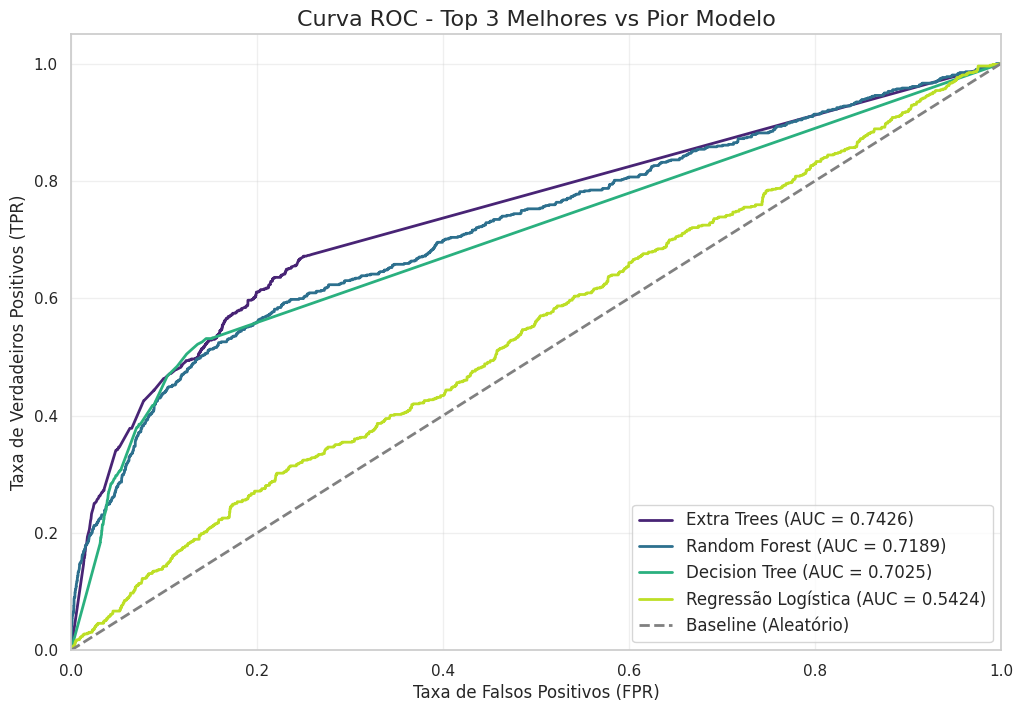

In [ ]:
# 1. Melhores modelos de calsiificação

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Configurar o tamanho do gráfico
plt.figure(figsize=(12, 8))

# Lista para armazenar os dados de cada modelo para ordenação posterior
roc_data = []

# Iterar sobre todos os modelos treinados no dicionário
for name, model in models.items():
    try:
        # Obter as probabilidades para a classe positiva (Mau Pagador = 1)
        # Usar X_test_processed em vez de X_test_raw
        y_prob = model.predict_proba(X_test_processed)[:, 1]

        # Calcular a Taxa de Falsos Positivos (FPR) e a Taxa de Verdadeiros Positivos (TPR)
        fpr, tpr, thresholds = roc_curve(y_test, y_prob)

        # Calcular a área sob a curva (AUC)
        roc_auc = auc(fpr, tpr)

        # Adicionar aos dados
        roc_data.append({'name': name, 'fpr': fpr, 'tpr': tpr, 'auc': roc_auc})

    except AttributeError:
        # Caso algum modelo não suporte predict_proba
        print(f"O modelo {name} não suporta o cálculo de probabilidades e foi ignorado.")

# Ordenar os dados pela AUC do maior para o menor
roc_data_sorted = sorted(roc_data, key=lambda x: x['auc'], reverse=True)

# Selecionar os 3 melhores e o pior modelo
selected_models = roc_data_sorted[:3] + [roc_data_sorted[-1]]

# Configurar a paleta de cores viridis
cmap = plt.get_cmap('viridis')
colors = [cmap(i) for i in np.linspace(0.1, 0.9, len(selected_models))]

# Plotar as curvas usando os modelos selecionados e as cores da paleta
for data, color in zip(selected_models, colors):
    plt.plot(data['fpr'], data['tpr'], color=color, lw=2, label=f"{data['name']} (AUC = {data['auc']:.4f})")

# Adicionar a linha de baseline (chute aleatório)
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Baseline (Aleatório)')

# Configurações estéticas do gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falsos Positivos (FPR)', fontsize=12)
plt.ylabel('Taxa de Verdadeiros Positivos (TPR)', fontsize=12)
plt.title('Curva ROC - Top 3 Melhores vs Pior Modelo', fontsize=16)
plt.legend(loc="lower right", fontsize=12)
plt.grid(alpha=0.3)
plt.show()


Curva ROC evidencia que o Extra Trees, Random Forest e Decision Tree possuem os melhores índices.

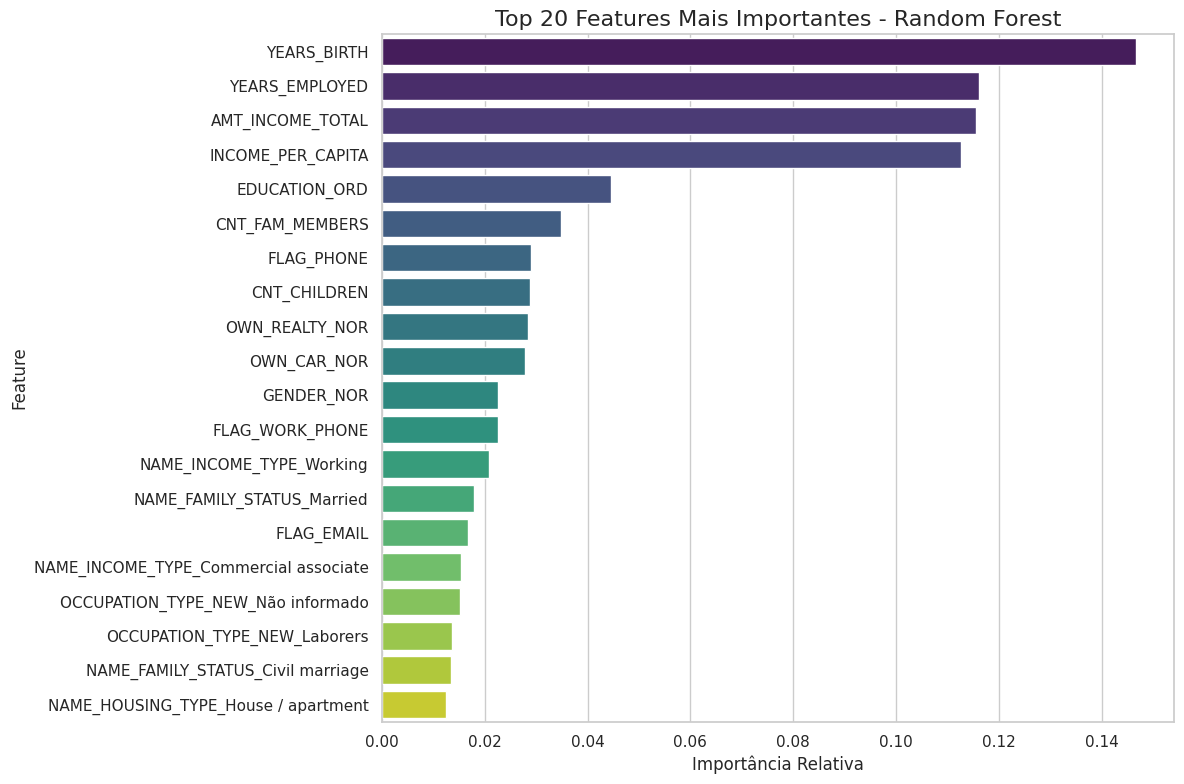

In [ ]:
# 2. Principais Features do melhor modelo - (Random Forest)

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# O modelo Random Forest já está treinado no dicionário 'models'
# rf_model = models['XGBoost']
rf_model = models['Random Forest']

# Obter as importâncias das features
importances = rf_model.feature_importances_

# Criar um DataFrame para organizar as importâncias
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Visualizar as 20 features mais importantes
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', hue='Feature', data=feature_importance_df.head(20), palette='viridis', legend=False)
plt.title('Top 20 Features Mais Importantes - Random Forest', fontsize=16)
plt.xlabel('Importância Relativa')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Grafico acima mostra que idade em anos, anos empregados, renda e renda per capita foram as variáveis mais importantes.

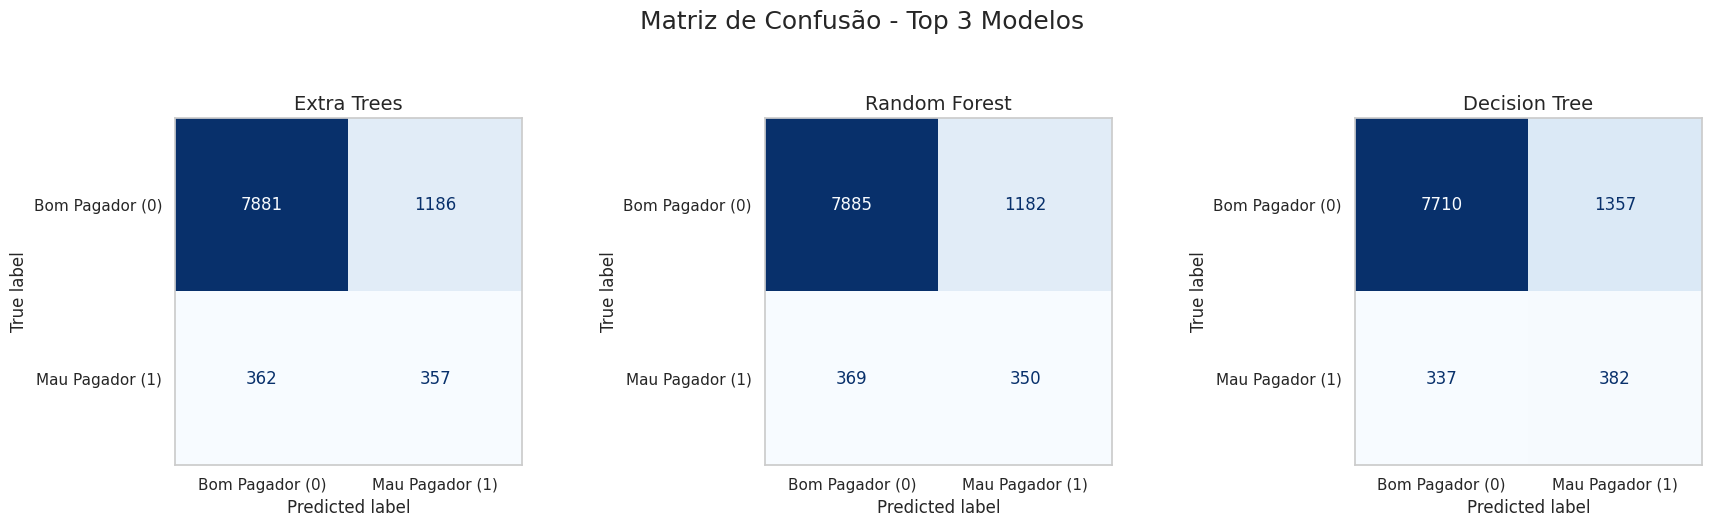

In [ ]:
# 3. Matriz de confusão dos top 3 models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Selecionar dinamicamente os nomes dos 3 melhores modelos baseados na área sob a curva (AUC)
top_3_model_names = [data['name'] for data in roc_data_sorted[:3]]

# Configurar a figura para ter 3 subplots lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, model_name in enumerate(top_3_model_names):
    # Obter o modelo do dicionário
    model = models[model_name]

    # Fazer predições no conjunto de teste usando os dados PROCESSADOS
    y_pred = model.predict(X_test_processed)

    # Calcular a matriz de confusão
    cm = confusion_matrix(y_test, y_pred)

    # Plotar a matriz no respectivo subplot
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Bom Pagador (0)', 'Mau Pagador (1)'])
    disp.plot(cmap='Blues', values_format='d', ax=axes[i], colorbar=False)

    axes[i].set_title(f'{model_name}', fontsize=14)
    axes[i].grid(False)

# Adicionar um título principal e ajustar o layout
plt.suptitle('Matriz de Confusão - Top 3 Modelos', fontsize=18, y=1.05)
plt.tight_layout()
plt.show()


Matriz de confusão dos modelos com as melhores métricas

## 3.4 Validação cruzada

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
import numpy as np
import pandas as pd

# Selecionar os 3 melhores modelos para a validação cruzada
top_3_names = ['Random Forest', 'Extra Trees', 'XGBoost']

# Configurar a validação cruzada estratificada (5 folds)
# Isso garante que a proporção de classes seja mantida em cada fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []

print("Iniciando Validação Cruzada (5 Folds) no conjunto de treinamento...")
print("(Isso pode levar alguns instantes)\n")

for name in top_3_names:
    model = models[name]
    print(f"Avaliando {name}...")

    # Executar a validação cruzada usando F1-Score como métrica
    # Usamos os dados processados e balanceados (X_train_resampled e y_train_resampled)
    scores = cross_val_score(model, X_train_resampled, y_train_resampled, cv=skf, scoring='f1', n_jobs=-1)

    cv_results.append({
        'Modelo': name,
        'F1-Score (Média)': np.mean(scores),
        'Desvio Padrão': np.std(scores),
        'Scores Individuais': np.round(scores, 4)
    })

# Exibir os resultados
cv_results_df = pd.DataFrame(cv_results)
print("\n=== Resultados da Validação Cruzada ===")
display(cv_results_df)


Iniciando Validação Cruzada (5 Folds) no conjunto de treinamento...
(Isso pode levar alguns instantes)

Avaliando Random Forest...
Avaliando Extra Trees...
Avaliando XGBoost...

=== Resultados da Validação Cruzada ===


,Modelo,F1-Score (Média),Desvio Padrão,Scores Individuais
0,Random Forest,0.9378,0.0024,"[0.9387, 0.9416, 0.9383, 0.9345, 0.9359]"
1,Extra Trees,0.9224,0.0023,"[0.9231, 0.9208, 0.9219, 0.9265, 0.9197]"
2,XGBoost,0.8986,0.0042,"[0.8979, 0.8914, 0.8987, 0.9039, 0.9014]"


## 3.5 Otimização de Hiperparâmetros com RandomizedSearchCV

Vamos otimizar o **Random Forest** (nosso melhor modelo na avaliação) iterando sobre uma grade de hiperparâmetros selecionados aleatoriamente para maximizar o F1-Score.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Definindo as distribuições de parâmetros para os modelos candidatos
param_grids = {
    'Random Forest': {
        'n_estimators': [100, 200, 300, 400, 500],
        'max_depth': [10, 15, 20, 25, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'class_weight': ['balanced', pesos_classe]
    },
    'XGBoost': {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [3, 5, 7, 10],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0]
    }
}

# Modelos base
base_models = {
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight_base, eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1)
}

# Dicionário para armazenar os modelos ajustados pelo RandomizedSearchCV
modelos_otimizados = {}

print("Iniciando otimização com RandomizedSearchCV para Random Forest e XGBoost...\n")

for name, model in base_models.items():
    print(f"Otimizando {name}...")
    random_search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grids[name],
        n_iter=10,
        scoring='f1',
        cv=skf,
        verbose=1,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    random_search.fit(X_train_resampled, y_train_resampled) # Usando a base tratada pelo SMOTE se necessário, ou X_train
    modelos_otimizados[name] = random_search.best_estimator_

    print(f"[{name}] Melhor F1-Score: {random_search.best_score_:.4f}")
    print(f"[{name}] Melhores parâmetros: {random_search.best_params_}\n")

# Agora você pode usar `modelos_otimizados` para a avaliação final e simuladores
models.update(modelos_otimizados)
rf_best = modelos_otimizados['Random Forest']


Iniciando otimização com RandomizedSearchCV para Random Forest e XGBoost...

Otimizando Random Forest...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[Random Forest] Melhor F1-Score: 0.9378
[Random Forest] Melhores parâmetros: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 25, 'class_weight': 'balanced'}

Otimizando XGBoost...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[XGBoost] Melhor F1-Score: 0.8986
[XGBoost] Melhores parâmetros: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 1.0}



### 3.5.1 Avaliação do Modelo Otimizado

Visualização da Matriz de Confusão e da Curva ROC para o modelo Random Forest após a otimização de hiperparâmetros.

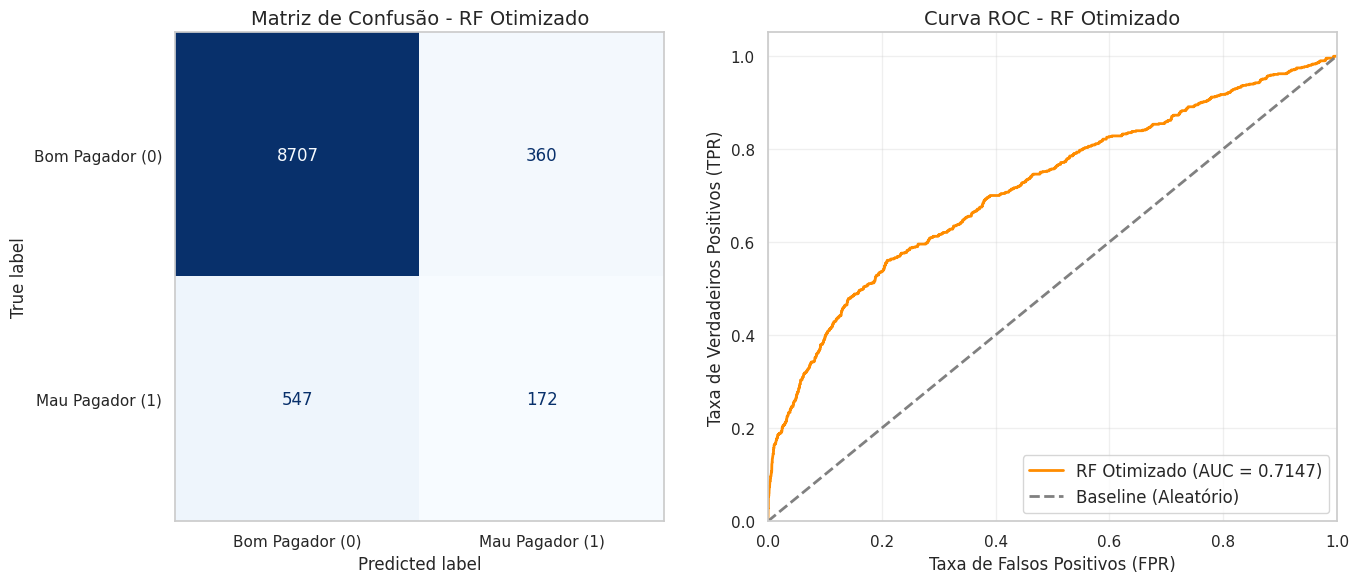

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# Recuperando o melhor modelo otimizado (Random Forest)
best_rf = modelos_otimizados['Random Forest']

# Predições e Probabilidades no conjunto de teste processado
y_pred_best = best_rf.predict(X_test_processed)
y_prob_best = best_rf.predict_proba(X_test_processed)[:, 1]

# Configurando a figura com 2 subplots (1 linha, 2 colunas)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Subplot 1: Matriz de Confusão ---
cm_best = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=['Bom Pagador (0)', 'Mau Pagador (1)'])
disp.plot(cmap='Blues', values_format='d', ax=axes[0], colorbar=False)
axes[0].set_title('Matriz de Confusão - RF Otimizado', fontsize=14)
axes[0].grid(False)

# --- Subplot 2: Curva ROC ---
fpr_best, tpr_best, _ = roc_curve(y_test, y_prob_best)
roc_auc_best = auc(fpr_best, tpr_best)

axes[1].plot(fpr_best, tpr_best, color='darkorange', lw=2, label=f'RF Otimizado (AUC = {roc_auc_best:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Baseline (Aleatório)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Taxa de Falsos Positivos (FPR)', fontsize=12)
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (TPR)', fontsize=12)
axes[1].set_title('Curva ROC - RF Otimizado', fontsize=14)
axes[1].legend(loc="lower right", fontsize=12)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


Random Forest apresentou um bom percencual de VP e VN levando em conta o desbalanceamento da base.

## 3.6 Simuladores

In [ ]:
# 1. Definir o limite de risco (threshold) -
limite_risco = 0.08

# 2. Criar dados fictícios para 3 novos clientes seguindo a estrutura exata de X (18 colunas)
novos_clientes = pd.DataFrame({
    'YEARS_BIRTH': [45.0, 25.0, 35.0],
    'CNT_CHILDREN': [0, 2, 0],
    'CNT_FAM_MEMBERS': [2.0, 4.0, 1.0],
    'AMT_INCOME_TOTAL': [350000.0, 45000.0, 120000.0],
    'INCOME_PER_CAPITA': [175000.0, 11250.0, 120000.0],
    'YEARS_EMPLOYED': [10.0, 2.0, 0.0],
    'NAME_FAMILY_STATUS': ['Married', 'Married', 'Single / not married'],
    'NAME_INCOME_TYPE': ['Working', 'Working', 'Pensioner'],
    'OCCUPATION_TYPE_NEW': ['Accountants', 'Laborers', 'Não informado'],
    'NAME_HOUSING_TYPE': ['House / apartment', 'Rented apartment', 'House / apartment'],
    'GENDER_NOR': [1, 0, 0],
    'IS_RETIRED': [0, 0, 1],
    'EDUCATION_ORD': [4, 2, 4], # Higher education e Secondary
    'FLAG_WORK_PHONE': [0, 1, 0],
    'FLAG_PHONE': [1, 0, 0],
    'FLAG_EMAIL': [1, 0, 0],
    'OWN_CAR_NOR': [1, 0, 1],
    'OWN_REALTY_NOR': [1, 0, 1]
})

print("=== Perfil dos Novos Clientes (Entrada) ===")
display(novos_clientes[['YEARS_BIRTH', 'AMT_INCOME_TOTAL', 'YEARS_EMPLOYED', 'OCCUPATION_TYPE_NEW', 'NAME_FAMILY_STATUS']])

# 3. Aplicar o pré-processamento (preprocessor ajustado anteriormente)
novos_clientes_processed = preprocessor.transform(novos_clientes)

# 4. Fazer as previsões com o Random Forest (usando apenas probabilidades agora)
rf_model = models['Random Forest']
probabilidades = rf_model.predict_proba(novos_clientes_processed)
probs_bom_pagador = probabilidades[:, 0]
probs_mau_pagador = probabilidades[:, 1]

# 5. Consolidar e exibir os resultados com o threshold customizado
resultados_df = novos_clientes.copy()
resultados_df['PROB_BOM_PAGADOR (%)'] = (probs_bom_pagador * 100).round(2)
resultados_df['PROB_MAU_PAGADOR (%)'] = (probs_mau_pagador * 100).round(2)

# Aplicando cortes diferentes para comparação
resultados_df['PREVISÃO PADRÃO (Corte 50%)'] = ['Mau Pagador' if p >= 0.50 else 'Bom Pagador' for p in probs_mau_pagador]
resultados_df[f'NOVA PREVISÃO (Corte {limite_risco*100}%)'] = ['Mau Pagador (Alto Risco)' if p >= limite_risco else 'Bom Pagador (Baixo Risco)' for p in probs_mau_pagador]

print(f"\n=== Resultado das Previsões (Threshold Customizado: {limite_risco*100}%) ===")
display(resultados_df[['YEARS_BIRTH', 'AMT_INCOME_TOTAL', 'PROB_BOM_PAGADOR (%)', 'PROB_MAU_PAGADOR (%)', 'PREVISÃO PADRÃO (Corte 50%)', f'NOVA PREVISÃO (Corte {limite_risco*100}%)']])

=== Perfil dos Novos Clientes (Entrada) ===


,YEARS_BIRTH,AMT_INCOME_TOTAL,YEARS_EMPLOYED,OCCUPATION_TYPE_NEW,NAME_FAMILY_STATUS
0,45.0000,350000.0000,10.0000,Accountants,Married
1,25.0000,45000.0000,2.0000,Laborers,Married
2,35.0000,120000.0000,0.0000,Não informado,Single / not married



=== Resultado das Previsões (Threshold Customizado: 8.0%) ===


,YEARS_BIRTH,AMT_INCOME_TOTAL,PROB_BOM_PAGADOR (%),PROB_MAU_PAGADOR (%),PREVISÃO PADRÃO (Corte 50%),NOVA PREVISÃO (Corte 8.0%)
0,45.0000,350000.0000,94.0800,5.9200,Bom Pagador,Bom Pagador (Baixo Risco)
1,25.0000,45000.0000,85.4600,14.5400,Bom Pagador,Mau Pagador (Alto Risco)
2,35.0000,120000.0000,77.8100,22.1900,Bom Pagador,Mau Pagador (Alto Risco)


#### 1 - Análise do Ponto de Corte (Threshold de Risco) Personalizado

Na concessão de crédito, a escolha do limite de risco (threshold) é uma decisão estratégica crucial que dita o equilíbrio entre a rentabilidade (volume de aprovações) e a inadimplência (perdas financeiras).

Nesta simulação, avaliamos **3 clientes fictícios** sob dois cenários de decisão utilizando o modelo **Random Forest**:

1. **Ponto de Corte Padrão (50%):**
   * Sob a regra padrão adotada pela maioria dos algoritmos estatísticos básicos, um cliente só é barrado se sua probabilidade de inadimplência (Mau Pagador) ultrapassar **50%**.
   * **Resultado:** Todos os três novos proponentes seriam aprovados, pois as probabilidades calculadas de risco foram inferiores a 50% para todos eles. Isso exporia a instituição a um risco latente de crédito.

2. **Ponto de Corte Conservador Personalizado (8%):**
   * Considerando que uma taxa de inadimplência de quase 1 a cada 10 clientes é extremamente prejudicial para a saúde financeira da instituição, estabelecemos um apetite ao risco máximo de **8%** de probabilidade de default.
   * **Resultados Individuais sob a Nova Régua:**
     * **Cliente 1 (45 anos, Renda de 350k, 10 anos de emprego):** Teve um risco calculado de **5.92%**. Como este valor está abaixo da nossa tolerância de 8%, ele é classificado como **Bom Pagador (Baixo Risco)** e sua linha de crédito é aprovada.
     * **Cliente 2 (25 anos, Renda de 45k, 2 anos de emprego):** Apresentou uma probabilidade de inadimplência de **14.54%**. Sob a régua padrão seria aceito, mas sob o novo critério de 8% foi corretamente classificado como **Mau Pagador (Alto Risco)** e teve a aprovação negada devido à combinação de baixa idade e renda incompatível.
     * **Cliente 3 (35 anos, Renda de 120k, 0 anos de emprego):** Obteve um risco calculado de **22.19%**. Sob nossa régua estrita, foi classificado como **Mau Pagador (Alto Risco)**, indicando que a falta de tempo de estabilidade no emprego atual representa um sinalizador forte de risco para a carteira.

**Conclusão de Negócio:**
Ajustar a probabilidade estatística gerada pelo modelo estatístico (`predict_proba`) às políticas e ao apetite de risco da empresa (`limite_risco`) é indispensável para mitigar prejuízos operacionais na implantação real de sistemas de concessão de crédito.

# 04 - Análise final

### 4.1 - Análise Final e Conclusão dos Modelos

Após rigoroso pipeline de pré-processamento, aplicação de técnicas de balanceamento (SMOTE) e treinamento com validação cruzada, submetemos os dados a diversos algoritmos de *Machine Learning* e aplicamos otimização de hiperparâmetros (`RandomizedSearchCV`) aos principais candidatos.

**1. Os Campeões de Performance:**
A abordagem baseada em árvores de decisão e *ensembles* demonstrou superioridade nos nossos dados.
* **Extra Trees e Random Forest:** Consagraram-se como os melhores modelos. O Extra Trees obteve a maior métrica **ROC AUC (~0.74)** seguido de perto pelo Random Forest **(~0.72)** no conjunto de teste, provando melhor capacidade de distinção entre Bons e Maus Pagadores em comparação aos demais modelos. Na validação cruzada interna, os modelos baseados em árvore chegaram a demonstrar altíssimo F1-Score (acima de 0.90), embora o desempenho no teste real revele a complexidade de generalização do problema.
* **Otimização Avançada:** O uso de `RandomizedSearchCV` em modelos como Regressão Logística, Random Forest e XGBoost permitiu refinar hiperparâmetros, extraindo o melhor potencial de cada arquitetura para as camadas de decisão.

**2. O Ponto de Alerta:**
Modelos lineares mais simples, como a **Regressão Logística**, obtiveram os piores resultados (AUC de ~0.54, quase equivalente a um chute aleatório). Isso constata categoricamente que a dinâmica que dita a concessão de crédito nestes dados carrega padrões complexos e não-lineares, que equações retas não conseguem capturar.

**3. O que define o risco de crédito? (Feature Importance):**
Avaliando a "caixa preta" do nosso modelo base, identificamos que os fatores primordiais (Top 4) para a definição do risco são fortemente demográficos e relacionados a poder aquisitivo:
1. `YEARS_BIRTH`: A idade do proponente.
2. `YEARS_EMPLOYED`: O tempo de estabilidade no trabalho atual.
3. `AMT_INCOME_TOTAL`: O poder de renda total.
4. `INCOME_PER_CAPITA`: A renda per capita da estrutura familiar.

**4. Valor de Negócio e o Simulador de Crédito:**
Por fim, nosso simulador demonstrou que as saídas padrão dos algoritmos de ML (Threshold de 50% de probabilidade para aprovar ou negar) costumam ser liberais e "ingênuas" demais em mercados de alta volatilidade financeira, deixando passar propostas com risco oculto latente.

Ao ajustarmos o **ponto de corte (Threshold) para 8%** (tolerância de risco ajustada), fomos capazes de converter o classificador em uma ferramenta conservadora e precisa na medida do negócio: barrando proponentes que teriam sido "erroneamente aprovados" pelo corte padrão (como o caso do cliente simulado com baixíssimo tempo de emprego e o cliente jovem com renda incompatível), preservando o caixa da instituição e estreitando os laços da Inteligência Artificial com as políticas preventivas do comitê de crédito.